<a href="https://colab.research.google.com/github/Ferdisalah/LPCVC_2026/blob/main/tutorial_model_ensembling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# In-class Competition Tutorial (Model Ensembling)
Building on tutorial_feature_engineering.ipynb, this notebook trains multiple gradient boosting tree models and ensembles them to improve performance (ROC-AUC).

First, let's review the task we will be performing (see README.ipynb for details).

**Objective**: To predict the probability of default based on customer data.

**Evaluation metric**: ROC-AUC (Area Under the Receiver Operating Characteristic Curve)

## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Advanced Feature Engineering](#scrollTo=GcaW-7a7ctm1&line=1&uniqifier=1)
- [6.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [7.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

### 1.1 Import Libraries
Let's load basic libraries.
Other required libraries will be loaded when we explain them.
- numpy: Library for efficient numerical computation
- pandas: Library useful for data analysis
- matplotlib: Graph drawing library
- seaborn: Graph drawing library as well

In [2]:
# Loading libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1.2 Connect with Google Drive
To load the data, we first need to connect this Colab notebook with Google Drive.

In [3]:
# If you work with Google Colaboratory, please run this as well.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Next, we need to navigate to where the `competition` folder is located

**IMPORTANT**:<br>
Change the path in the `%cd` command below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Examples:
- You uploaded `competition` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/<wbr>content/drive/MyDrive/competition"
- You uploaded `competition` folder inside a folder named `00_GCIWorld` under MyDrive
    - Change to "/<wbr>content/drive/MyDrive/00_GCIWorld/competition"

You can easily locate your notebook's directory by:
1. Open the Files panel on the left side of Colab
2. Navigate through the "drive" and "MyDrive" folders until you find your notebook's folders
3. Click the more actions icon (three vertical dots, $\vdots$) next to the folder name
4. Select the option "Copy path"

In [4]:
%cd "/content/drive/MyDrive/Competition"

import os
from pathlib import Path

current_dir = Path(os.getcwd())

train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"
ROOT_DIR = Path("/content/drive/MyDrive/Competition")
OUTPUT_ROOT = ROOT_DIR / "output"

print("Working directory:", current_dir)
print("Train exists:", train_file.exists())
print("Test exists:", test_file.exists())

/content/drive/MyDrive/Competition
Working directory: /content/drive/MyDrive/Competition
Train exists: True
Test exists: True


In [5]:
import pandas as pd
from pathlib import Path

sample_sub_file = current_dir / "input" / "sample_submission.csv"

reference_file = current_dir / "home_credit_three_groups_cv5.py"
generator_file = current_dir / "generate_top20_growpolicy_scripts.py"

print("Sample submission exists:", sample_sub_file.exists())
print("Reference script exists:", reference_file.exists())
print("Generator exists:", generator_file.exists())

if sample_sub_file.exists():
    sample_sub = pd.read_csv(sample_sub_file)
    print("\nSample submission shape:", sample_sub.shape)
    print("Columns:", sample_sub.columns.tolist())
    print(sample_sub.head())

Sample submission exists: True
Reference script exists: True
Generator exists: False

Sample submission shape: (61500, 2)
Columns: ['SK_ID_CURR', 'TARGET']
   SK_ID_CURR  TARGET
0      171202     0.5
1      171203     0.5
2      171204     0.5
3      171205     0.5
4      171206     0.5


In [6]:
from google.colab import drive, files
from pathlib import Path
import shutil

drive.mount('/content/drive')

ROOT_DIR = Path("/content/drive/MyDrive/Competition")

uploaded = files.upload()

generator_name = "generate_top20_colab_scripts.py"

if generator_name not in uploaded:
    raise FileNotFoundError("Please upload generate_top20_colab_scripts.py")

shutil.move(
    f"/content/{generator_name}",
    str(ROOT_DIR / generator_name)
)

print("Generator installed:", (ROOT_DIR / generator_name).exists())
print("Reference exists:", (ROOT_DIR / "home_credit_three_groups_cv5.py").exists())
print("Train exists:", (ROOT_DIR / "input/train.csv").exists())
print("Test exists:", (ROOT_DIR / "input/test.csv").exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


KeyboardInterrupt: 

In [7]:
from pathlib import Path
import shutil
import subprocess
import sys

ROOT_DIR = Path("/content/drive/MyDrive/Competition")

# البحث عن الملف المرفوع، سواء بالاسم الأصلي أو مع (1)
search_dirs = {
    Path.cwd(),
    Path("/content"),
    ROOT_DIR,
}

candidates = []

for folder in search_dirs:
    if folder.exists():
        candidates.extend(
            p for p in folder.glob("generate_top20_colab_scripts*.py")
            if p.is_file()
        )

# إزالة المسارات المكررة
candidates = list({p.resolve() for p in candidates})

if not candidates:
    raise FileNotFoundError(
        "Could not find generate_top20_colab_scripts*.py"
    )

# اختيار أحدث نسخة مرفوعة
source_file = max(candidates, key=lambda p: p.stat().st_mtime)

destination = ROOT_DIR / "generate_top20_colab_scripts.py"

if source_file != destination.resolve():
    shutil.copy2(source_file, destination)

print("Source file:", source_file)
print("Installed as:", destination)
print("File size:", destination.stat().st_size, "bytes")

# تشغيل المولّد دون بدء التدريب
result = subprocess.run(
    [sys.executable, str(destination)],
    cwd=str(ROOT_DIR),
    capture_output=True,
    text=True
)

print("\nGENERATOR OUTPUT:")
print(result.stdout)

if result.returncode != 0:
    print("\nERROR:")
    print(result.stderr)
    raise RuntimeError("Script generation failed.")

# التحقق من إنشاء النسختين
for name in [
    "home_credit_top20_depthwise_cv5.py",
    "home_credit_top20_lossguide_cv5.py",
]:
    path = ROOT_DIR / name
    print(name, "->", path.exists())

    if not path.exists():
        raise RuntimeError(f"Missing generated script: {name}")

print("\nBoth scripts generated and syntax-checked successfully.")

Source file: /content/drive/MyDrive/Competition/generate_top20_colab_scripts.py
Installed as: /content/drive/MyDrive/Competition/generate_top20_colab_scripts.py
File size: 14694 bytes

GENERATOR OUTPUT:
Reference: /content/drive/MyDrive/Competition/home_credit_three_groups_cv5.py
Reference bytes: 47856
Created: /content/drive/MyDrive/Competition/home_credit_top20_depthwise_cv5.py
Bytes: 51039
Python syntax: VALID
Created: /content/drive/MyDrive/Competition/home_credit_top20_lossguide_cv5.py
Bytes: 51039
Python syntax: VALID

Generation complete. No model training was started.
Input files were not modified.

home_credit_top20_depthwise_cv5.py -> True
home_credit_top20_lossguide_cv5.py -> True

Both scripts generated and syntax-checked successfully.


In [ ]:
from pathlib import Path
import ast
import os

ROOT_DIR = Path("/content/drive/MyDrive/Competition")

scripts = [
    ROOT_DIR / "home_credit_top20_depthwise_cv5.py",
    ROOT_DIR / "home_credit_top20_lossguide_cv5.py",
]

print("Available CPU cores:", os.cpu_count())

for path in scripts:
    if not path.exists():
        raise FileNotFoundError(path)

    source = path.read_text(encoding="utf-8")

    old = 'TASK_TYPE = "GPU"'
    new = 'TASK_TYPE = "CPU"'

    if source.count(old) != 1:
        raise RuntimeError(
            f"Expected one GPU configuration in {path.name}; "
            f"found {source.count(old)}"
        )

    source = source.replace(old, new, 1)

    # Verify Python syntax before saving.
    ast.parse(source)

    # Verify CPU branches for CV and final refit.
    assert 'params["thread_count"] = -1' in source
    assert 'final_params["thread_count"] = -1' in source

    path.write_text(source, encoding="utf-8")

    print(f"\n{path.name}")
    print("TASK_TYPE: CPU")
    print("CPU threads: All available")
    print("Syntax: VALID")

In [ ]:
for path in scripts:
    source = path.read_text(encoding="utf-8")

    print("\n", path.name)
    for line in source.splitlines():
        if (
            line.startswith("TASK_TYPE =")
            or line.startswith("GROW_POLICY =")
            or line.startswith("MAX_LEAVES =")
            or line.startswith("MIN_DATA_IN_LEAF =")
        ):
            print(line)

In [ ]:
import os
import sys
import ast
import subprocess
from pathlib import Path

ROOT_DIR = Path("/content/drive/MyDrive/Competition")
OUTPUT_ROOT = ROOT_DIR / "output"

jobs = [
    {
        "policy": "depthwise",
        "script": ROOT_DIR / "home_credit_top20_depthwise_cv5.py",
        "output": OUTPUT_ROOT / "depthwise",
        "log": OUTPUT_ROOT / "depthwise" / "training.log",
        "model": "best_catboost_top20_depthwise.cbm",
    },
    {
        "policy": "lossguide",
        "script": ROOT_DIR / "home_credit_top20_lossguide_cv5.py",
        "output": OUTPUT_ROOT / "lossguide",
        "log": OUTPUT_ROOT / "lossguide" / "training.log",
        "model": "best_catboost_top20_lossguide.cbm",
    },
]

# ---------------------------------------------------------
# Preflight verification
# ---------------------------------------------------------
for job in jobs:
    path = job["script"]

    if not path.exists():
        raise FileNotFoundError(path)

    source = path.read_text(encoding="utf-8")
    ast.parse(source)

    expected_policy = job["policy"].title()

    if f'GROW_POLICY = "{expected_policy}"' not in source:
        raise RuntimeError(f"Wrong grow policy in {path.name}")

    if 'TASK_TYPE = "CPU"' not in source:
        raise RuntimeError(f"{path.name} is not configured for CPU.")

    if "final_model.fit(" not in source:
        raise RuntimeError("Final full-data refit is missing.")

    if "submission = sample_sub.copy()" not in source:
        raise RuntimeError("Sample-submission template handling is missing.")

    job["output"].mkdir(parents=True, exist_ok=True)

    # Correct the outdated comment; it does not affect execution.
    source = source.replace(
        'TASK_TYPE = "CPU"  # Keep GPU for comparability with the preceding experiments.',
        'TASK_TYPE = "CPU"  # Google Colab CPU runtime.',
        1,
    )
    path.write_text(source, encoding="utf-8")

print("Preflight verification passed.")
print("CPU cores:", os.cpu_count())
print("Training order: Depthwise -> Lossguide")
print("Each policy has a separate output folder.")

# ---------------------------------------------------------
# Sequential training
# ---------------------------------------------------------
for job in jobs:

    print("\n" + "=" * 75)
    print(f"STARTING {job['policy'].upper()}")
    print("=" * 75, flush=True)

    process = subprocess.Popen(
        [sys.executable, "-u", str(job["script"])],
        cwd=str(ROOT_DIR),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    with open(job["log"], "a", encoding="utf-8") as log_file:
        for line in process.stdout:
            print(line, end="", flush=True)
            log_file.write(line)
            log_file.flush()

    return_code = process.wait()

    if return_code != 0:
        raise RuntimeError(
            f"{job['policy']} failed with exit code {return_code}. "
            f"Log: {job['log']}. "
            "The next policy was not started."
        )

    # -----------------------------------------------------
    # Verify final artifacts before moving to next policy
    # -----------------------------------------------------
    expected_files = [
        job["output"] / "submission.csv",
        job["output"] / job["model"],
        job["output"] / f"cv5_top20_{job['policy']}_summary.csv",
        job["output"] / f"cv5_top20_{job['policy']}_fold_metrics.csv",
        job["output"] / f"cv5_top20_{job['policy']}_oof_predictions.csv.gz",
        job["output"] / f"best_feature_subset_top20_{job['policy']}.json",
    ]

    missing = [str(p) for p in expected_files if not p.is_file()]

    if missing:
        raise RuntimeError(
            f"{job['policy']} completed, but expected artifacts are missing:\n"
            + "\n".join(missing)
        )

    print(f"\n{job['policy'].upper()} COMPLETED SUCCESSFULLY.")
    for path in expected_files:
        print("Saved:", path)

print("\n" + "=" * 75)
print("BOTH MODELS COMPLETED SUCCESSFULLY")
print("=" * 75)
print("Depthwise submission:", OUTPUT_ROOT / "depthwise" / "submission.csv")
print("Lossguide submission:", OUTPUT_ROOT / "lossguide" / "submission.csv")

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

MYDRIVE = Path("/content/drive/MyDrive")

print("MyDrive exists:", MYDRIVE.exists())

if MYDRIVE.exists():
    print("\nMyDrive folders:")
    for p in MYDRIVE.iterdir():
        if p.is_dir():
            print("📁", p.name)

    print("\nPython files in MyDrive/Competition:")
    competition_dir = MYDRIVE / "Competition"

    if competition_dir.exists():
        for p in competition_dir.glob("*.py"):
            print("📄", p.name)
    else:
        print("Competition folder does not exist.")

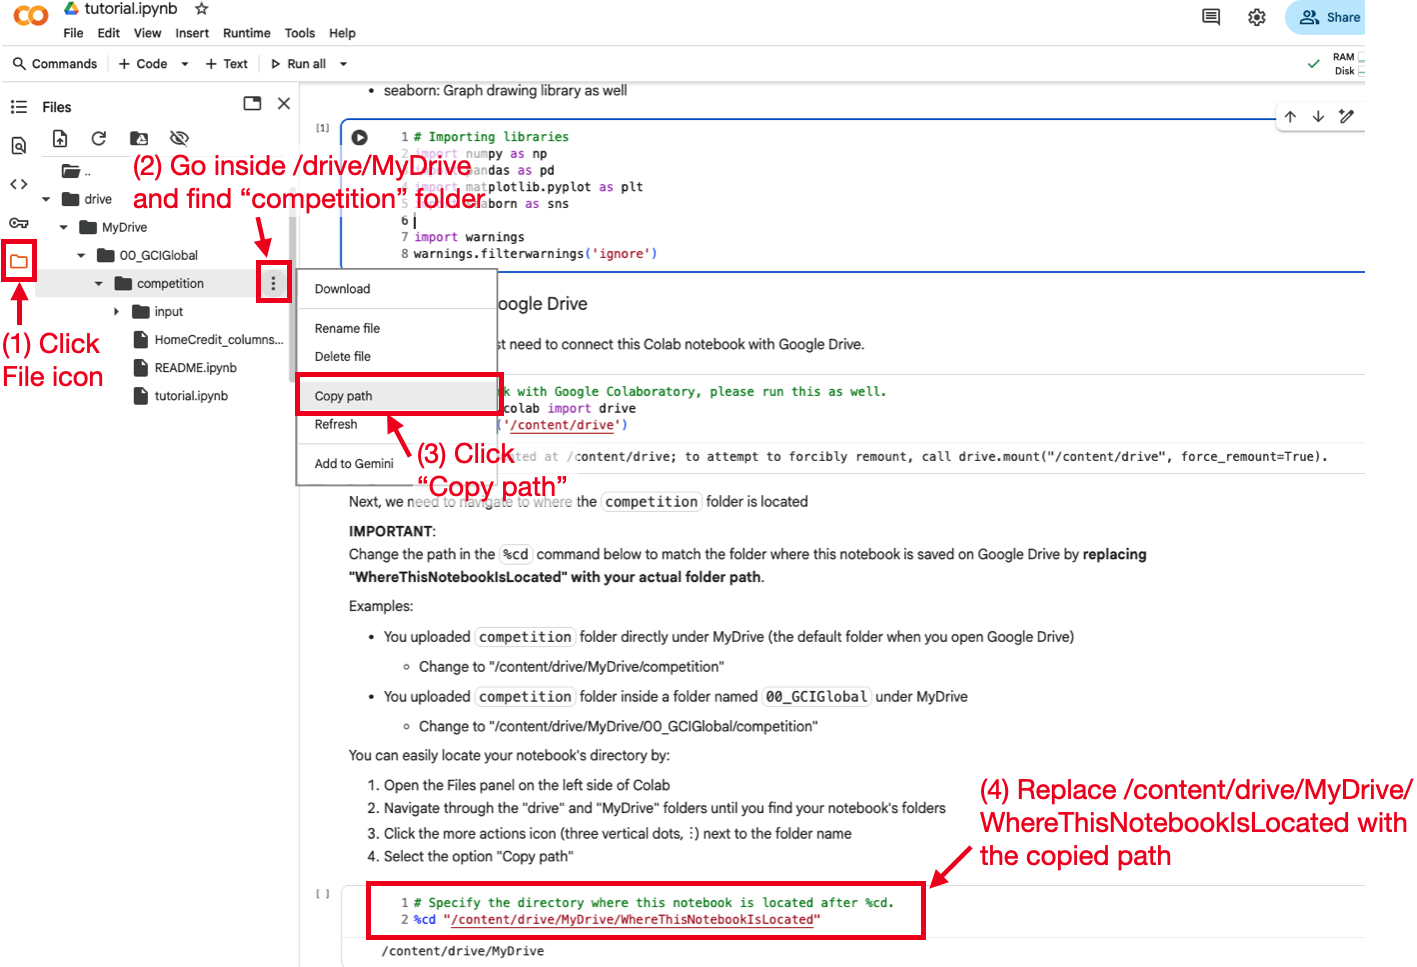

Run the cell below to check if the path is correctly set.

In [ ]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

In [9]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

Before conducting a full-scale analysis, we will first review a brief overview of the data.

In [ ]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

In [ ]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

Excluding the `TARGET` column in train data and the `SK_ID_CURR` which represents ID number, you can see that there are 32 types of features.

###This time, we'll review all candidate features and use the majority in our model.

## 3.Visualizing and Understanding the Data

The first thing we need to do before building the machine learning model is to **understand the data**. We do this by visualizing and analyzing, to deepen our understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all important to building models with better prediction ability.

### 3.1 Checking missing values
In this section, we check for missing values.
This is important as **most machine learning models cannot be trained on data with missing values**. If there are missing values, they need to be filled with some value.

In [ ]:
# Check missing values of train data
train.isnull().sum()

In [ ]:
# Check missing values of test data
test.isnull().sum()

We found that there are missing values in OWN_CAR_AGE, CNT_FAM_MEMBERS, EXT_SOURCE_\*, AMT_REQ_CREDIT_BUREAU_\*. We will deal with these missing values later.

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

#### TARGET column

In [ ]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()

We can see that the **distribution of the objective variable is highly skewed**. Data in which the distribution of the objective variable is highly skewed in this way is called **unbalanced data**.

When dealing with unbalanced data, we need to be particularly careful in selecting evaluation metrics. For example, if you choose accuracy, you will find that simply predicting all zeros will result in a high accuracy. **Choosing such an inappropriate metric can cause the machine learning model to fail to predict well on new data**.

Another approach to dealing with unbalanced data is to try to balance the distribution of the target variable. The method of reducing the data of the larger target variable is called undersampling, while the method of increasing the data of the smaller objective variable is called oversampling.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable

#### NAME_CONTRACT_TYPE column

In [ ]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

There are two variables in NAME_CONTRACT_TYPE, Cash loans and Revolving loans, but they are not evenly distributed. Also, since the machine learning model can only handle data of numeric type, it is necessary to convert the data from string type to numeric type.

In [ ]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable
* Need to convert the data from string type to numeric type

#### ORGANIZATION_TYPE column

In [ ]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different ORGANIZATION_TYPEs, and you can also see that there is an ununiformity in the number of data. This is also a string type feature, so it needs to be converted to a numeric type. Also, the second variable from the left is “XNA,” which we can infer from its name to be a missing value.


**Findings**:<br>
* Treat "XNA" as missing values
* Need to convert the data from string type to numeric type

#### EXT_SOURCE_1 column

In [ ]:
# The distribution of EXT_SOURCE_1
sns.displot(data=train, x="EXT_SOURCE_1")
plt.show()

#### EXT_SOURCE_2 column

In [ ]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

#### EXT_SOURCE_3 column

In [ ]:
# The distribution of EXT_SOURCE_3
sns.displot(data=train, x="EXT_SOURCE_3")
plt.show()

We can see that EXT_SOURCE_\* is normalized between 0 and 1. It seems we can handle this feature as it is.

**Findings**:<br>
* No additional preprocessing is needed

#### AMT_INCOME_TOTAL

In [ ]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="DAYS_EMPLOYED")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret because the distribution is **right-skewed** with a small number of very large outliers. To visualize data like this, a logarithmic transformation can be effective.

In [ ]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="DAYS_EMPLOYED", log_scale=10)
plt.show()

We displayed the graph successfully by using logarithmic transformation.
The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [ ]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

There are 171202 data in train, but AMT_INCOME_TOTAL consists of only 1641 different values. Let's check the top 10 values specifically.

In [ ]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

**Findings**:<br>
* Should the outlier in the data be addressed?

#### OWN_CAR_AGE

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data=train, x="DAYS_EMPLOYED", bins=30, kde=True)
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers.

**Findings**:<br>
* Treat numbers above 60 as outliers

Up to this point, we have visualized and analyzed each feature. I believe that you have realized that visualization requires some ingenuity and that visualization can deepen your understanding of data. I am sure that the visualization and analysis of the 25 features not covered here will lead to improved forecasting accuracy.

### **[Next Steps]**
> + Visualize the features you have added. Is the feature categorical or continuous? What type of graph is most effective to understand it?
> + What do you notice about the features? What kind of preprocessing is needed?

In [10]:
import pandas as pd
import numpy as np

# Use the already-loaded training dataset
df = train.copy()

# Separate identifiers and target
id_cols = ["SK_ID_CURR"] if "SK_ID_CURR" in df.columns else []
target_cols = ["TARGET"] if "TARGET" in df.columns else []

# All predictor columns
feature_cols = [
    c for c in df.columns
    if c not in id_cols + target_cols
]

# 1. Detect columns by pandas data type
numeric_cols = [
    c for c in feature_cols
    if pd.api.types.is_numeric_dtype(df[c])
]

categorical_cols = [
    c for c in feature_cols
    if (
        pd.api.types.is_object_dtype(df[c])
        or isinstance(df[c].dtype, pd.CategoricalDtype)
        or pd.api.types.is_bool_dtype(df[c])
    )
]

# 2. Separate binary numerical features
binary_numeric_cols = [
    c for c in numeric_cols
    if df[c].nunique(dropna=True) <= 2
]

# 3. Numerical features with low cardinality
low_cardinality_numeric_cols = [
    c for c in numeric_cols
    if 2 < df[c].nunique(dropna=True) <= 15
]

# 4. Continuous / higher-cardinality numerical features
continuous_numeric_cols = [
    c for c in numeric_cols
    if df[c].nunique(dropna=True) > 15
]

# 5. Display results
print("=" * 70)
print("DATASET FEATURE INVENTORY")
print("=" * 70)

print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Predictor columns:", len(feature_cols))

print("\nNUMERICAL FEATURES:", len(numeric_cols))
print(numeric_cols)

print("\nCATEGORICAL FEATURES:", len(categorical_cols))
print(categorical_cols)

print("\nBINARY NUMERICAL FEATURES:", len(binary_numeric_cols))
print(binary_numeric_cols)

print("\nLOW-CARDINALITY NUMERICAL FEATURES:", len(low_cardinality_numeric_cols))
print(low_cardinality_numeric_cols)

print("\nHIGH-CARDINALITY NUMERICAL FEATURES:", len(continuous_numeric_cols))
print(continuous_numeric_cols)

# 6. Detailed inventory
inventory = pd.DataFrame({
    "FEATURE": feature_cols,
    "DTYPE": [str(df[c].dtype) for c in feature_cols],
    "UNIQUE_VALUES": [df[c].nunique(dropna=True) for c in feature_cols],
    "MISSING_COUNT": [df[c].isna().sum() for c in feature_cols],
    "MISSING_PERCENT": [df[c].isna().mean() * 100 for c in feature_cols]
})

inventory = inventory.sort_values(
    ["DTYPE", "FEATURE"]
).reset_index(drop=True)

print("\nDETAILED FEATURE INVENTORY:")
display(inventory)

# Save inventory
inventory.to_csv("/content/feature_inventory.csv", index=False)

print("\nSaved: /content/feature_inventory.csv")

DATASET FEATURE INVENTORY
Total rows: 171202
Total columns: 34
Predictor columns: 32

NUMERICAL FEATURES: 24
['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_LAST_PHONE_CHANGE', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']

CATEGORICAL FEATURES: 8
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']

BINARY NUMERICAL FEATURES: 3
['FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE']

LOW-CARDINALITY NUMERICAL FEATURES: 5
['CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT

,FEATURE,DTYPE,UNIQUE_VALUES,MISSING_COUNT,MISSING_PERCENT
0,AMT_ANNUITY,float64,12241,0,0.000000
1,AMT_CREDIT,float64,4796,0,0.000000
2,AMT_GOODS_PRICE,float64,904,0,0.000000
3,AMT_INCOME_TOTAL,float64,1641,0,0.000000
4,AMT_REQ_CREDIT_BUREAU_HOUR,float64,5,23116,13.502179
5,AMT_REQ_CREDIT_BUREAU_MON,float64,21,23116,13.502179
6,AMT_REQ_CREDIT_BUREAU_QRT,float64,11,23116,13.502179
7,AMT_REQ_CREDIT_BUREAU_YEAR,float64,23,23116,13.502179
8,CNT_FAM_MEMBERS,float64,15,2,0.001168
9,DAYS_LAST_PHONE_CHANGE,float64,3676,0,0.000000



Saved: /content/feature_inventory.csv


LOADING TRAIN DATA
Original train shape: (171202, 34)

Analysis shape: (171202, 7)
Rows excluded due to invalid TARGET: 0

TARGET distribution:
TARGET
0    157381
1     13821
Name: count, dtype: int64

CALCULATING GROUP-WISE Z-SCORES

Processing group: OCCUPATION_TYPE
  AMT_INCOME_TOTAL: 171,202 valid Z-scores
  AMT_CREDIT: 171,202 valid Z-scores
  AMT_ANNUITY: 171,202 valid Z-scores
  AMT_GOODS_PRICE: 171,202 valid Z-scores

Processing group: NAME_INCOME_TYPE
  AMT_INCOME_TOTAL: 171,202 valid Z-scores
  AMT_CREDIT: 171,202 valid Z-scores
  AMT_ANNUITY: 171,202 valid Z-scores
  AMT_GOODS_PRICE: 171,202 valid Z-scores

SAVING Z-SCORE DATA
Saved compressed Z-score data:
/content/drive/MyDrive/Competition/output/GROUP_ZSCORE_ANALYSIS/group_wise_zscore_data.csv.gz

Saved group statistics:
/content/drive/MyDrive/Competition/output/GROUP_ZSCORE_ANALYSIS/group_wise_statistics.csv

Z-score data shape: (171202, 15)

FULL DATA CLASS COUNTS

Group column: OCCUPATION_TYPE
                       NO

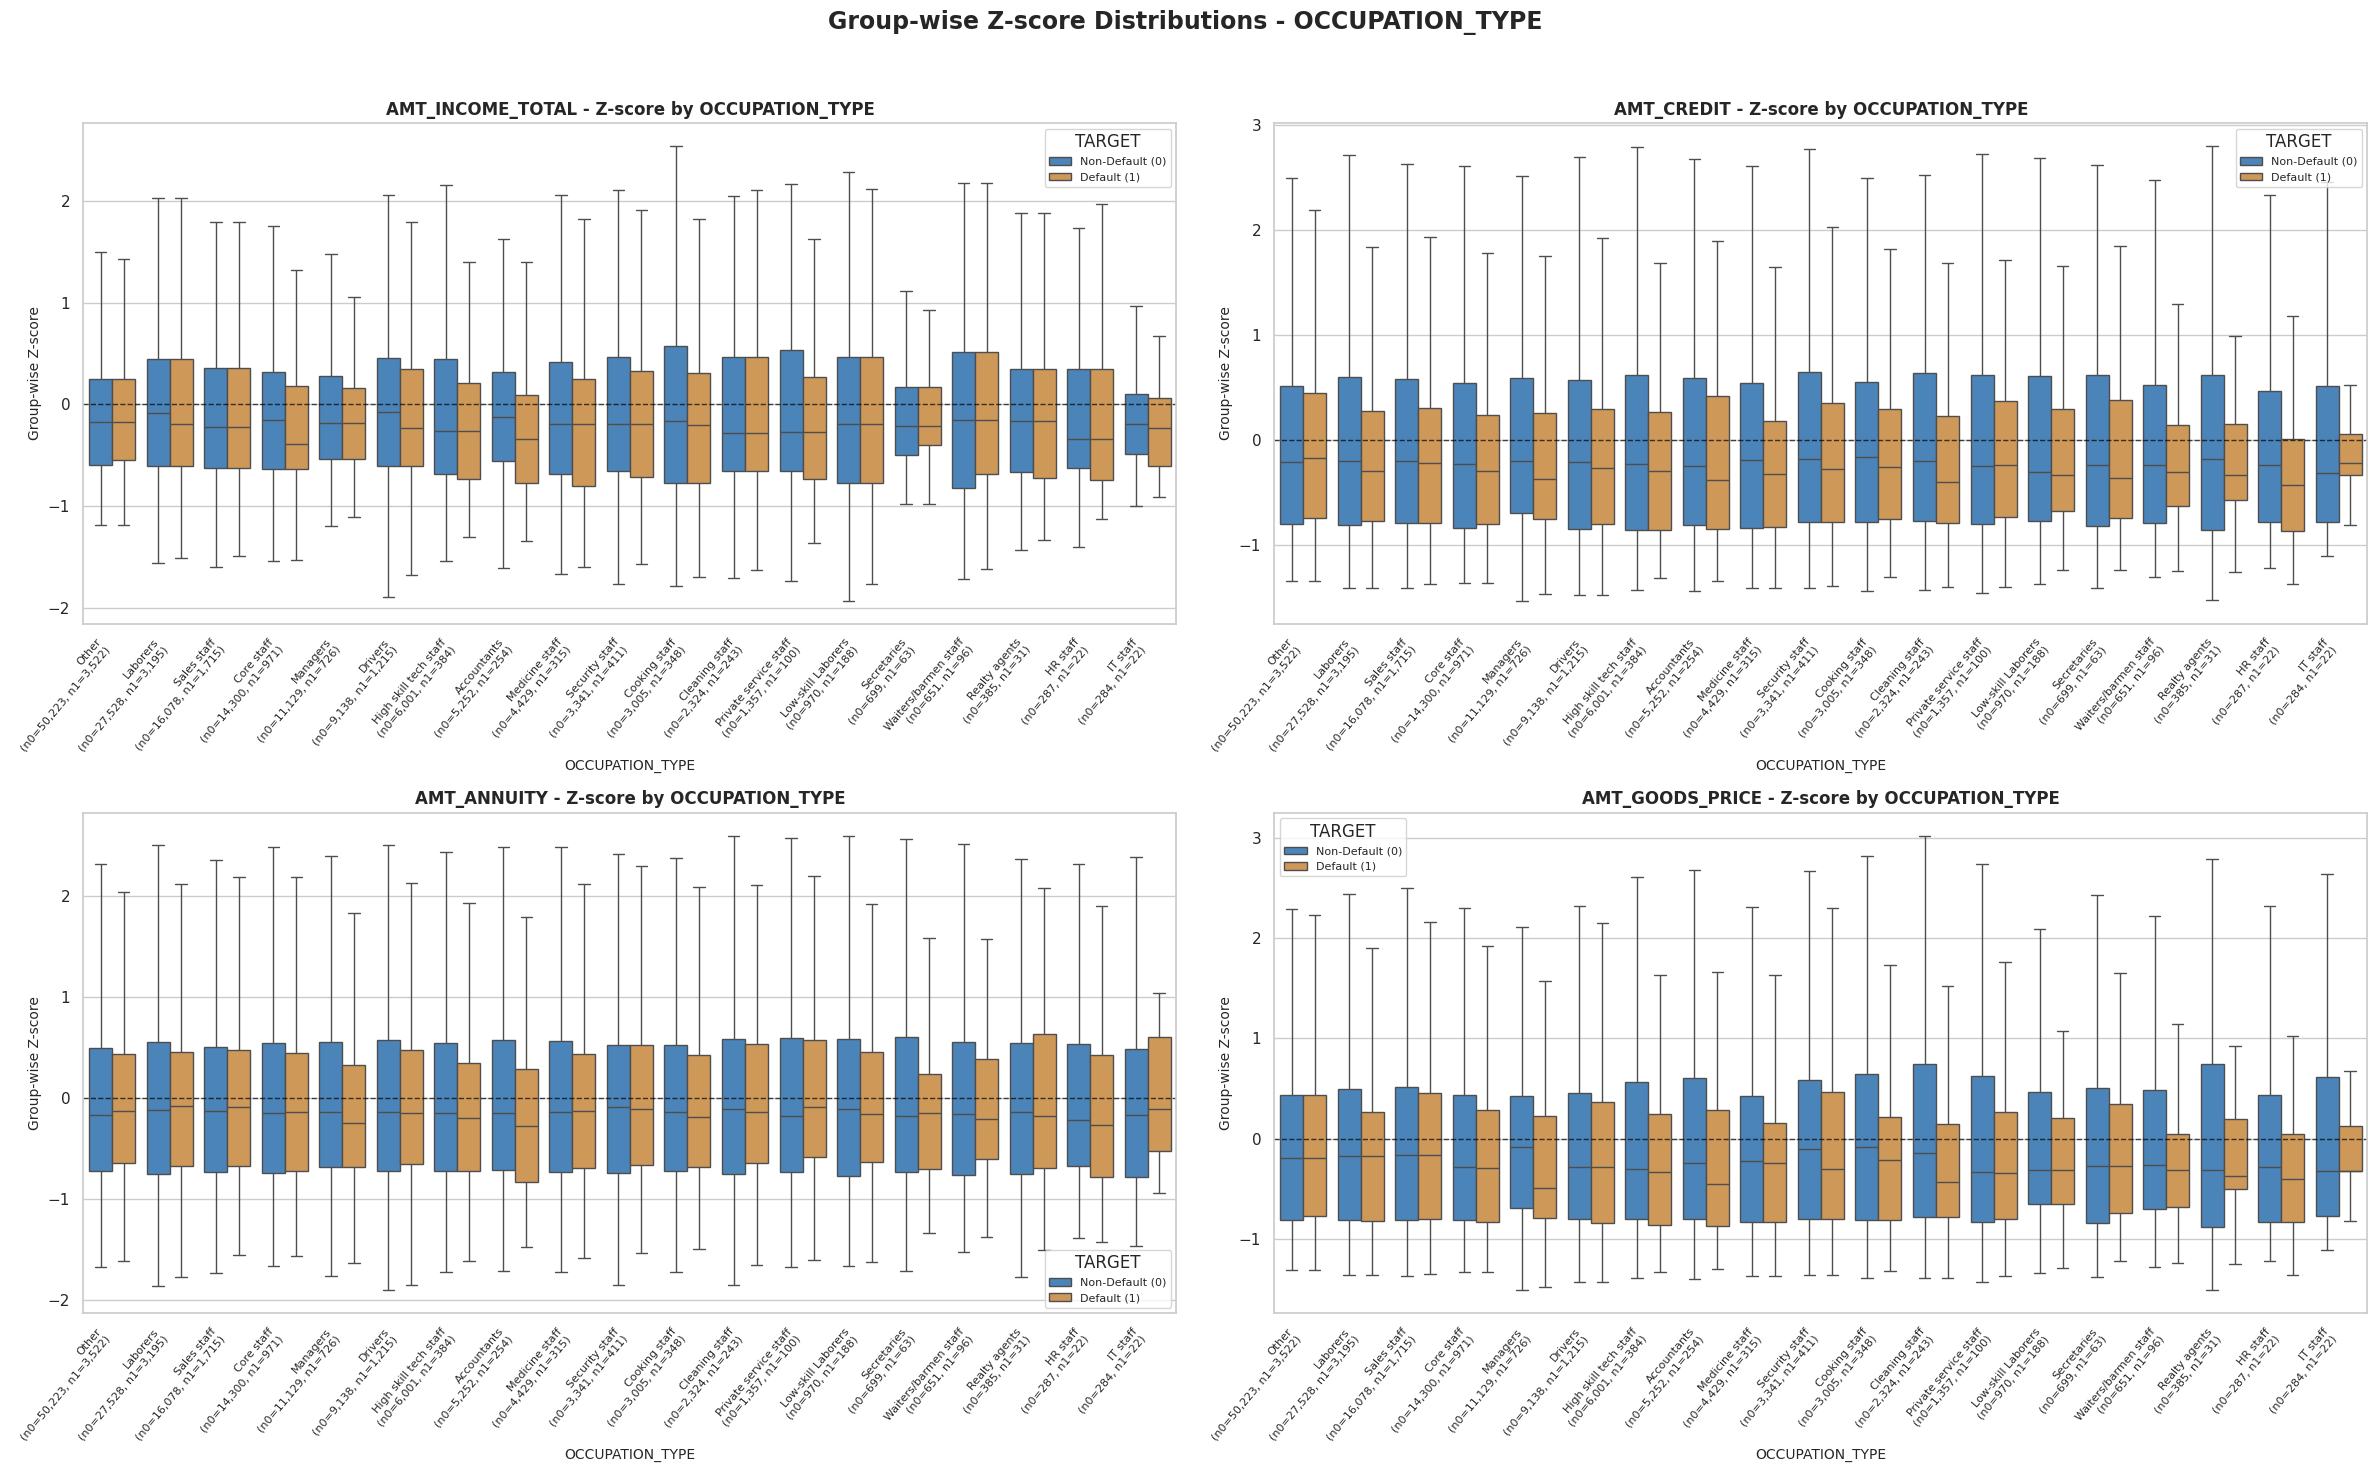


Saved plot:
/content/drive/MyDrive/Competition/output/GROUP_ZSCORE_ANALYSIS/Zscore_plots_OCCUPATION_TYPE.png

Generating plots for: NAME_INCOME_TYPE
  AMT_INCOME_TOTAL: 171,202 observations used
  AMT_CREDIT: 171,202 observations used
  AMT_ANNUITY: 171,202 observations used
  AMT_GOODS_PRICE: 171,202 observations used


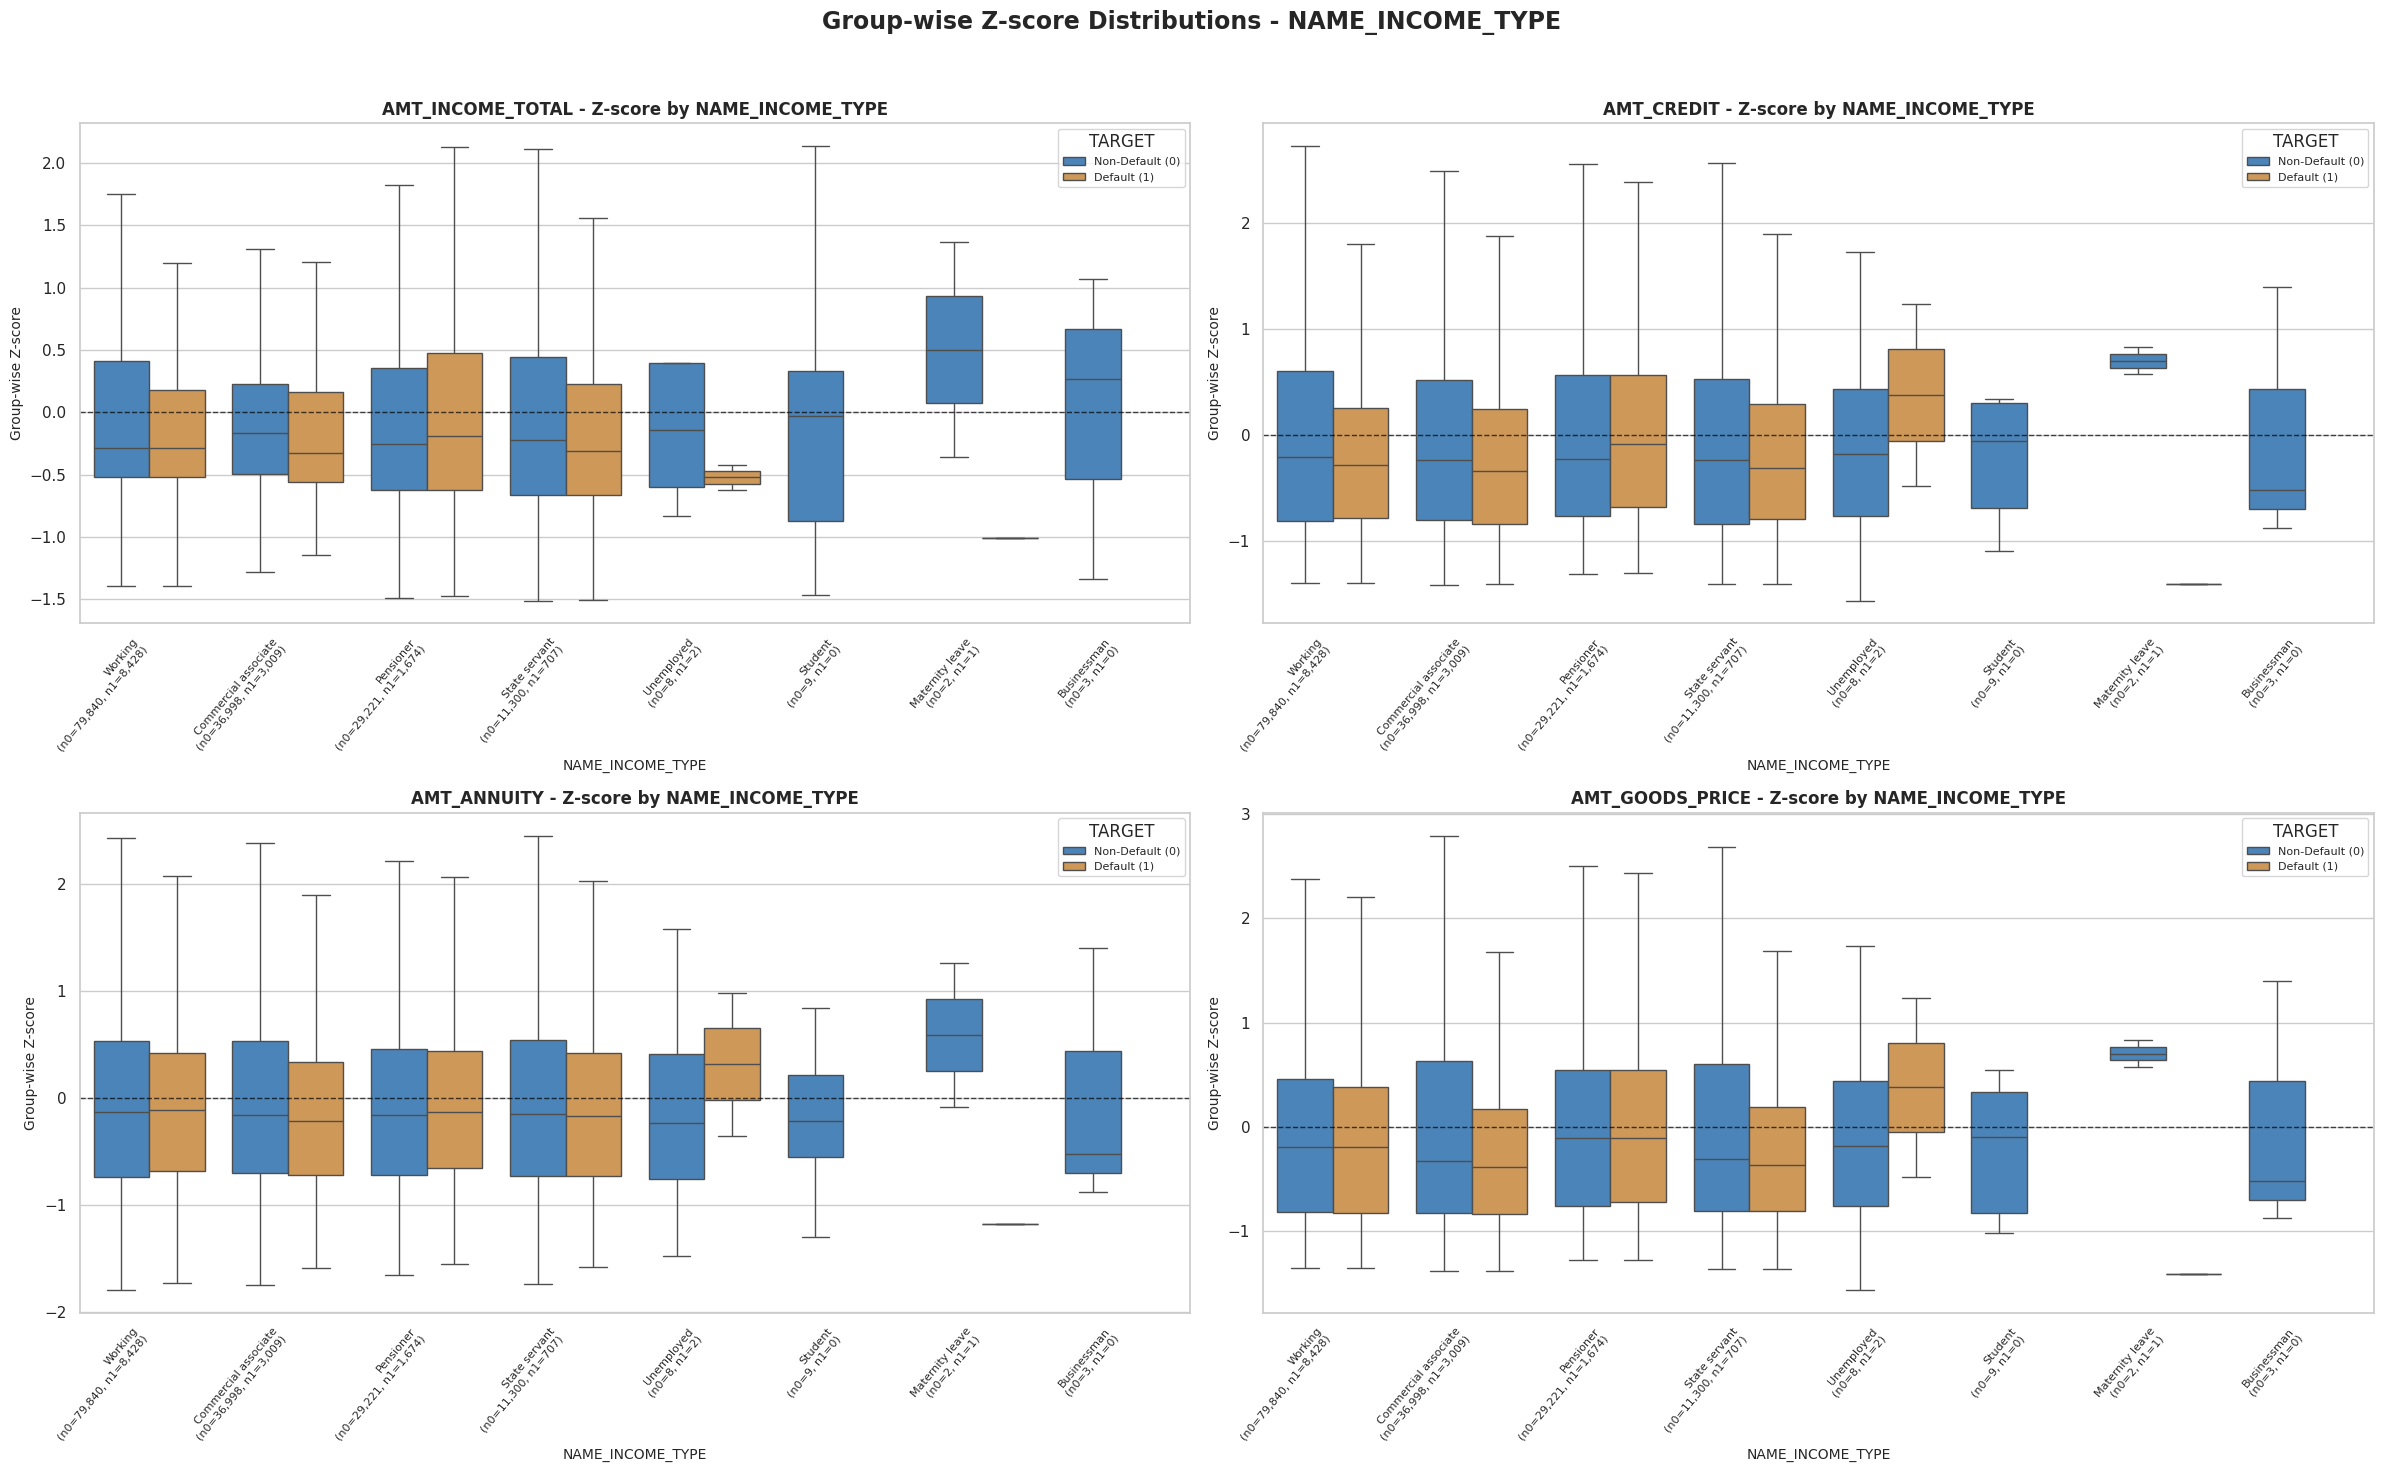


Saved plot:
/content/drive/MyDrive/Competition/output/GROUP_ZSCORE_ANALYSIS/Zscore_plots_NAME_INCOME_TYPE.png

FINAL CLASS DISTRIBUTION REPORT

OCCUPATION_TYPE
Other                          | Non-Default:  50,223 | Default:   3,522 | Total:  53,745
Laborers                       | Non-Default:  27,528 | Default:   3,195 | Total:  30,723
Sales staff                    | Non-Default:  16,078 | Default:   1,715 | Total:  17,793
Core staff                     | Non-Default:  14,300 | Default:     971 | Total:  15,271
Managers                       | Non-Default:  11,129 | Default:     726 | Total:  11,855
Drivers                        | Non-Default:   9,138 | Default:   1,215 | Total:  10,353
High skill tech staff          | Non-Default:   6,001 | Default:     384 | Total:   6,385
Accountants                    | Non-Default:   5,252 | Default:     254 | Total:   5,506
Medicine staff                 | Non-Default:   4,429 | Default:     315 | Total:   4,744
Security staff               

In [13]:

# ============================================================
# HOME CREDIT - GROUP-WISE Z-SCORE ANALYSIS
# FULL DATA VERSION - NO SAMPLING
#
# Groups:
#   1. OCCUPATION_TYPE
#   2. NAME_INCOME_TYPE
#
# Financial features:
#   1. AMT_INCOME_TOTAL
#   2. AMT_CREDIT
#   3. AMT_ANNUITY
#   4. AMT_GOODS_PRICE
#
# Z-score statistics:
#   Calculated using ALL training rows in each group.
#   TARGET is NEVER used to calculate group statistics.
#
# Plots:
#   ALL available TARGET=0 and TARGET=1 observations.
#   NO balanced sampling.
#   NO maximum sample limit.
#
# Output:
#   - Compressed full Z-score CSV
#   - Group statistics
#   - Full-data count summaries
#   - 2 figures, each containing 4 boxplots
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

# Google Colab / Google Drive
ROOT_DIR = "/content/drive/MyDrive/Competition"

TRAIN_PATH = os.path.join(
    ROOT_DIR,
    "input",
    "train.csv"
)

OUTPUT_DIR = os.path.join(
    ROOT_DIR,
    "output",
    "GROUP_ZSCORE_ANALYSIS"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

GROUP_COLUMNS = [
    "OCCUPATION_TYPE",
    "NAME_INCOME_TYPE"
]

FINANCIAL_FEATURES = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

TARGET_COL = "TARGET"

# ============================================================
# 2. LOAD DATA
# ============================================================

print("=" * 80)
print("LOADING TRAIN DATA")
print("=" * 80)

train = pd.read_csv(
    TRAIN_PATH,
    low_memory=False
)

print("Original train shape:", train.shape)

required_columns = (
    GROUP_COLUMNS
    + FINANCIAL_FEATURES
    + [TARGET_COL]
)

missing_columns = [
    col for col in required_columns
    if col not in train.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df = train[required_columns].copy()

del train

# ------------------------------------------------------------
# Convert financial features to numeric
# ------------------------------------------------------------

for col in FINANCIAL_FEATURES:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# Preserve missing group values as explicit categories
# ------------------------------------------------------------

for col in GROUP_COLUMNS:

    df[col] = (
        df[col]
        .fillna("__MISSING__")
        .astype(str)
    )

# ------------------------------------------------------------
# Validate TARGET
# ------------------------------------------------------------

df[TARGET_COL] = pd.to_numeric(
    df[TARGET_COL],
    errors="coerce"
)

initial_rows = len(df)

df = df[
    df[TARGET_COL].isin([0, 1])
].copy()

removed_rows = initial_rows - len(df)

print("\nAnalysis shape:", df.shape)
print("Rows excluded due to invalid TARGET:", removed_rows)

print("\nTARGET distribution:")

print(
    df[TARGET_COL]
    .value_counts()
    .sort_index()
)

# ============================================================
# 3. CALCULATE GROUP-WISE Z-SCORES
# ============================================================

print("\n" + "=" * 80)
print("CALCULATING GROUP-WISE Z-SCORES")
print("=" * 80)

statistics_records = []

for group_col in GROUP_COLUMNS:

    print(f"\nProcessing group: {group_col}")

    grouped = df.groupby(
        group_col,
        dropna=False
    )

    for feature in FINANCIAL_FEATURES:

        # ====================================================
        # Group statistics
        #
        # All rows in each group are used.
        # TARGET is NOT involved.
        # Missing feature values are excluded automatically
        # from mean and standard deviation calculations.
        # ====================================================

        group_mean = grouped[feature].transform("mean")

        group_std = grouped[feature].transform(
            lambda x: x.std(ddof=0)
        )

        z_col = (
            f"Z_{feature}_BY_{group_col}"
        )

        # Avoid division by zero
        valid_std = group_std.replace(
            0,
            np.nan
        )

        # Calculate group-wise Z-score
        df[z_col] = (
            df[feature] - group_mean
        ) / valid_std

        # ====================================================
        # SAVE GROUP STATISTICS
        # ====================================================

        stats = (
            df.groupby(
                group_col,
                dropna=False
            )[feature]
            .agg(
                GROUP_SIZE="size",
                NON_MISSING_COUNT="count",
                MEAN="mean",
                STD=lambda x: x.std(ddof=0)
            )
            .reset_index()
        )

        stats.insert(
            0,
            "GROUP_COLUMN",
            group_col
        )

        stats.insert(
            1,
            "FEATURE",
            feature
        )

        statistics_records.append(stats)

        print(
            f"  {feature}: "
            f"{df[z_col].notna().sum():,} valid Z-scores"
        )

# Combine all group statistics
group_statistics = pd.concat(
    statistics_records,
    ignore_index=True
)

# ============================================================
# 4. SAVE Z-SCORE DATA AND GROUP STATISTICS
# ============================================================

print("\n" + "=" * 80)
print("SAVING Z-SCORE DATA")
print("=" * 80)

zscore_columns = [
    f"Z_{feature}_BY_{group_col}"
    for group_col in GROUP_COLUMNS
    for feature in FINANCIAL_FEATURES
]

zscore_output = df[
    GROUP_COLUMNS
    + [TARGET_COL]
    + FINANCIAL_FEATURES
    + zscore_columns
].copy()

# ------------------------------------------------------------
# Compressed full Z-score data
# ------------------------------------------------------------

zscore_path = os.path.join(
    OUTPUT_DIR,
    "group_wise_zscore_data.csv.gz"
)

zscore_output.to_csv(
    zscore_path,
    index=False,
    compression="gzip"
)

# ------------------------------------------------------------
# Group statistics
# ------------------------------------------------------------

statistics_path = os.path.join(
    OUTPUT_DIR,
    "group_wise_statistics.csv"
)

group_statistics.to_csv(
    statistics_path,
    index=False
)

print("Saved compressed Z-score data:")
print(zscore_path)

print("\nSaved group statistics:")
print(statistics_path)

print(
    "\nZ-score data shape:",
    zscore_output.shape
)

del zscore_output

# ============================================================
# 5. FULL DATA CLASS COUNTS
# ============================================================

print("\n" + "=" * 80)
print("FULL DATA CLASS COUNTS")
print("=" * 80)

all_counts = {}

for group_col in GROUP_COLUMNS:

    print(f"\nGroup column: {group_col}")

    # Count ALL observations in every category
    summary = (
        df.groupby(
            [group_col, TARGET_COL],
            dropna=False
        )
        .size()
        .unstack(fill_value=0)
    )

    # Ensure both TARGET classes exist as columns
    summary = summary.reindex(
        columns=[0, 1],
        fill_value=0
    )

    summary.columns = [
        "NON_DEFAULT_COUNT",
        "DEFAULT_COUNT"
    ]

    summary["TOTAL_COUNT"] = (
        summary["NON_DEFAULT_COUNT"]
        + summary["DEFAULT_COUNT"]
    )

    summary = summary.sort_values(
        "TOTAL_COUNT",
        ascending=False
    )

    all_counts[group_col] = summary

    print(summary.to_string())

    summary_path = os.path.join(
        OUTPUT_DIR,
        f"all_counts_{group_col}.csv"
    )

    summary.to_csv(summary_path)

    print("\nSaved:", summary_path)

# ============================================================
# 6. PLOT CONFIGURATION
# ============================================================

sns.set_theme(
    style="whitegrid"
)

TARGET_LABELS = {
    0: "Non-Default (0)",
    1: "Default (1)"
}

TARGET_PALETTE = {
    "Non-Default (0)": "#3985CA",
    "Default (1)": "#E29A45"
}

# ============================================================
# 7. CREATE FOUR FULL-DATA PLOTS FOR EACH GROUP COLUMN
# ============================================================

print("\n" + "=" * 80)
print("GENERATING FULL-DATA PLOTS")
print("=" * 80)

for group_col in GROUP_COLUMNS:

    print(f"\nGenerating plots for: {group_col}")

    fig, axes = plt.subplots(
        nrows=2,
        ncols=2,
        figsize=(24, 15)
    )

    axes = axes.flatten()

    for i, feature in enumerate(FINANCIAL_FEATURES):

        ax = axes[i]

        z_col = (
            f"Z_{feature}_BY_{group_col}"
        )

        # ----------------------------------------------------
        # Use ALL valid Z-score observations.
        # No sampling and no class balancing.
        # ----------------------------------------------------

        plot_df = df[
            [
                group_col,
                TARGET_COL,
                z_col
            ]
        ].dropna(
            subset=[z_col]
        ).copy()

        # Remove non-finite values if any
        plot_df = plot_df[
            np.isfinite(plot_df[z_col])
        ].copy()

        if plot_df.empty:

            ax.set_title(
                f"{feature} - No valid observations"
            )

            continue

        plot_df["TARGET_LABEL"] = (
            plot_df[TARGET_COL].map(
                TARGET_LABELS
            )
        )

        # ----------------------------------------------------
        # Category order based on ALL available observations
        # ----------------------------------------------------

        category_order = (
            plot_df.groupby(group_col)
            .size()
            .sort_values(
                ascending=False
            )
            .index.tolist()
        )

        # ----------------------------------------------------
        # Count valid observations per class and category
        # for this particular feature.
        # ----------------------------------------------------

        feature_counts = (
            plot_df.groupby(
                [group_col, TARGET_COL]
            )
            .size()
            .unstack(fill_value=0)
            .reindex(
                index=category_order,
                columns=[0, 1],
                fill_value=0
            )
        )

        # ----------------------------------------------------
        # Boxplot using ALL available observations.
        #
        # showfliers=False hides individual outlier markers
        # to keep the figure readable.
        # It does NOT remove those observations before
        # calculating the boxplot statistics.
        # ----------------------------------------------------

        sns.boxplot(
            data=plot_df,
            x=group_col,
            y=z_col,
            hue="TARGET_LABEL",
            order=category_order,
            hue_order=[
                "Non-Default (0)",
                "Default (1)"
            ],
            palette=TARGET_PALETTE,
            showfliers=False,
            ax=ax
        )

        # Reference line: group mean
        ax.axhline(
            y=0,
            color="black",
            linestyle="--",
            linewidth=1,
            alpha=0.7
        )

        ax.set_title(
            f"{feature} - Z-score by {group_col}",
            fontsize=12,
            fontweight="bold"
        )

        ax.set_xlabel(
            group_col,
            fontsize=10
        )

        ax.set_ylabel(
            "Group-wise Z-score",
            fontsize=10
        )

        # ----------------------------------------------------
        # Add actual sample counts to category labels
        # ----------------------------------------------------

        tick_labels = []

        for category in category_order:

            n0 = int(
                feature_counts.loc[
                    category,
                    0
                ]
            )

            n1 = int(
                feature_counts.loc[
                    category,
                    1
                ]
            )

            tick_labels.append(
                f"{category}\n(n0={n0:,}, n1={n1:,})"
            )

        ax.set_xticks(
            range(len(category_order))
        )

        ax.set_xticklabels(
            tick_labels,
            rotation=50,
            ha="right",
            fontsize=8
        )

        ax.legend(
            title="TARGET",
            fontsize=8
        )

        print(
            f"  {feature}: "
            f"{len(plot_df):,} observations used"
        )

    # --------------------------------------------------------
    # Figure title
    # --------------------------------------------------------

    fig.suptitle(
        f"Group-wise Z-score Distributions - {group_col}",
        fontsize=17,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.96]
    )

    # --------------------------------------------------------
    # Save plot
    # --------------------------------------------------------

    plot_path = os.path.join(
        OUTPUT_DIR,
        f"Zscore_plots_{group_col}.png"
    )

    fig.savefig(
        plot_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    print("\nSaved plot:")
    print(plot_path)

# ============================================================
# 8. FINAL CLASS DISTRIBUTION REPORT
# ============================================================

print("\n" + "=" * 80)
print("FINAL CLASS DISTRIBUTION REPORT")
print("=" * 80)

for group_col in GROUP_COLUMNS:

    print(f"\n{group_col}")

    summary = all_counts[group_col]

    for category, row in summary.iterrows():

        print(
            f"{str(category):30s} | "
            f"Non-Default: {int(row['NON_DEFAULT_COUNT']):7,} | "
            f"Default: {int(row['DEFAULT_COUNT']):7,} | "
            f"Total: {int(row['TOTAL_COUNT']):7,}"
        )

# ============================================================
# 9. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nTotal analyzed observations:")
print(f"{len(df):,}")

print("\nTARGET distribution:")
print(
    df[TARGET_COL]
    .value_counts()
    .sort_index()
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    filepath = os.path.join(
        OUTPUT_DIR,
        filename
    )

    size_mb = (
        os.path.getsize(filepath)
        / (1024 ** 2)
    )

    print(
        f" - {filename:50s} "
        f"{size_mb:8.2f} MB"
    )

print("\n" + "=" * 80)
print("ALL AVAILABLE SAMPLES WERE USED.")
print("NO BALANCED SAMPLING WAS PERFORMED.")
print("=" * 80)


LOADING FULL Z-SCORE DATA
Loaded: /content/drive/MyDrive/Competition/output/GROUP_ZSCORE_ANALYSIS/group_wise_zscore_data.csv.gz
Data shape: (171202, 15)

Selected financial feature:
AMT_INCOME_TOTAL

OVERALL COMPARISON

Grouping: OCCUPATION_TYPE
   GROUP_COLUMN      GROUP  TARGET      N      MEAN    MEDIAN      STD       Q25      Q75
OCCUPATION_TYPE ALL_GROUPS       0 157381  0.005441 -0.173130 1.011865 -0.594185 0.399612
OCCUPATION_TYPE ALL_GROUPS       1  13821 -0.061960 -0.210969 0.850962 -0.612273 0.304733

Grouping: NAME_INCOME_TYPE
    GROUP_COLUMN      GROUP  TARGET      N      MEAN    MEDIAN      STD       Q25      Q75
NAME_INCOME_TYPE ALL_GROUPS       0 157381  0.006641 -0.193134 1.014979 -0.531361 0.408954
NAME_INCOME_TYPE ALL_GROUPS       1  13821 -0.075620 -0.285125 0.806351 -0.559183 0.177594

GROUP-WISE COMPARISON

--------------------------------------------------------------------------------
GROUP: OCCUPATION_TYPE
-------------------------------------------------------

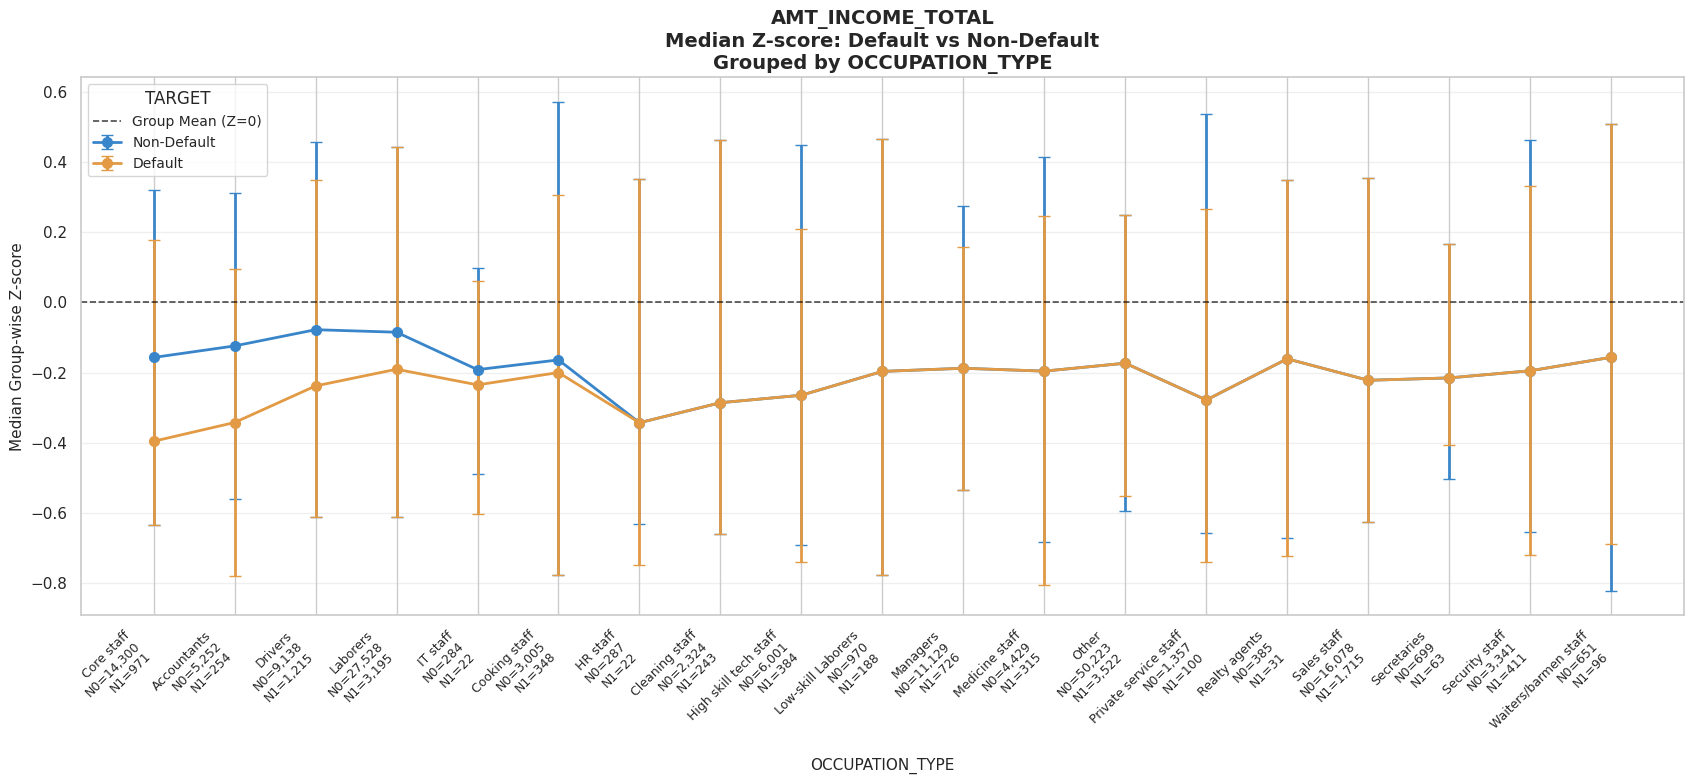

Saved: /content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON/median_lineplot_AMT_INCOME_TOTAL_OCCUPATION_TYPE.png

--------------------------------------------------------------------------------
GROUP: NAME_INCOME_TYPE
--------------------------------------------------------------------------------

Comparison table:
               GROUP  NON_DEFAULT_N  DEFAULT_N  NON_DEFAULT_MEDIAN  DEFAULT_MEDIAN  NON_DEFAULT_MEAN  DEFAULT_MEAN  MEDIAN_DIFFERENCE  MEAN_DIFFERENCE
     Maternity leave              2          1            0.503986       -1.007971      5.039857e-01     -1.007971          -1.511957        -1.511957
          Unemployed              8          2           -0.137401       -0.520491      1.301228e-01     -0.520491          -0.383090        -0.650614
Commercial associate          36998       3009           -0.164136       -0.327612      9.794810e-03     -0.120435          -0.163476        -0.130230
       State servant          11300        707           -0.219924    

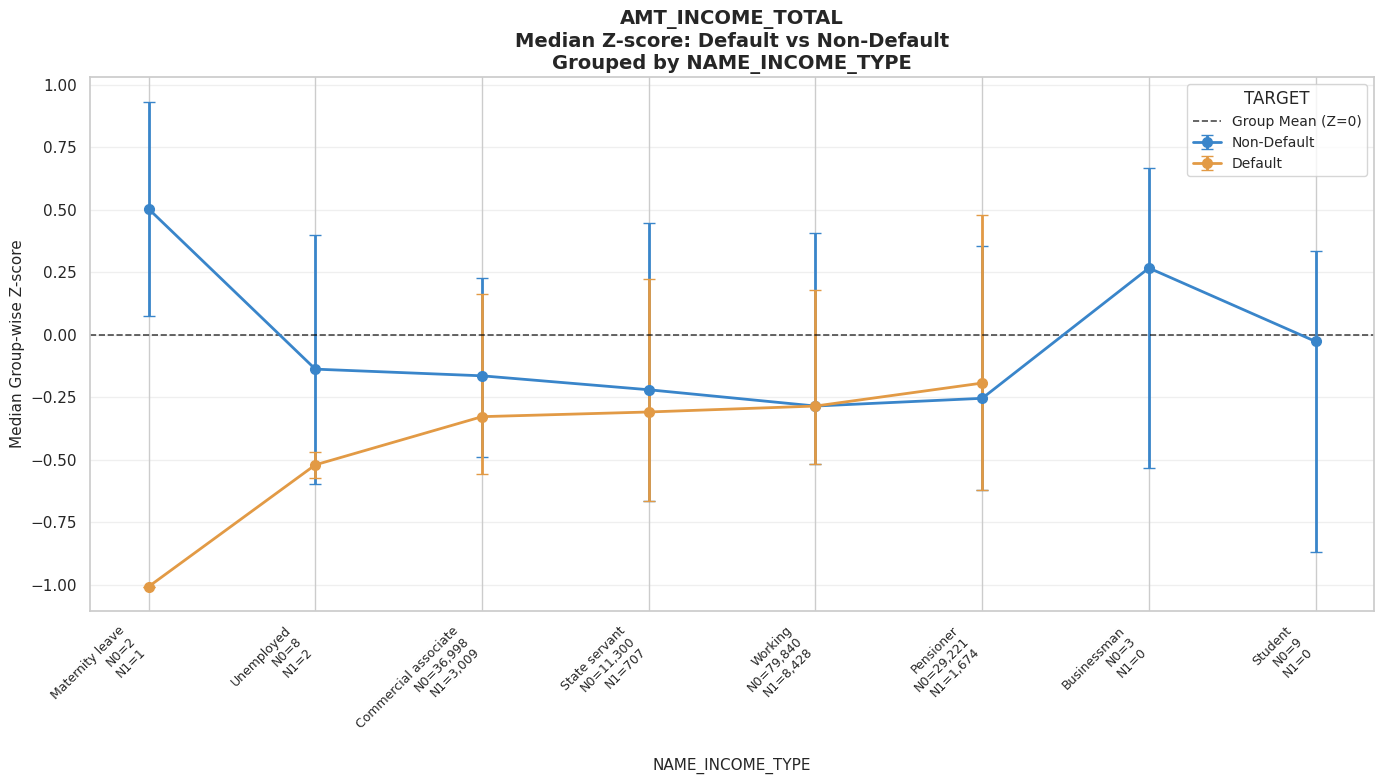

Saved: /content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON/median_lineplot_AMT_INCOME_TOTAL_NAME_INCOME_TYPE.png

ANALYSIS COMPLETED
Selected feature: AMT_INCOME_TOTAL

Output directory:
/content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON

Generated files:
class_comparison_AMT_INCOME_TOTAL_NAME_INCOME_TYPE.csv                         0.001 MB
class_comparison_AMT_INCOME_TOTAL_OCCUPATION_TYPE.csv                          0.003 MB
distribution_statistics_AMT_INCOME_TOTAL_NAME_INCOME_TYPE.csv                  0.002 MB
distribution_statistics_AMT_INCOME_TOTAL_OCCUPATION_TYPE.csv                   0.005 MB
median_lineplot_AMT_INCOME_TOTAL_NAME_INCOME_TYPE.png                          0.309 MB
median_lineplot_AMT_INCOME_TOTAL_OCCUPATION_TYPE.png                           0.453 MB
overall_comparison_AMT_INCOME_TOTAL.csv                                        0.001 MB

ALL AVAILABLE OBSERVATIONS WERE USED.
NO SAMPLING WAS PERFORMED.


In [14]:

# ============================================================
# HOME CREDIT - GROUP-WISE Z-SCORE COMPARISON
#
# Objective:
#   Fix ONE financial feature.
#   Compare Default vs Non-Default Z-scores:
#       1. Within each OCCUPATION_TYPE
#       2. Within each NAME_INCOME_TYPE
#       3. Overall, across all observations
#
# Visualization:
#   Line plots comparing median Z-scores.
#   Error bars represent Q25 and Q75.
#
# No sampling.
# All available observations are used.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT_DIR = "/content/drive/MyDrive/Competition"

INPUT_DIR = os.path.join(
    ROOT_DIR,
    "output",
    "GROUP_ZSCORE_ANALYSIS"
)

OUTPUT_DIR = os.path.join(
    ROOT_DIR,
    "output",
    "ZSCORE_COMPARISON"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Select ONE financial feature for this experiment
# ------------------------------------------------------------

SELECTED_FEATURE = "AMT_INCOME_TOTAL"

# Available features:
# AMT_INCOME_TOTAL
# AMT_CREDIT
# AMT_ANNUITY
# AMT_GOODS_PRICE

GROUP_COLUMNS = [
    "OCCUPATION_TYPE",
    "NAME_INCOME_TYPE"
]

TARGET_COL = "TARGET"

TARGET_LABELS = {
    0: "Non-Default",
    1: "Default"
}

COLORS = {
    "Non-Default": "#3985CA",
    "Default": "#E29A45"
}

# ============================================================
# 2. LOAD FULL Z-SCORE DATA
# ============================================================

print("=" * 80)
print("LOADING FULL Z-SCORE DATA")
print("=" * 80)

COMPRESSED_PATH = os.path.join(
    INPUT_DIR,
    "group_wise_zscore_data.csv.gz"
)

UNCOMPRESSED_PATH = os.path.join(
    INPUT_DIR,
    "group_wise_zscore_data.csv"
)

if os.path.exists(COMPRESSED_PATH):

    DATA_PATH = COMPRESSED_PATH

elif os.path.exists(UNCOMPRESSED_PATH):

    DATA_PATH = UNCOMPRESSED_PATH

else:

    raise FileNotFoundError(
        "Could not find the Z-score data file."
    )

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Loaded:", DATA_PATH)
print("Data shape:", df.shape)

# ============================================================
# 3. VALIDATE SELECTED FEATURE
# ============================================================

if SELECTED_FEATURE not in [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]:

    raise ValueError(
        "Invalid SELECTED_FEATURE."
    )

required_columns = (
    GROUP_COLUMNS
    + [TARGET_COL]
    + [
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
        for group_col in GROUP_COLUMNS
    ]
)

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:

    raise ValueError(
        f"Missing columns: {missing}"
    )

print("\nSelected financial feature:")
print(SELECTED_FEATURE)

# ============================================================
# 4. GENERAL STATISTICS FUNCTION
# ============================================================

def calculate_distribution_statistics(data, value_col):

    records = []

    for target_value in [0, 1]:

        values = data.loc[
            data[TARGET_COL] == target_value,
            value_col
        ].dropna()

        values = values[
            np.isfinite(values)
        ]

        if len(values) == 0:

            records.append({
                "TARGET": target_value,
                "N": 0,
                "MEAN": np.nan,
                "MEDIAN": np.nan,
                "STD": np.nan,
                "Q25": np.nan,
                "Q75": np.nan
            })

            continue

        records.append({

            "TARGET": target_value,

            "N": len(values),

            "MEAN": values.mean(),

            "MEDIAN": values.median(),

            "STD": values.std(ddof=1),

            "Q25": values.quantile(0.25),

            "Q75": values.quantile(0.75)
        })

    return pd.DataFrame(records)


# ============================================================
# 5. OVERALL COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("OVERALL COMPARISON")
print("=" * 80)

overall_records = []

for group_col in GROUP_COLUMNS:

    z_col = (
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
    )

    overall_data = df[
        [TARGET_COL, z_col]
    ].copy()

    overall_data = overall_data.rename(
        columns={z_col: "Z_SCORE"}
    )

    overall_data = overall_data.dropna(
        subset=["Z_SCORE"]
    )

    overall_stats = (
        calculate_distribution_statistics(
            overall_data,
            "Z_SCORE"
        )
    )

    overall_stats.insert(
        0,
        "GROUP_COLUMN",
        group_col
    )

    overall_stats.insert(
        1,
        "GROUP",
        "ALL_GROUPS"
    )

    overall_records.append(
        overall_stats
    )

    print(f"\nGrouping: {group_col}")

    print(
        overall_stats.to_string(
            index=False
        )
    )

overall_summary = pd.concat(
    overall_records,
    ignore_index=True
)

overall_path = os.path.join(
    OUTPUT_DIR,
    f"overall_comparison_{SELECTED_FEATURE}.csv"
)

overall_summary.to_csv(
    overall_path,
    index=False
)

# ============================================================
# 6. GROUP-WISE COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("GROUP-WISE COMPARISON")
print("=" * 80)

for group_col in GROUP_COLUMNS:

    print("\n" + "-" * 80)
    print("GROUP:", group_col)
    print("-" * 80)

    z_col = (
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
    )

    analysis_df = df[
        [
            group_col,
            TARGET_COL,
            z_col
        ]
    ].copy()

    analysis_df = analysis_df.rename(
        columns={z_col: "Z_SCORE"}
    )

    analysis_df = analysis_df.dropna(
        subset=["Z_SCORE"]
    )

    analysis_df = analysis_df[
        np.isfinite(analysis_df["Z_SCORE"])
    ].copy()

    # --------------------------------------------------------
    # Calculate statistics separately for each group and class
    # --------------------------------------------------------

    records = []

    for group_value, group_data in analysis_df.groupby(
        group_col,
        dropna=False
    ):

        stats = calculate_distribution_statistics(
            group_data,
            "Z_SCORE"
        )

        for _, row in stats.iterrows():

            records.append({

                "GROUP_COLUMN": group_col,

                "GROUP": group_value,

                "TARGET": int(row["TARGET"]),

                "N": int(row["N"]),

                "MEAN": row["MEAN"],

                "MEDIAN": row["MEDIAN"],

                "STD": row["STD"],

                "Q25": row["Q25"],

                "Q75": row["Q75"]
            })

    group_stats = pd.DataFrame(
        records
    )

    # --------------------------------------------------------
    # Pivot statistics to compare classes
    # --------------------------------------------------------

    median_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="MEDIAN"
    )

    count_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="N"
    )

    mean_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="MEAN"
    )

    for target_value in [0, 1]:

        if target_value not in median_pivot.columns:

            median_pivot[target_value] = np.nan

        if target_value not in count_pivot.columns:

            count_pivot[target_value] = 0

        if target_value not in mean_pivot.columns:

            mean_pivot[target_value] = np.nan

    comparison = pd.DataFrame({

        "NON_DEFAULT_N": count_pivot[0],

        "DEFAULT_N": count_pivot[1],

        "NON_DEFAULT_MEDIAN": median_pivot[0],

        "DEFAULT_MEDIAN": median_pivot[1],

        "NON_DEFAULT_MEAN": mean_pivot[0],

        "DEFAULT_MEAN": mean_pivot[1]

    })

    comparison["MEDIAN_DIFFERENCE"] = (
        comparison["DEFAULT_MEDIAN"]
        - comparison["NON_DEFAULT_MEDIAN"]
    )

    comparison["MEAN_DIFFERENCE"] = (
        comparison["DEFAULT_MEAN"]
        - comparison["NON_DEFAULT_MEAN"]
    )

    comparison = comparison.reset_index()

    # --------------------------------------------------------
    # Sort categories by median difference.
    # This is a descriptive ordering, not a natural category order.
    # --------------------------------------------------------

    comparison = comparison.sort_values(
        "MEDIAN_DIFFERENCE",
        ascending=True,
        na_position="last"
    )

    print("\nComparison table:")

    print(
        comparison.to_string(
            index=False
        )
    )

    # --------------------------------------------------------
    # Save detailed statistics
    # --------------------------------------------------------

    stats_path = os.path.join(
        OUTPUT_DIR,
        f"distribution_statistics_{SELECTED_FEATURE}_{group_col}.csv"
    )

    group_stats.to_csv(
        stats_path,
        index=False
    )

    comparison_path = os.path.join(
        OUTPUT_DIR,
        f"class_comparison_{SELECTED_FEATURE}_{group_col}.csv"
    )

    comparison.to_csv(
        comparison_path,
        index=False
    )

    # ========================================================
    # 7. LINE PLOT - MEDIAN Z-SCORE
    # ========================================================

    print("\nGenerating line plot...")

    plot_order = comparison["GROUP"].tolist()

    fig, ax = plt.subplots(
        figsize=(max(14, len(plot_order) * 0.9), 8)
    )

    x_positions = np.arange(
        len(plot_order)
    )

    for target_value, label in TARGET_LABELS.items():

        class_stats = (
            group_stats[
                group_stats["TARGET"] == target_value
            ]
            .set_index("GROUP")
            .reindex(plot_order)
        )

        medians = class_stats["MEDIAN"].to_numpy(
            dtype=float
        )

        q25 = class_stats["Q25"].to_numpy(
            dtype=float
        )

        q75 = class_stats["Q75"].to_numpy(
            dtype=float
        )

        # Asymmetric error bars: Q25 to median and median to Q75
        lower_error = np.maximum(
            medians - q25,
            0
        )

        upper_error = np.maximum(
            q75 - medians,
            0
        )

        valid = np.isfinite(medians)

        ax.errorbar(
            x_positions[valid],
            medians[valid],
            yerr=np.vstack([
                lower_error[valid],
                upper_error[valid]
            ]),
            label=label,
            color=COLORS[label],
            marker="o",
            markersize=7,
            linewidth=2,
            capsize=4
        )

    # --------------------------------------------------------
    # Reference line
    # --------------------------------------------------------

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.2,
        alpha=0.7,
        label="Group Mean (Z=0)"
    )

    # --------------------------------------------------------
    # Category labels with actual class counts
    # --------------------------------------------------------

    tick_labels = []

    for _, row in comparison.iterrows():

        tick_labels.append(
            f"{row['GROUP']}\n"
            f"N0={int(row['NON_DEFAULT_N']):,}\n"
            f"N1={int(row['DEFAULT_N']):,}"
        )

    ax.set_xticks(
        x_positions
    )

    ax.set_xticklabels(
        tick_labels,
        rotation=45,
        ha="right",
        fontsize=9
    )

    ax.set_title(
        f"{SELECTED_FEATURE}\n"
        f"Median Z-score: Default vs Non-Default\n"
        f"Grouped by {group_col}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        group_col,
        fontsize=11
    )

    ax.set_ylabel(
        "Median Group-wise Z-score",
        fontsize=11
    )

    ax.legend(
        title="TARGET",
        fontsize=10
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plot_path = os.path.join(
        OUTPUT_DIR,
        f"median_lineplot_{SELECTED_FEATURE}_{group_col}.png"
    )

    fig.savefig(
        plot_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    print("Saved:", plot_path)

# ============================================================
# 8. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("ANALYSIS COMPLETED")
print("=" * 80)

print("Selected feature:", SELECTED_FEATURE)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    filepath = os.path.join(
        OUTPUT_DIR,
        filename
    )

    size_mb = (
        os.path.getsize(filepath)
        / (1024 ** 2)
    )

    print(
        f"{filename:75s} "
        f"{size_mb:8.3f} MB"
    )

print("\n" + "=" * 80)
print("ALL AVAILABLE OBSERVATIONS WERE USED.")
print("NO SAMPLING WAS PERFORMED.")
print("=" * 80)


LOADING FULL Z-SCORE DATA
Loaded: /content/drive/MyDrive/Competition/output/GROUP_ZSCORE_ANALYSIS/group_wise_zscore_data.csv.gz
Data shape: (171202, 15)

Selected financial feature:
AMT_CREDIT

OVERALL COMPARISON

Grouping: OCCUPATION_TYPE
   GROUP_COLUMN      GROUP  TARGET      N      MEAN    MEDIAN      STD       Q25      Q75
OCCUPATION_TYPE ALL_GROUPS       0 157381  0.008107 -0.204039 1.009755 -0.803623 0.565381
OCCUPATION_TYPE ALL_GROUPS       1  13821 -0.092312 -0.261540 0.876140 -0.772416 0.310806

Grouping: NAME_INCOME_TYPE
    GROUP_COLUMN      GROUP  TARGET      N      MEAN    MEDIAN      STD       Q25      Q75
NAME_INCOME_TYPE ALL_GROUPS       0 157381  0.009415 -0.216031 1.010197 -0.808396 0.567938
NAME_INCOME_TYPE ALL_GROUPS       1  13821 -0.107205 -0.285802 0.868455 -0.777984 0.309569

GROUP-WISE COMPARISON

--------------------------------------------------------------------------------
GROUP: OCCUPATION_TYPE
-------------------------------------------------------------

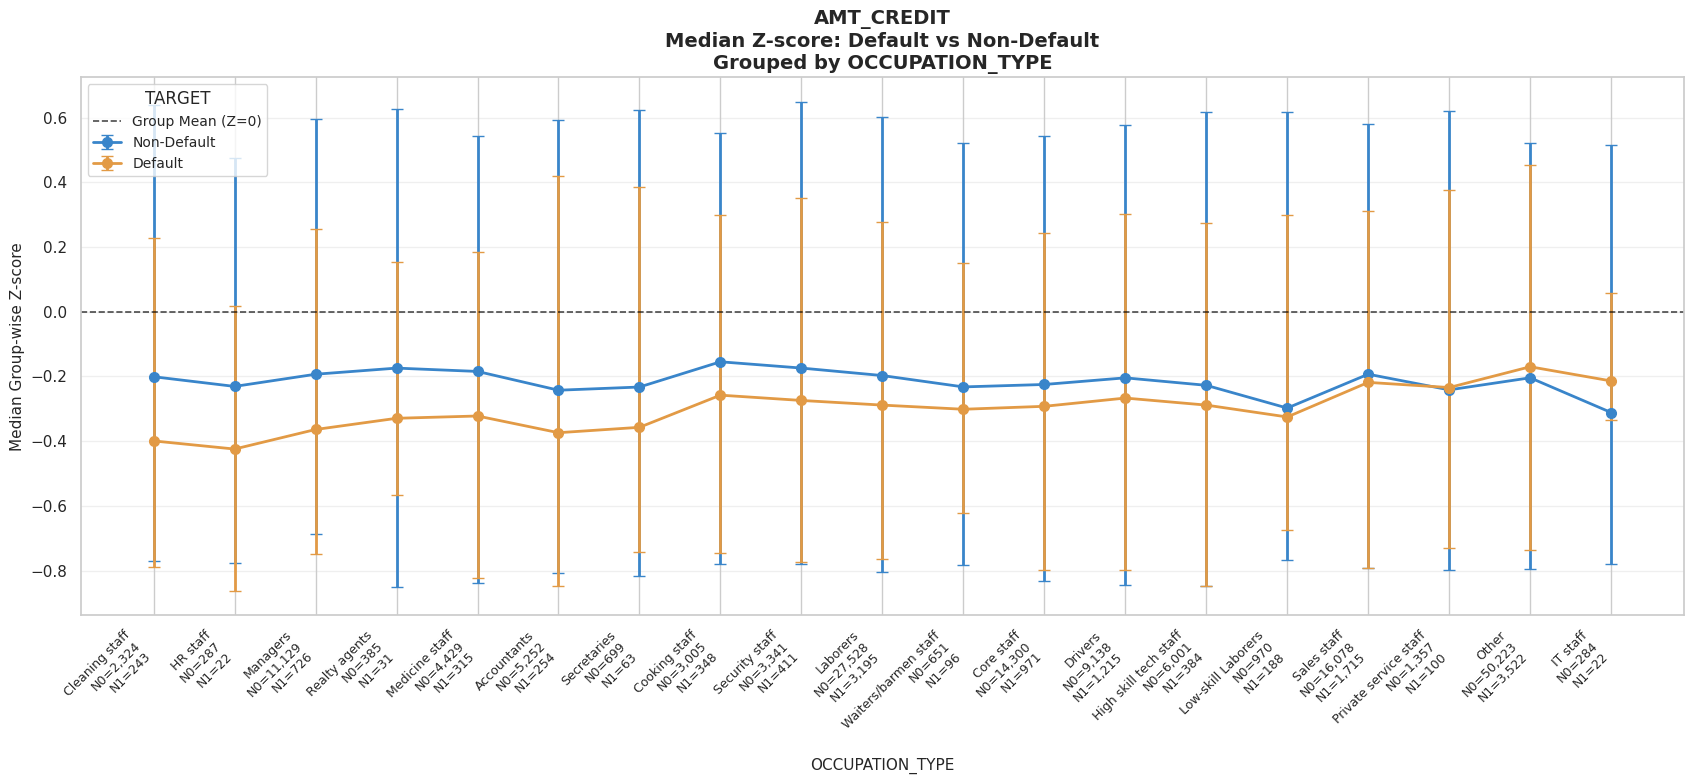

Saved: /content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON/median_lineplot_AMT_CREDIT_OCCUPATION_TYPE.png

--------------------------------------------------------------------------------
GROUP: NAME_INCOME_TYPE
--------------------------------------------------------------------------------

Comparison table:
               GROUP  NON_DEFAULT_N  DEFAULT_N  NON_DEFAULT_MEDIAN  DEFAULT_MEDIAN  NON_DEFAULT_MEAN  DEFAULT_MEAN  MEDIAN_DIFFERENCE  MEAN_DIFFERENCE
     Maternity leave              2          1            0.703100       -1.406199      7.030996e-01     -1.406199          -2.109299        -2.109299
Commercial associate          36998       3009           -0.232139       -0.339465      1.362433e-02     -0.167522          -0.107325        -0.181146
             Working          79840       8428           -0.210330       -0.287489      1.215843e-02     -0.115179          -0.077160        -0.127337
       State servant          11300        707           -0.235590       -0.

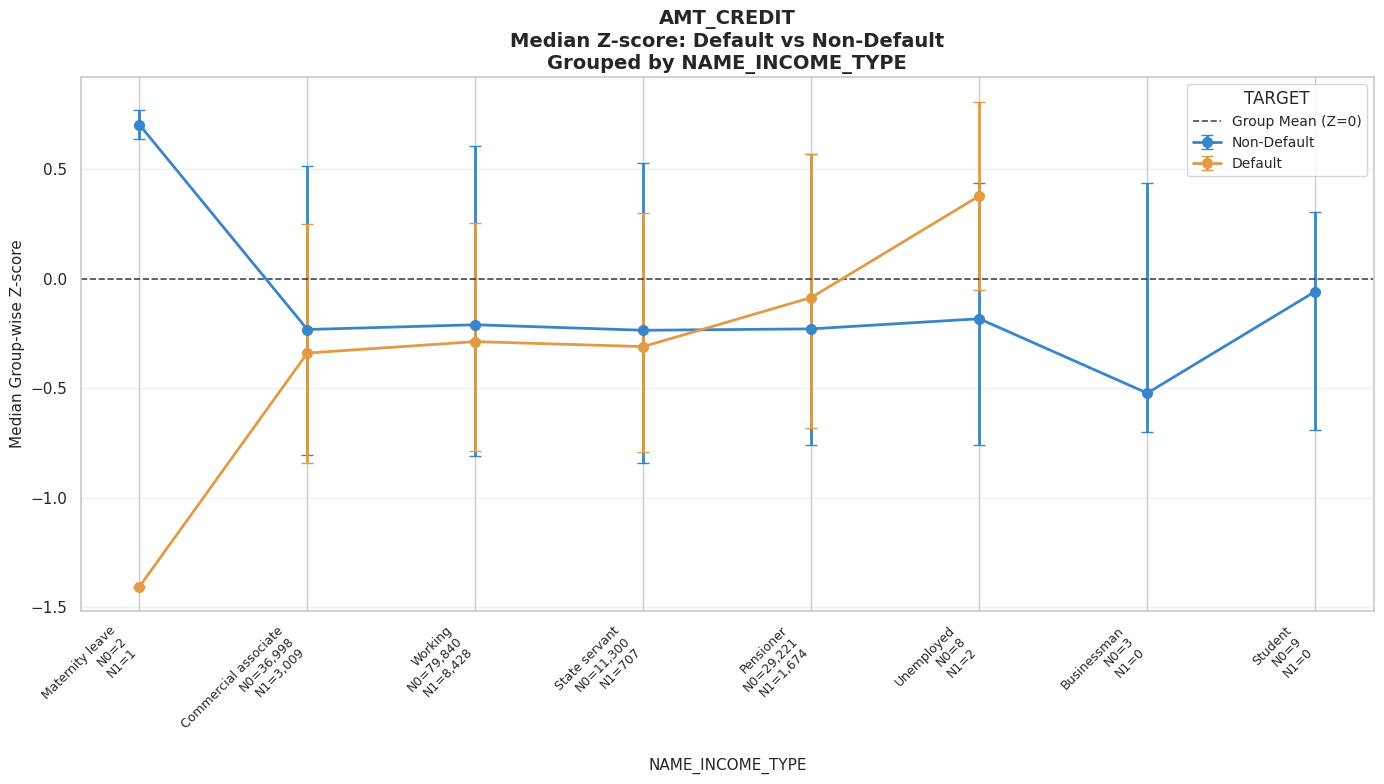

Saved: /content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON/median_lineplot_AMT_CREDIT_NAME_INCOME_TYPE.png

ANALYSIS COMPLETED
Selected feature: AMT_CREDIT

Output directory:
/content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON

Generated files:
class_comparison_AMT_CREDIT_NAME_INCOME_TYPE.csv                               0.001 MB
class_comparison_AMT_CREDIT_OCCUPATION_TYPE.csv                                0.003 MB
class_comparison_AMT_INCOME_TOTAL_NAME_INCOME_TYPE.csv                         0.001 MB
class_comparison_AMT_INCOME_TOTAL_OCCUPATION_TYPE.csv                          0.003 MB
distribution_statistics_AMT_CREDIT_NAME_INCOME_TYPE.csv                        0.002 MB
distribution_statistics_AMT_CREDIT_OCCUPATION_TYPE.csv                         0.005 MB
distribution_statistics_AMT_INCOME_TOTAL_NAME_INCOME_TYPE.csv                  0.002 MB
distribution_statistics_AMT_INCOME_TOTAL_OCCUPATION_TYPE.csv                   0.005 MB
median_lineplot_AMT_CREDIT_NAME_INC

In [15]:

# ============================================================
# HOME CREDIT - GROUP-WISE Z-SCORE COMPARISON
#
# Objective:
#   Fix ONE financial feature.
#   Compare Default vs Non-Default Z-scores:
#       1. Within each OCCUPATION_TYPE
#       2. Within each NAME_INCOME_TYPE
#       3. Overall, across all observations
#
# Visualization:
#   Line plots comparing median Z-scores.
#   Error bars represent Q25 and Q75.
#
# No sampling.
# All available observations are used.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT_DIR = "/content/drive/MyDrive/Competition"

INPUT_DIR = os.path.join(
    ROOT_DIR,
    "output",
    "GROUP_ZSCORE_ANALYSIS"
)

OUTPUT_DIR = os.path.join(
    ROOT_DIR,
    "output",
    "ZSCORE_COMPARISON"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Select ONE financial feature for this experiment
# ------------------------------------------------------------

SELECTED_FEATURE = "AMT_CREDIT"

# Available features:
# AMT_INCOME_TOTAL
# AMT_CREDIT
# AMT_ANNUITY
# AMT_GOODS_PRICE

GROUP_COLUMNS = [
    "OCCUPATION_TYPE",
    "NAME_INCOME_TYPE"
]

TARGET_COL = "TARGET"

TARGET_LABELS = {
    0: "Non-Default",
    1: "Default"
}

COLORS = {
    "Non-Default": "#3985CA",
    "Default": "#E29A45"
}

# ============================================================
# 2. LOAD FULL Z-SCORE DATA
# ============================================================

print("=" * 80)
print("LOADING FULL Z-SCORE DATA")
print("=" * 80)

COMPRESSED_PATH = os.path.join(
    INPUT_DIR,
    "group_wise_zscore_data.csv.gz"
)

UNCOMPRESSED_PATH = os.path.join(
    INPUT_DIR,
    "group_wise_zscore_data.csv"
)

if os.path.exists(COMPRESSED_PATH):

    DATA_PATH = COMPRESSED_PATH

elif os.path.exists(UNCOMPRESSED_PATH):

    DATA_PATH = UNCOMPRESSED_PATH

else:

    raise FileNotFoundError(
        "Could not find the Z-score data file."
    )

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Loaded:", DATA_PATH)
print("Data shape:", df.shape)

# ============================================================
# 3. VALIDATE SELECTED FEATURE
# ============================================================

if SELECTED_FEATURE not in [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]:

    raise ValueError(
        "Invalid SELECTED_FEATURE."
    )

required_columns = (
    GROUP_COLUMNS
    + [TARGET_COL]
    + [
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
        for group_col in GROUP_COLUMNS
    ]
)

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:

    raise ValueError(
        f"Missing columns: {missing}"
    )

print("\nSelected financial feature:")
print(SELECTED_FEATURE)

# ============================================================
# 4. GENERAL STATISTICS FUNCTION
# ============================================================

def calculate_distribution_statistics(data, value_col):

    records = []

    for target_value in [0, 1]:

        values = data.loc[
            data[TARGET_COL] == target_value,
            value_col
        ].dropna()

        values = values[
            np.isfinite(values)
        ]

        if len(values) == 0:

            records.append({
                "TARGET": target_value,
                "N": 0,
                "MEAN": np.nan,
                "MEDIAN": np.nan,
                "STD": np.nan,
                "Q25": np.nan,
                "Q75": np.nan
            })

            continue

        records.append({

            "TARGET": target_value,

            "N": len(values),

            "MEAN": values.mean(),

            "MEDIAN": values.median(),

            "STD": values.std(ddof=1),

            "Q25": values.quantile(0.25),

            "Q75": values.quantile(0.75)
        })

    return pd.DataFrame(records)


# ============================================================
# 5. OVERALL COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("OVERALL COMPARISON")
print("=" * 80)

overall_records = []

for group_col in GROUP_COLUMNS:

    z_col = (
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
    )

    overall_data = df[
        [TARGET_COL, z_col]
    ].copy()

    overall_data = overall_data.rename(
        columns={z_col: "Z_SCORE"}
    )

    overall_data = overall_data.dropna(
        subset=["Z_SCORE"]
    )

    overall_stats = (
        calculate_distribution_statistics(
            overall_data,
            "Z_SCORE"
        )
    )

    overall_stats.insert(
        0,
        "GROUP_COLUMN",
        group_col
    )

    overall_stats.insert(
        1,
        "GROUP",
        "ALL_GROUPS"
    )

    overall_records.append(
        overall_stats
    )

    print(f"\nGrouping: {group_col}")

    print(
        overall_stats.to_string(
            index=False
        )
    )

overall_summary = pd.concat(
    overall_records,
    ignore_index=True
)

overall_path = os.path.join(
    OUTPUT_DIR,
    f"overall_comparison_{SELECTED_FEATURE}.csv"
)

overall_summary.to_csv(
    overall_path,
    index=False
)

# ============================================================
# 6. GROUP-WISE COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("GROUP-WISE COMPARISON")
print("=" * 80)

for group_col in GROUP_COLUMNS:

    print("\n" + "-" * 80)
    print("GROUP:", group_col)
    print("-" * 80)

    z_col = (
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
    )

    analysis_df = df[
        [
            group_col,
            TARGET_COL,
            z_col
        ]
    ].copy()

    analysis_df = analysis_df.rename(
        columns={z_col: "Z_SCORE"}
    )

    analysis_df = analysis_df.dropna(
        subset=["Z_SCORE"]
    )

    analysis_df = analysis_df[
        np.isfinite(analysis_df["Z_SCORE"])
    ].copy()

    # --------------------------------------------------------
    # Calculate statistics separately for each group and class
    # --------------------------------------------------------

    records = []

    for group_value, group_data in analysis_df.groupby(
        group_col,
        dropna=False
    ):

        stats = calculate_distribution_statistics(
            group_data,
            "Z_SCORE"
        )

        for _, row in stats.iterrows():

            records.append({

                "GROUP_COLUMN": group_col,

                "GROUP": group_value,

                "TARGET": int(row["TARGET"]),

                "N": int(row["N"]),

                "MEAN": row["MEAN"],

                "MEDIAN": row["MEDIAN"],

                "STD": row["STD"],

                "Q25": row["Q25"],

                "Q75": row["Q75"]
            })

    group_stats = pd.DataFrame(
        records
    )

    # --------------------------------------------------------
    # Pivot statistics to compare classes
    # --------------------------------------------------------

    median_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="MEDIAN"
    )

    count_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="N"
    )

    mean_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="MEAN"
    )

    for target_value in [0, 1]:

        if target_value not in median_pivot.columns:

            median_pivot[target_value] = np.nan

        if target_value not in count_pivot.columns:

            count_pivot[target_value] = 0

        if target_value not in mean_pivot.columns:

            mean_pivot[target_value] = np.nan

    comparison = pd.DataFrame({

        "NON_DEFAULT_N": count_pivot[0],

        "DEFAULT_N": count_pivot[1],

        "NON_DEFAULT_MEDIAN": median_pivot[0],

        "DEFAULT_MEDIAN": median_pivot[1],

        "NON_DEFAULT_MEAN": mean_pivot[0],

        "DEFAULT_MEAN": mean_pivot[1]

    })

    comparison["MEDIAN_DIFFERENCE"] = (
        comparison["DEFAULT_MEDIAN"]
        - comparison["NON_DEFAULT_MEDIAN"]
    )

    comparison["MEAN_DIFFERENCE"] = (
        comparison["DEFAULT_MEAN"]
        - comparison["NON_DEFAULT_MEAN"]
    )

    comparison = comparison.reset_index()

    # --------------------------------------------------------
    # Sort categories by median difference.
    # This is a descriptive ordering, not a natural category order.
    # --------------------------------------------------------

    comparison = comparison.sort_values(
        "MEDIAN_DIFFERENCE",
        ascending=True,
        na_position="last"
    )

    print("\nComparison table:")

    print(
        comparison.to_string(
            index=False
        )
    )

    # --------------------------------------------------------
    # Save detailed statistics
    # --------------------------------------------------------

    stats_path = os.path.join(
        OUTPUT_DIR,
        f"distribution_statistics_{SELECTED_FEATURE}_{group_col}.csv"
    )

    group_stats.to_csv(
        stats_path,
        index=False
    )

    comparison_path = os.path.join(
        OUTPUT_DIR,
        f"class_comparison_{SELECTED_FEATURE}_{group_col}.csv"
    )

    comparison.to_csv(
        comparison_path,
        index=False
    )

    # ========================================================
    # 7. LINE PLOT - MEDIAN Z-SCORE
    # ========================================================

    print("\nGenerating line plot...")

    plot_order = comparison["GROUP"].tolist()

    fig, ax = plt.subplots(
        figsize=(max(14, len(plot_order) * 0.9), 8)
    )

    x_positions = np.arange(
        len(plot_order)
    )

    for target_value, label in TARGET_LABELS.items():

        class_stats = (
            group_stats[
                group_stats["TARGET"] == target_value
            ]
            .set_index("GROUP")
            .reindex(plot_order)
        )

        medians = class_stats["MEDIAN"].to_numpy(
            dtype=float
        )

        q25 = class_stats["Q25"].to_numpy(
            dtype=float
        )

        q75 = class_stats["Q75"].to_numpy(
            dtype=float
        )

        # Asymmetric error bars: Q25 to median and median to Q75
        lower_error = np.maximum(
            medians - q25,
            0
        )

        upper_error = np.maximum(
            q75 - medians,
            0
        )

        valid = np.isfinite(medians)

        ax.errorbar(
            x_positions[valid],
            medians[valid],
            yerr=np.vstack([
                lower_error[valid],
                upper_error[valid]
            ]),
            label=label,
            color=COLORS[label],
            marker="o",
            markersize=7,
            linewidth=2,
            capsize=4
        )

    # --------------------------------------------------------
    # Reference line
    # --------------------------------------------------------

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.2,
        alpha=0.7,
        label="Group Mean (Z=0)"
    )

    # --------------------------------------------------------
    # Category labels with actual class counts
    # --------------------------------------------------------

    tick_labels = []

    for _, row in comparison.iterrows():

        tick_labels.append(
            f"{row['GROUP']}\n"
            f"N0={int(row['NON_DEFAULT_N']):,}\n"
            f"N1={int(row['DEFAULT_N']):,}"
        )

    ax.set_xticks(
        x_positions
    )

    ax.set_xticklabels(
        tick_labels,
        rotation=45,
        ha="right",
        fontsize=9
    )

    ax.set_title(
        f"{SELECTED_FEATURE}\n"
        f"Median Z-score: Default vs Non-Default\n"
        f"Grouped by {group_col}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        group_col,
        fontsize=11
    )

    ax.set_ylabel(
        "Median Group-wise Z-score",
        fontsize=11
    )

    ax.legend(
        title="TARGET",
        fontsize=10
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plot_path = os.path.join(
        OUTPUT_DIR,
        f"median_lineplot_{SELECTED_FEATURE}_{group_col}.png"
    )

    fig.savefig(
        plot_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    print("Saved:", plot_path)

# ============================================================
# 8. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("ANALYSIS COMPLETED")
print("=" * 80)

print("Selected feature:", SELECTED_FEATURE)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    filepath = os.path.join(
        OUTPUT_DIR,
        filename
    )

    size_mb = (
        os.path.getsize(filepath)
        / (1024 ** 2)
    )

    print(
        f"{filename:75s} "
        f"{size_mb:8.3f} MB"
    )

print("\n" + "=" * 80)
print("ALL AVAILABLE OBSERVATIONS WERE USED.")
print("NO SAMPLING WAS PERFORMED.")
print("=" * 80)


LOADING FULL Z-SCORE DATA
Loaded: /content/drive/MyDrive/Competition/output/GROUP_ZSCORE_ANALYSIS/group_wise_zscore_data.csv.gz
Data shape: (171202, 15)

Selected financial feature:
AMT_ANNUITY

OVERALL COMPARISON

Grouping: OCCUPATION_TYPE
   GROUP_COLUMN      GROUP  TARGET      N      MEAN    MEDIAN      STD       Q25      Q75
OCCUPATION_TYPE ALL_GROUPS       0 157381  0.003148 -0.146610 1.009750 -0.733184 0.527025
OCCUPATION_TYPE ALL_GROUPS       1  13821 -0.035847 -0.132497 0.880683 -0.672836 0.444837

Grouping: NAME_INCOME_TYPE
    GROUP_COLUMN      GROUP  TARGET      N      MEAN    MEDIAN      STD       Q25      Q75
NAME_INCOME_TYPE ALL_GROUPS       0 157381  0.004506 -0.146528 1.010432 -0.728697 0.516307
NAME_INCOME_TYPE ALL_GROUPS       1  13821 -0.051316 -0.137541 0.870883 -0.689461 0.399667

GROUP-WISE COMPARISON

--------------------------------------------------------------------------------
GROUP: OCCUPATION_TYPE
------------------------------------------------------------

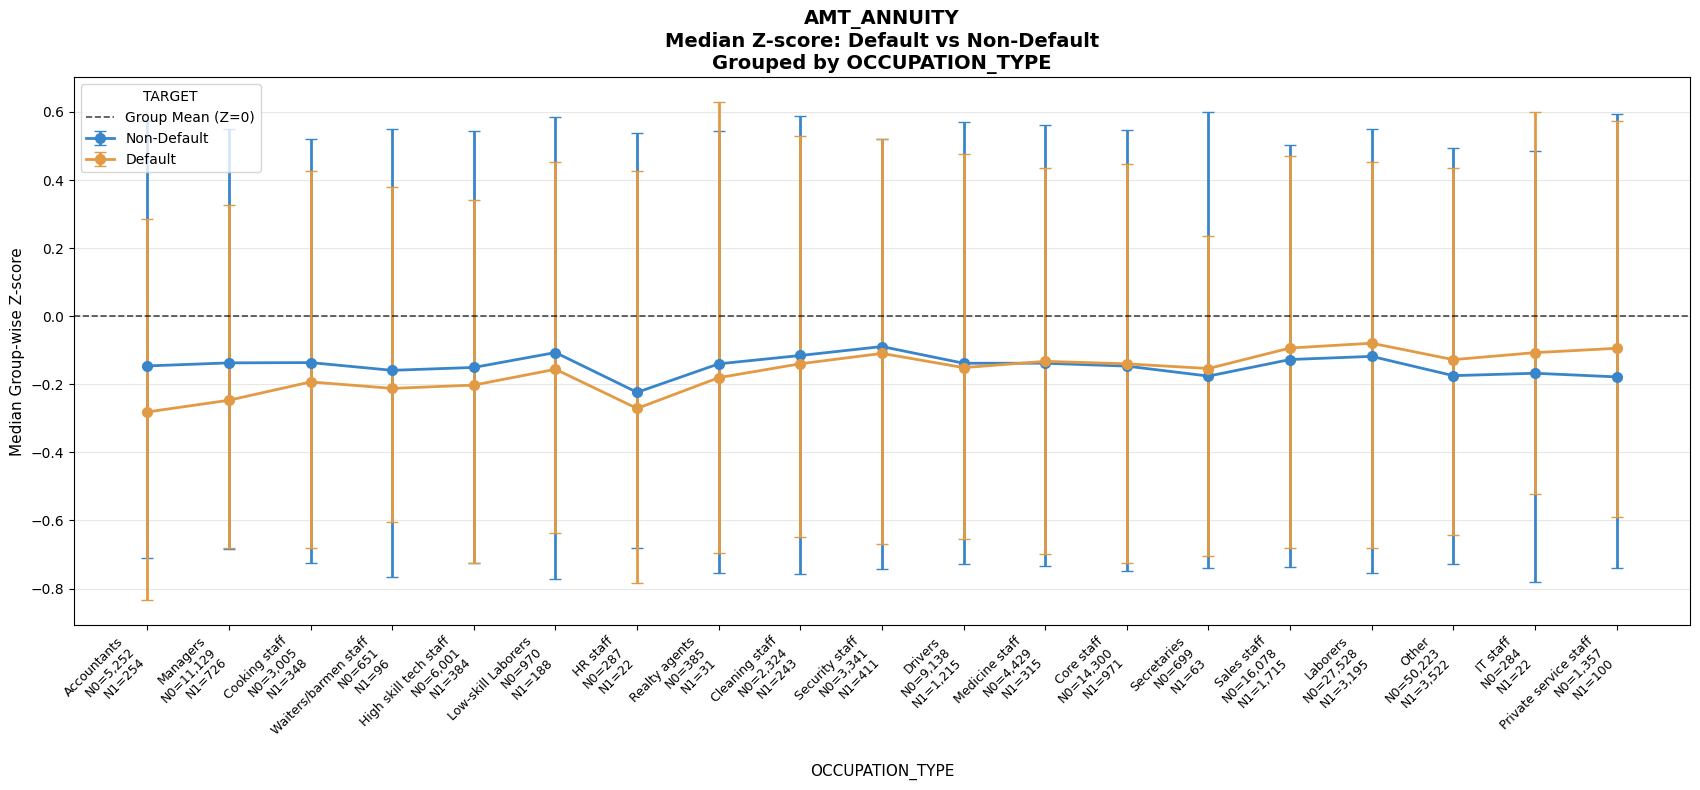

Saved: /content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON/median_lineplot_AMT_ANNUITY_OCCUPATION_TYPE.png

--------------------------------------------------------------------------------
GROUP: NAME_INCOME_TYPE
--------------------------------------------------------------------------------

Comparison table:
               GROUP  NON_DEFAULT_N  DEFAULT_N  NON_DEFAULT_MEDIAN  DEFAULT_MEDIAN  NON_DEFAULT_MEAN  DEFAULT_MEAN  MEDIAN_DIFFERENCE  MEAN_DIFFERENCE
     Maternity leave              2          1            0.590068       -1.180136      5.900679e-01     -1.180136          -1.770204        -1.770204
Commercial associate          36998       3009           -0.156500       -0.211986      9.107110e-03     -0.111979          -0.055485        -0.121086
       State servant          11300        707           -0.153228       -0.168575      5.959331e-03     -0.095248          -0.015347        -0.101207
             Working          79840       8428           -0.134977       -0

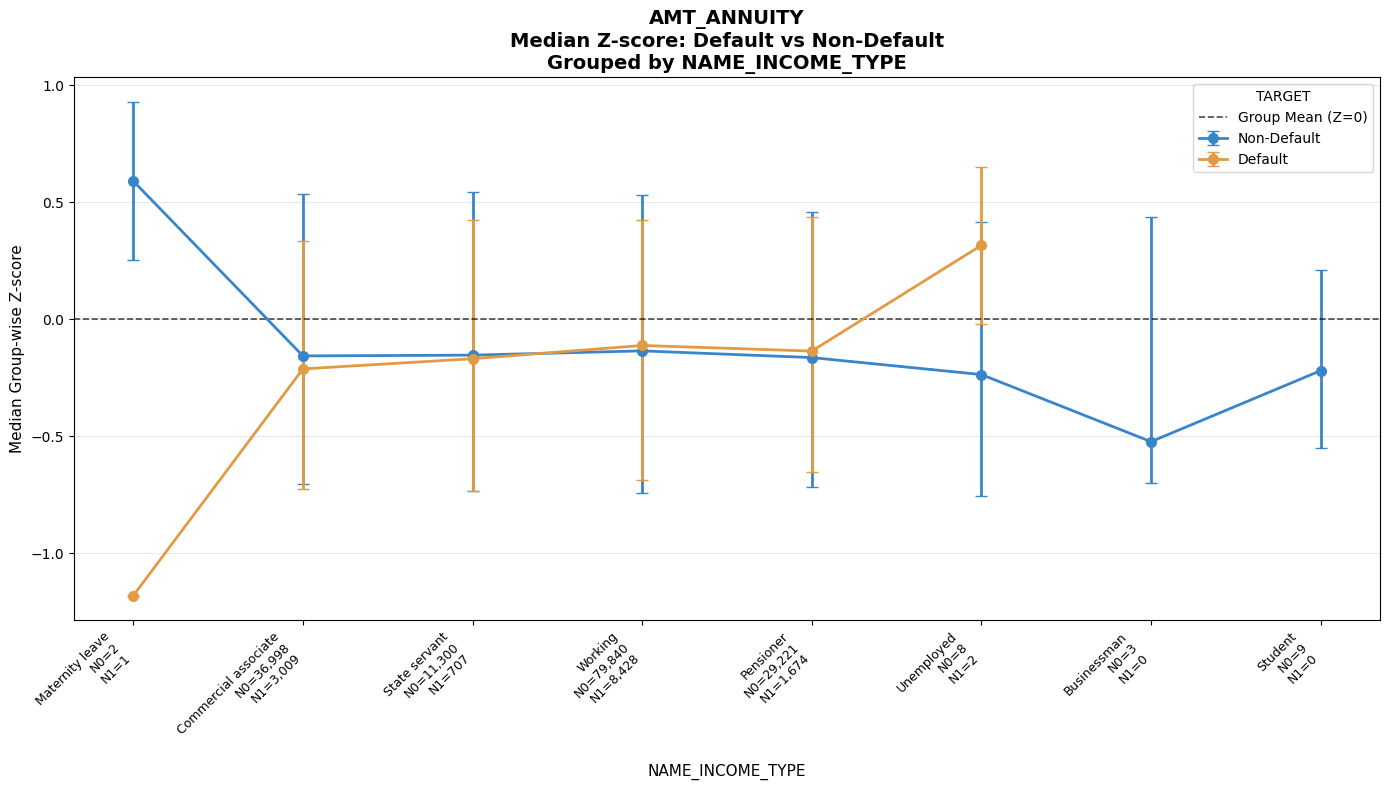

Saved: /content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON/median_lineplot_AMT_ANNUITY_NAME_INCOME_TYPE.png

ANALYSIS COMPLETED
Selected feature: AMT_ANNUITY

Output directory:
/content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON

Generated files:
class_comparison_AMT_ANNUITY_NAME_INCOME_TYPE.csv                              0.001 MB
class_comparison_AMT_ANNUITY_OCCUPATION_TYPE.csv                               0.003 MB
class_comparison_AMT_CREDIT_NAME_INCOME_TYPE.csv                               0.001 MB
class_comparison_AMT_CREDIT_OCCUPATION_TYPE.csv                                0.003 MB
class_comparison_AMT_INCOME_TOTAL_NAME_INCOME_TYPE.csv                         0.001 MB
class_comparison_AMT_INCOME_TOTAL_OCCUPATION_TYPE.csv                          0.003 MB
distribution_statistics_AMT_ANNUITY_NAME_INCOME_TYPE.csv                       0.002 MB
distribution_statistics_AMT_ANNUITY_OCCUPATION_TYPE.csv                        0.005 MB
distribution_statistics_AMT_CREDI

In [1]:

# ============================================================
# HOME CREDIT - GROUP-WISE Z-SCORE COMPARISON
#
# Objective:
#   Fix ONE financial feature.
#   Compare Default vs Non-Default Z-scores:
#       1. Within each OCCUPATION_TYPE
#       2. Within each NAME_INCOME_TYPE
#       3. Overall, across all observations
#
# Visualization:
#   Line plots comparing median Z-scores.
#   Error bars represent Q25 and Q75.
#
# No sampling.
# All available observations are used.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT_DIR = "/content/drive/MyDrive/Competition"

INPUT_DIR = os.path.join(
    ROOT_DIR,
    "output",
    "GROUP_ZSCORE_ANALYSIS"
)

OUTPUT_DIR = os.path.join(
    ROOT_DIR,
    "output",
    "ZSCORE_COMPARISON"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Select ONE financial feature for this experiment
# ------------------------------------------------------------

SELECTED_FEATURE = "AMT_ANNUITY"

# Available features:
# AMT_INCOME_TOTAL
# AMT_CREDIT
# AMT_ANNUITY
# AMT_GOODS_PRICE

GROUP_COLUMNS = [
    "OCCUPATION_TYPE",
    "NAME_INCOME_TYPE"
]

TARGET_COL = "TARGET"

TARGET_LABELS = {
    0: "Non-Default",
    1: "Default"
}

COLORS = {
    "Non-Default": "#3985CA",
    "Default": "#E29A45"
}

# ============================================================
# 2. LOAD FULL Z-SCORE DATA
# ============================================================

print("=" * 80)
print("LOADING FULL Z-SCORE DATA")
print("=" * 80)

COMPRESSED_PATH = os.path.join(
    INPUT_DIR,
    "group_wise_zscore_data.csv.gz"
)

UNCOMPRESSED_PATH = os.path.join(
    INPUT_DIR,
    "group_wise_zscore_data.csv"
)

if os.path.exists(COMPRESSED_PATH):

    DATA_PATH = COMPRESSED_PATH

elif os.path.exists(UNCOMPRESSED_PATH):

    DATA_PATH = UNCOMPRESSED_PATH

else:

    raise FileNotFoundError(
        "Could not find the Z-score data file."
    )

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Loaded:", DATA_PATH)
print("Data shape:", df.shape)

# ============================================================
# 3. VALIDATE SELECTED FEATURE
# ============================================================

if SELECTED_FEATURE not in [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]:

    raise ValueError(
        "Invalid SELECTED_FEATURE."
    )

required_columns = (
    GROUP_COLUMNS
    + [TARGET_COL]
    + [
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
        for group_col in GROUP_COLUMNS
    ]
)

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:

    raise ValueError(
        f"Missing columns: {missing}"
    )

print("\nSelected financial feature:")
print(SELECTED_FEATURE)

# ============================================================
# 4. GENERAL STATISTICS FUNCTION
# ============================================================

def calculate_distribution_statistics(data, value_col):

    records = []

    for target_value in [0, 1]:

        values = data.loc[
            data[TARGET_COL] == target_value,
            value_col
        ].dropna()

        values = values[
            np.isfinite(values)
        ]

        if len(values) == 0:

            records.append({
                "TARGET": target_value,
                "N": 0,
                "MEAN": np.nan,
                "MEDIAN": np.nan,
                "STD": np.nan,
                "Q25": np.nan,
                "Q75": np.nan
            })

            continue

        records.append({

            "TARGET": target_value,

            "N": len(values),

            "MEAN": values.mean(),

            "MEDIAN": values.median(),

            "STD": values.std(ddof=1),

            "Q25": values.quantile(0.25),

            "Q75": values.quantile(0.75)
        })

    return pd.DataFrame(records)


# ============================================================
# 5. OVERALL COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("OVERALL COMPARISON")
print("=" * 80)

overall_records = []

for group_col in GROUP_COLUMNS:

    z_col = (
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
    )

    overall_data = df[
        [TARGET_COL, z_col]
    ].copy()

    overall_data = overall_data.rename(
        columns={z_col: "Z_SCORE"}
    )

    overall_data = overall_data.dropna(
        subset=["Z_SCORE"]
    )

    overall_stats = (
        calculate_distribution_statistics(
            overall_data,
            "Z_SCORE"
        )
    )

    overall_stats.insert(
        0,
        "GROUP_COLUMN",
        group_col
    )

    overall_stats.insert(
        1,
        "GROUP",
        "ALL_GROUPS"
    )

    overall_records.append(
        overall_stats
    )

    print(f"\nGrouping: {group_col}")

    print(
        overall_stats.to_string(
            index=False
        )
    )

overall_summary = pd.concat(
    overall_records,
    ignore_index=True
)

overall_path = os.path.join(
    OUTPUT_DIR,
    f"overall_comparison_{SELECTED_FEATURE}.csv"
)

overall_summary.to_csv(
    overall_path,
    index=False
)

# ============================================================
# 6. GROUP-WISE COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("GROUP-WISE COMPARISON")
print("=" * 80)

for group_col in GROUP_COLUMNS:

    print("\n" + "-" * 80)
    print("GROUP:", group_col)
    print("-" * 80)

    z_col = (
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
    )

    analysis_df = df[
        [
            group_col,
            TARGET_COL,
            z_col
        ]
    ].copy()

    analysis_df = analysis_df.rename(
        columns={z_col: "Z_SCORE"}
    )

    analysis_df = analysis_df.dropna(
        subset=["Z_SCORE"]
    )

    analysis_df = analysis_df[
        np.isfinite(analysis_df["Z_SCORE"])
    ].copy()

    # --------------------------------------------------------
    # Calculate statistics separately for each group and class
    # --------------------------------------------------------

    records = []

    for group_value, group_data in analysis_df.groupby(
        group_col,
        dropna=False
    ):

        stats = calculate_distribution_statistics(
            group_data,
            "Z_SCORE"
        )

        for _, row in stats.iterrows():

            records.append({

                "GROUP_COLUMN": group_col,

                "GROUP": group_value,

                "TARGET": int(row["TARGET"]),

                "N": int(row["N"]),

                "MEAN": row["MEAN"],

                "MEDIAN": row["MEDIAN"],

                "STD": row["STD"],

                "Q25": row["Q25"],

                "Q75": row["Q75"]
            })

    group_stats = pd.DataFrame(
        records
    )

    # --------------------------------------------------------
    # Pivot statistics to compare classes
    # --------------------------------------------------------

    median_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="MEDIAN"
    )

    count_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="N"
    )

    mean_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="MEAN"
    )

    for target_value in [0, 1]:

        if target_value not in median_pivot.columns:

            median_pivot[target_value] = np.nan

        if target_value not in count_pivot.columns:

            count_pivot[target_value] = 0

        if target_value not in mean_pivot.columns:

            mean_pivot[target_value] = np.nan

    comparison = pd.DataFrame({

        "NON_DEFAULT_N": count_pivot[0],

        "DEFAULT_N": count_pivot[1],

        "NON_DEFAULT_MEDIAN": median_pivot[0],

        "DEFAULT_MEDIAN": median_pivot[1],

        "NON_DEFAULT_MEAN": mean_pivot[0],

        "DEFAULT_MEAN": mean_pivot[1]

    })

    comparison["MEDIAN_DIFFERENCE"] = (
        comparison["DEFAULT_MEDIAN"]
        - comparison["NON_DEFAULT_MEDIAN"]
    )

    comparison["MEAN_DIFFERENCE"] = (
        comparison["DEFAULT_MEAN"]
        - comparison["NON_DEFAULT_MEAN"]
    )

    comparison = comparison.reset_index()

    # --------------------------------------------------------
    # Sort categories by median difference.
    # This is a descriptive ordering, not a natural category order.
    # --------------------------------------------------------

    comparison = comparison.sort_values(
        "MEDIAN_DIFFERENCE",
        ascending=True,
        na_position="last"
    )

    print("\nComparison table:")

    print(
        comparison.to_string(
            index=False
        )
    )

    # --------------------------------------------------------
    # Save detailed statistics
    # --------------------------------------------------------

    stats_path = os.path.join(
        OUTPUT_DIR,
        f"distribution_statistics_{SELECTED_FEATURE}_{group_col}.csv"
    )

    group_stats.to_csv(
        stats_path,
        index=False
    )

    comparison_path = os.path.join(
        OUTPUT_DIR,
        f"class_comparison_{SELECTED_FEATURE}_{group_col}.csv"
    )

    comparison.to_csv(
        comparison_path,
        index=False
    )

    # ========================================================
    # 7. LINE PLOT - MEDIAN Z-SCORE
    # ========================================================

    print("\nGenerating line plot...")

    plot_order = comparison["GROUP"].tolist()

    fig, ax = plt.subplots(
        figsize=(max(14, len(plot_order) * 0.9), 8)
    )

    x_positions = np.arange(
        len(plot_order)
    )

    for target_value, label in TARGET_LABELS.items():

        class_stats = (
            group_stats[
                group_stats["TARGET"] == target_value
            ]
            .set_index("GROUP")
            .reindex(plot_order)
        )

        medians = class_stats["MEDIAN"].to_numpy(
            dtype=float
        )

        q25 = class_stats["Q25"].to_numpy(
            dtype=float
        )

        q75 = class_stats["Q75"].to_numpy(
            dtype=float
        )

        # Asymmetric error bars: Q25 to median and median to Q75
        lower_error = np.maximum(
            medians - q25,
            0
        )

        upper_error = np.maximum(
            q75 - medians,
            0
        )

        valid = np.isfinite(medians)

        ax.errorbar(
            x_positions[valid],
            medians[valid],
            yerr=np.vstack([
                lower_error[valid],
                upper_error[valid]
            ]),
            label=label,
            color=COLORS[label],
            marker="o",
            markersize=7,
            linewidth=2,
            capsize=4
        )

    # --------------------------------------------------------
    # Reference line
    # --------------------------------------------------------

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.2,
        alpha=0.7,
        label="Group Mean (Z=0)"
    )

    # --------------------------------------------------------
    # Category labels with actual class counts
    # --------------------------------------------------------

    tick_labels = []

    for _, row in comparison.iterrows():

        tick_labels.append(
            f"{row['GROUP']}\n"
            f"N0={int(row['NON_DEFAULT_N']):,}\n"
            f"N1={int(row['DEFAULT_N']):,}"
        )

    ax.set_xticks(
        x_positions
    )

    ax.set_xticklabels(
        tick_labels,
        rotation=45,
        ha="right",
        fontsize=9
    )

    ax.set_title(
        f"{SELECTED_FEATURE}\n"
        f"Median Z-score: Default vs Non-Default\n"
        f"Grouped by {group_col}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        group_col,
        fontsize=11
    )

    ax.set_ylabel(
        "Median Group-wise Z-score",
        fontsize=11
    )

    ax.legend(
        title="TARGET",
        fontsize=10
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plot_path = os.path.join(
        OUTPUT_DIR,
        f"median_lineplot_{SELECTED_FEATURE}_{group_col}.png"
    )

    fig.savefig(
        plot_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    print("Saved:", plot_path)

# ============================================================
# 8. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("ANALYSIS COMPLETED")
print("=" * 80)

print("Selected feature:", SELECTED_FEATURE)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    filepath = os.path.join(
        OUTPUT_DIR,
        filename
    )

    size_mb = (
        os.path.getsize(filepath)
        / (1024 ** 2)
    )

    print(
        f"{filename:75s} "
        f"{size_mb:8.3f} MB"
    )

print("\n" + "=" * 80)
print("ALL AVAILABLE OBSERVATIONS WERE USED.")
print("NO SAMPLING WAS PERFORMED.")
print("=" * 80)


LOADING FULL Z-SCORE DATA
Loaded: /content/drive/MyDrive/Competition/output/GROUP_ZSCORE_ANALYSIS/group_wise_zscore_data.csv.gz
Data shape: (171202, 15)

Selected financial feature:
AMT_GOODS_PRICE

OVERALL COMPARISON

Grouping: OCCUPATION_TYPE
   GROUP_COLUMN      GROUP  TARGET      N      MEAN    MEDIAN      STD       Q25      Q75
OCCUPATION_TYPE ALL_GROUPS       0 157381  0.010759 -0.187414 1.010864 -0.807575 0.491706
OCCUPATION_TYPE ALL_GROUPS       1  13821 -0.122517 -0.265082 0.857341 -0.795172 0.361975

Grouping: NAME_INCOME_TYPE
    GROUP_COLUMN      GROUP  TARGET      N      MEAN    MEDIAN      STD       Q25      Q75
NAME_INCOME_TYPE ALL_GROUPS       0 157381  0.012190 -0.195105 1.011289 -0.801930 0.515010
NAME_INCOME_TYPE ALL_GROUPS       1  13821 -0.138803 -0.303110 0.848886 -0.808652 0.321342

GROUP-WISE COMPARISON

--------------------------------------------------------------------------------
GROUP: OCCUPATION_TYPE
--------------------------------------------------------

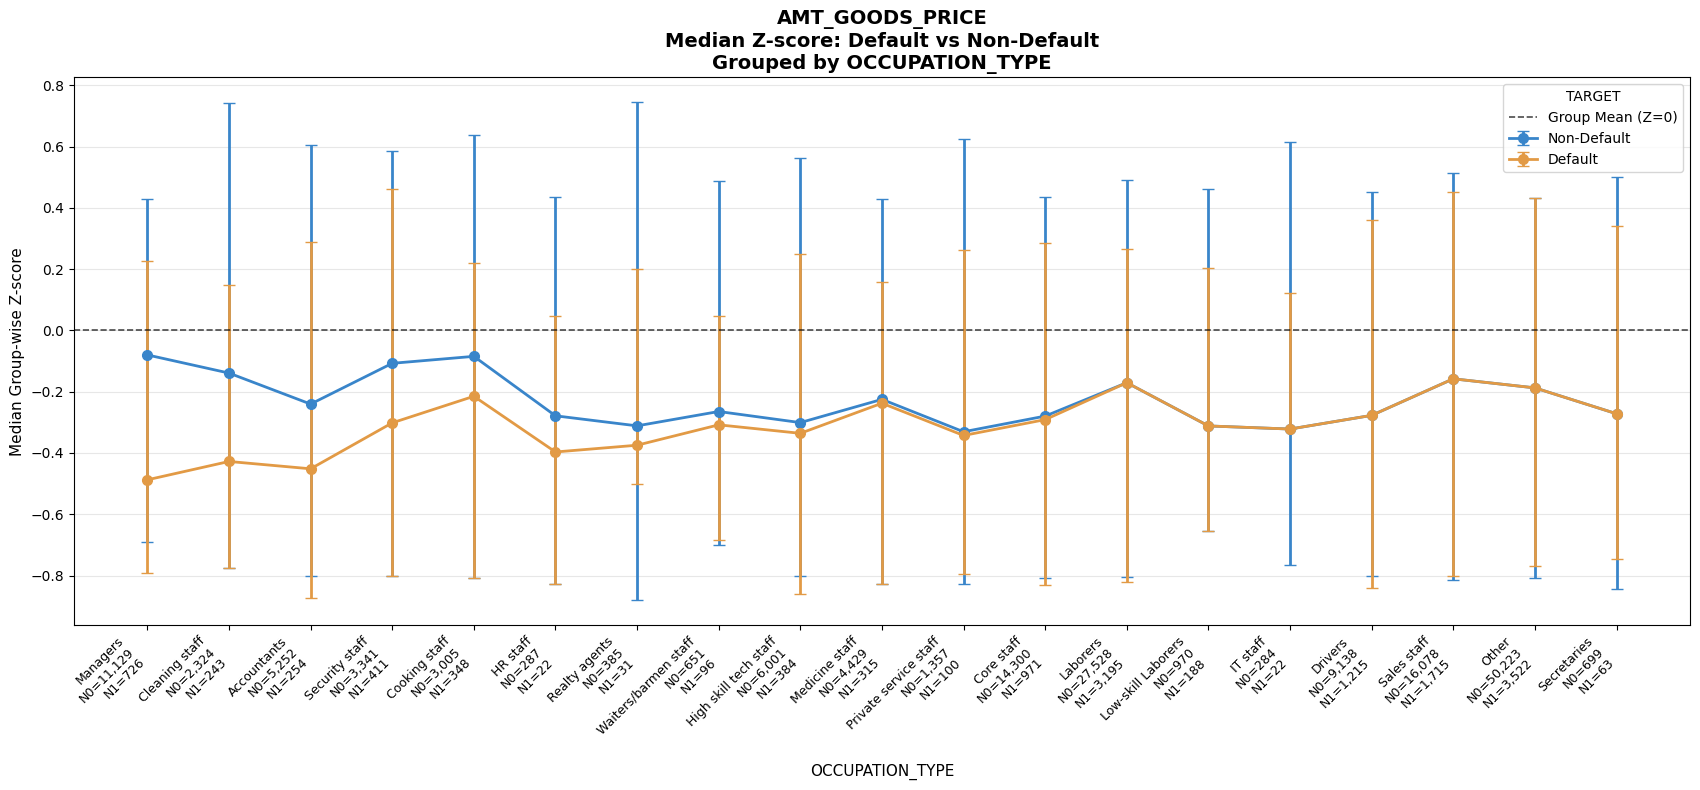

Saved: /content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON/median_lineplot_AMT_GOODS_PRICE_OCCUPATION_TYPE.png

--------------------------------------------------------------------------------
GROUP: NAME_INCOME_TYPE
--------------------------------------------------------------------------------

Comparison table:
               GROUP  NON_DEFAULT_N  DEFAULT_N  NON_DEFAULT_MEDIAN  DEFAULT_MEDIAN  NON_DEFAULT_MEAN  DEFAULT_MEAN  MEDIAN_DIFFERENCE  MEAN_DIFFERENCE
     Maternity leave              2          1            0.703100       -1.406199      7.030996e-01     -1.406199          -2.109299        -2.109299
Commercial associate          36998       3009           -0.325385       -0.381074      1.633877e-02     -0.200898          -0.055688        -0.217237
       State servant          11300        707           -0.310758       -0.366247      1.037794e-02     -0.165871          -0.055489        -0.176249
           Pensioner          29221       1674           -0.105322     

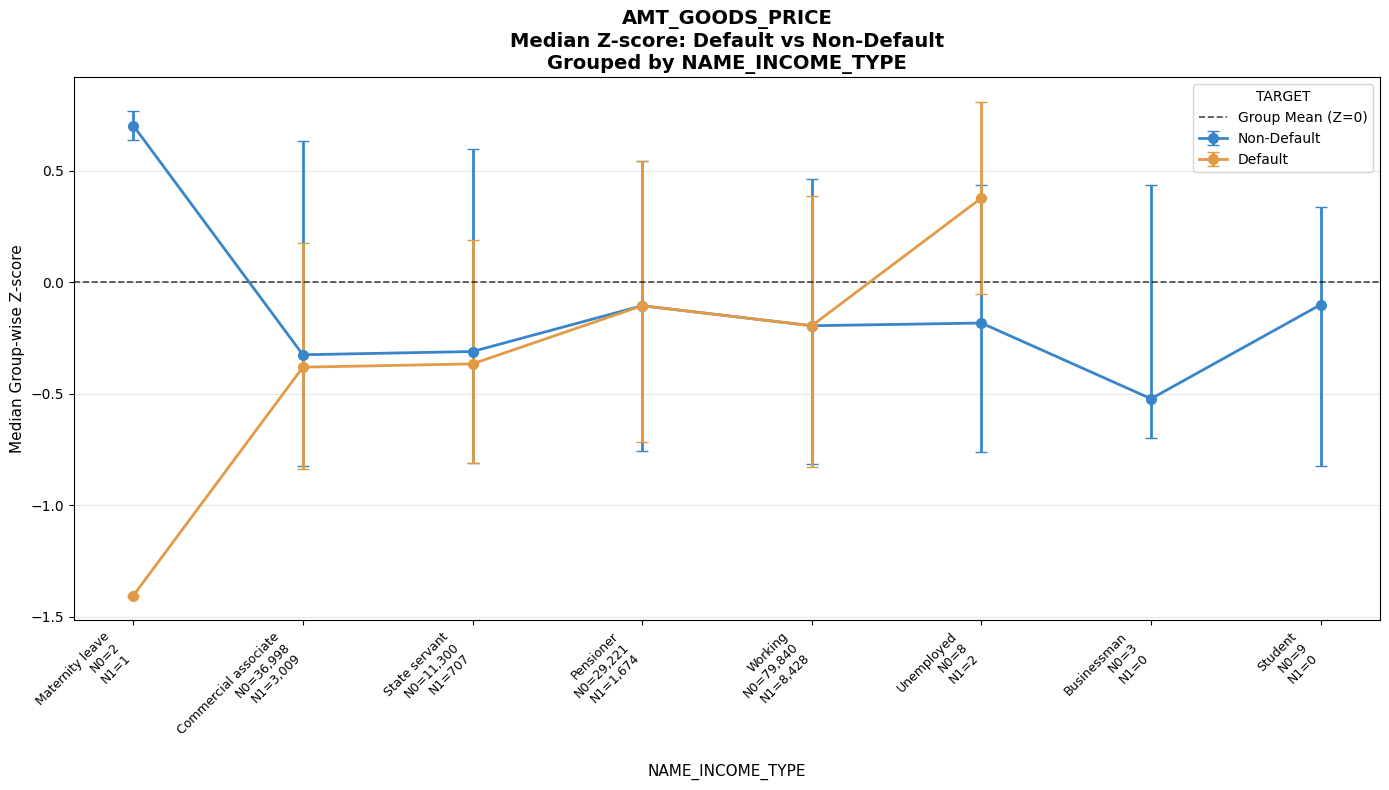

Saved: /content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON/median_lineplot_AMT_GOODS_PRICE_NAME_INCOME_TYPE.png

ANALYSIS COMPLETED
Selected feature: AMT_GOODS_PRICE

Output directory:
/content/drive/MyDrive/Competition/output/ZSCORE_COMPARISON

Generated files:
class_comparison_AMT_ANNUITY_NAME_INCOME_TYPE.csv                              0.001 MB
class_comparison_AMT_ANNUITY_OCCUPATION_TYPE.csv                               0.003 MB
class_comparison_AMT_CREDIT_NAME_INCOME_TYPE.csv                               0.001 MB
class_comparison_AMT_CREDIT_OCCUPATION_TYPE.csv                                0.003 MB
class_comparison_AMT_GOODS_PRICE_NAME_INCOME_TYPE.csv                          0.001 MB
class_comparison_AMT_GOODS_PRICE_OCCUPATION_TYPE.csv                           0.003 MB
class_comparison_AMT_INCOME_TOTAL_NAME_INCOME_TYPE.csv                         0.001 MB
class_comparison_AMT_INCOME_TOTAL_OCCUPATION_TYPE.csv                          0.003 MB
distribution_statistics_A

In [2]:

# ============================================================
# HOME CREDIT - GROUP-WISE Z-SCORE COMPARISON
#
# Objective:
#   Fix ONE financial feature.
#   Compare Default vs Non-Default Z-scores:
#       1. Within each OCCUPATION_TYPE
#       2. Within each NAME_INCOME_TYPE
#       3. Overall, across all observations
#
# Visualization:
#   Line plots comparing median Z-scores.
#   Error bars represent Q25 and Q75.
#
# No sampling.
# All available observations are used.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT_DIR = "/content/drive/MyDrive/Competition"

INPUT_DIR = os.path.join(
    ROOT_DIR,
    "output",
    "GROUP_ZSCORE_ANALYSIS"
)

OUTPUT_DIR = os.path.join(
    ROOT_DIR,
    "output",
    "ZSCORE_COMPARISON"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Select ONE financial feature for this experiment
# ------------------------------------------------------------

SELECTED_FEATURE = "AMT_GOODS_PRICE"

# Available features:
# AMT_INCOME_TOTAL
# AMT_CREDIT
# AMT_ANNUITY
# AMT_GOODS_PRICE

GROUP_COLUMNS = [
    "OCCUPATION_TYPE",
    "NAME_INCOME_TYPE"
]

TARGET_COL = "TARGET"

TARGET_LABELS = {
    0: "Non-Default",
    1: "Default"
}

COLORS = {
    "Non-Default": "#3985CA",
    "Default": "#E29A45"
}

# ============================================================
# 2. LOAD FULL Z-SCORE DATA
# ============================================================

print("=" * 80)
print("LOADING FULL Z-SCORE DATA")
print("=" * 80)

COMPRESSED_PATH = os.path.join(
    INPUT_DIR,
    "group_wise_zscore_data.csv.gz"
)

UNCOMPRESSED_PATH = os.path.join(
    INPUT_DIR,
    "group_wise_zscore_data.csv"
)

if os.path.exists(COMPRESSED_PATH):

    DATA_PATH = COMPRESSED_PATH

elif os.path.exists(UNCOMPRESSED_PATH):

    DATA_PATH = UNCOMPRESSED_PATH

else:

    raise FileNotFoundError(
        "Could not find the Z-score data file."
    )

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Loaded:", DATA_PATH)
print("Data shape:", df.shape)

# ============================================================
# 3. VALIDATE SELECTED FEATURE
# ============================================================

if SELECTED_FEATURE not in [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]:

    raise ValueError(
        "Invalid SELECTED_FEATURE."
    )

required_columns = (
    GROUP_COLUMNS
    + [TARGET_COL]
    + [
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
        for group_col in GROUP_COLUMNS
    ]
)

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:

    raise ValueError(
        f"Missing columns: {missing}"
    )

print("\nSelected financial feature:")
print(SELECTED_FEATURE)

# ============================================================
# 4. GENERAL STATISTICS FUNCTION
# ============================================================

def calculate_distribution_statistics(data, value_col):

    records = []

    for target_value in [0, 1]:

        values = data.loc[
            data[TARGET_COL] == target_value,
            value_col
        ].dropna()

        values = values[
            np.isfinite(values)
        ]

        if len(values) == 0:

            records.append({
                "TARGET": target_value,
                "N": 0,
                "MEAN": np.nan,
                "MEDIAN": np.nan,
                "STD": np.nan,
                "Q25": np.nan,
                "Q75": np.nan
            })

            continue

        records.append({

            "TARGET": target_value,

            "N": len(values),

            "MEAN": values.mean(),

            "MEDIAN": values.median(),

            "STD": values.std(ddof=1),

            "Q25": values.quantile(0.25),

            "Q75": values.quantile(0.75)
        })

    return pd.DataFrame(records)


# ============================================================
# 5. OVERALL COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("OVERALL COMPARISON")
print("=" * 80)

overall_records = []

for group_col in GROUP_COLUMNS:

    z_col = (
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
    )

    overall_data = df[
        [TARGET_COL, z_col]
    ].copy()

    overall_data = overall_data.rename(
        columns={z_col: "Z_SCORE"}
    )

    overall_data = overall_data.dropna(
        subset=["Z_SCORE"]
    )

    overall_stats = (
        calculate_distribution_statistics(
            overall_data,
            "Z_SCORE"
        )
    )

    overall_stats.insert(
        0,
        "GROUP_COLUMN",
        group_col
    )

    overall_stats.insert(
        1,
        "GROUP",
        "ALL_GROUPS"
    )

    overall_records.append(
        overall_stats
    )

    print(f"\nGrouping: {group_col}")

    print(
        overall_stats.to_string(
            index=False
        )
    )

overall_summary = pd.concat(
    overall_records,
    ignore_index=True
)

overall_path = os.path.join(
    OUTPUT_DIR,
    f"overall_comparison_{SELECTED_FEATURE}.csv"
)

overall_summary.to_csv(
    overall_path,
    index=False
)

# ============================================================
# 6. GROUP-WISE COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("GROUP-WISE COMPARISON")
print("=" * 80)

for group_col in GROUP_COLUMNS:

    print("\n" + "-" * 80)
    print("GROUP:", group_col)
    print("-" * 80)

    z_col = (
        f"Z_{SELECTED_FEATURE}_BY_{group_col}"
    )

    analysis_df = df[
        [
            group_col,
            TARGET_COL,
            z_col
        ]
    ].copy()

    analysis_df = analysis_df.rename(
        columns={z_col: "Z_SCORE"}
    )

    analysis_df = analysis_df.dropna(
        subset=["Z_SCORE"]
    )

    analysis_df = analysis_df[
        np.isfinite(analysis_df["Z_SCORE"])
    ].copy()

    # --------------------------------------------------------
    # Calculate statistics separately for each group and class
    # --------------------------------------------------------

    records = []

    for group_value, group_data in analysis_df.groupby(
        group_col,
        dropna=False
    ):

        stats = calculate_distribution_statistics(
            group_data,
            "Z_SCORE"
        )

        for _, row in stats.iterrows():

            records.append({

                "GROUP_COLUMN": group_col,

                "GROUP": group_value,

                "TARGET": int(row["TARGET"]),

                "N": int(row["N"]),

                "MEAN": row["MEAN"],

                "MEDIAN": row["MEDIAN"],

                "STD": row["STD"],

                "Q25": row["Q25"],

                "Q75": row["Q75"]
            })

    group_stats = pd.DataFrame(
        records
    )

    # --------------------------------------------------------
    # Pivot statistics to compare classes
    # --------------------------------------------------------

    median_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="MEDIAN"
    )

    count_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="N"
    )

    mean_pivot = group_stats.pivot(
        index="GROUP",
        columns="TARGET",
        values="MEAN"
    )

    for target_value in [0, 1]:

        if target_value not in median_pivot.columns:

            median_pivot[target_value] = np.nan

        if target_value not in count_pivot.columns:

            count_pivot[target_value] = 0

        if target_value not in mean_pivot.columns:

            mean_pivot[target_value] = np.nan

    comparison = pd.DataFrame({

        "NON_DEFAULT_N": count_pivot[0],

        "DEFAULT_N": count_pivot[1],

        "NON_DEFAULT_MEDIAN": median_pivot[0],

        "DEFAULT_MEDIAN": median_pivot[1],

        "NON_DEFAULT_MEAN": mean_pivot[0],

        "DEFAULT_MEAN": mean_pivot[1]

    })

    comparison["MEDIAN_DIFFERENCE"] = (
        comparison["DEFAULT_MEDIAN"]
        - comparison["NON_DEFAULT_MEDIAN"]
    )

    comparison["MEAN_DIFFERENCE"] = (
        comparison["DEFAULT_MEAN"]
        - comparison["NON_DEFAULT_MEAN"]
    )

    comparison = comparison.reset_index()

    # --------------------------------------------------------
    # Sort categories by median difference.
    # This is a descriptive ordering, not a natural category order.
    # --------------------------------------------------------

    comparison = comparison.sort_values(
        "MEDIAN_DIFFERENCE",
        ascending=True,
        na_position="last"
    )

    print("\nComparison table:")

    print(
        comparison.to_string(
            index=False
        )
    )

    # --------------------------------------------------------
    # Save detailed statistics
    # --------------------------------------------------------

    stats_path = os.path.join(
        OUTPUT_DIR,
        f"distribution_statistics_{SELECTED_FEATURE}_{group_col}.csv"
    )

    group_stats.to_csv(
        stats_path,
        index=False
    )

    comparison_path = os.path.join(
        OUTPUT_DIR,
        f"class_comparison_{SELECTED_FEATURE}_{group_col}.csv"
    )

    comparison.to_csv(
        comparison_path,
        index=False
    )

    # ========================================================
    # 7. LINE PLOT - MEDIAN Z-SCORE
    # ========================================================

    print("\nGenerating line plot...")

    plot_order = comparison["GROUP"].tolist()

    fig, ax = plt.subplots(
        figsize=(max(14, len(plot_order) * 0.9), 8)
    )

    x_positions = np.arange(
        len(plot_order)
    )

    for target_value, label in TARGET_LABELS.items():

        class_stats = (
            group_stats[
                group_stats["TARGET"] == target_value
            ]
            .set_index("GROUP")
            .reindex(plot_order)
        )

        medians = class_stats["MEDIAN"].to_numpy(
            dtype=float
        )

        q25 = class_stats["Q25"].to_numpy(
            dtype=float
        )

        q75 = class_stats["Q75"].to_numpy(
            dtype=float
        )

        # Asymmetric error bars: Q25 to median and median to Q75
        lower_error = np.maximum(
            medians - q25,
            0
        )

        upper_error = np.maximum(
            q75 - medians,
            0
        )

        valid = np.isfinite(medians)

        ax.errorbar(
            x_positions[valid],
            medians[valid],
            yerr=np.vstack([
                lower_error[valid],
                upper_error[valid]
            ]),
            label=label,
            color=COLORS[label],
            marker="o",
            markersize=7,
            linewidth=2,
            capsize=4
        )

    # --------------------------------------------------------
    # Reference line
    # --------------------------------------------------------

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.2,
        alpha=0.7,
        label="Group Mean (Z=0)"
    )

    # --------------------------------------------------------
    # Category labels with actual class counts
    # --------------------------------------------------------

    tick_labels = []

    for _, row in comparison.iterrows():

        tick_labels.append(
            f"{row['GROUP']}\n"
            f"N0={int(row['NON_DEFAULT_N']):,}\n"
            f"N1={int(row['DEFAULT_N']):,}"
        )

    ax.set_xticks(
        x_positions
    )

    ax.set_xticklabels(
        tick_labels,
        rotation=45,
        ha="right",
        fontsize=9
    )

    ax.set_title(
        f"{SELECTED_FEATURE}\n"
        f"Median Z-score: Default vs Non-Default\n"
        f"Grouped by {group_col}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        group_col,
        fontsize=11
    )

    ax.set_ylabel(
        "Median Group-wise Z-score",
        fontsize=11
    )

    ax.legend(
        title="TARGET",
        fontsize=10
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plot_path = os.path.join(
        OUTPUT_DIR,
        f"median_lineplot_{SELECTED_FEATURE}_{group_col}.png"
    )

    fig.savefig(
        plot_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    print("Saved:", plot_path)

# ============================================================
# 8. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("ANALYSIS COMPLETED")
print("=" * 80)

print("Selected feature:", SELECTED_FEATURE)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    filepath = os.path.join(
        OUTPUT_DIR,
        filename
    )

    size_mb = (
        os.path.getsize(filepath)
        / (1024 ** 2)
    )

    print(
        f"{filename:75s} "
        f"{size_mb:8.3f} MB"
    )

print("\n" + "=" * 80)
print("ALL AVAILABLE OBSERVATIONS WERE USED.")
print("NO SAMPLING WAS PERFORMED.")
print("=" * 80)


In [4]:

# ============================================================
# HOME CREDIT - CATBOOST FEATURE COMBINATION SEARCH
# GOOGLE COLAB - CPU ONLY
#
# RAW FEATURES:
#   All original features retained.
#
# ONLY TWO ENGINEERED FEATURES:
#   1. CREDIT_TERM
#   2. NAME_INCOME_TYPE_DEFAULT_RATE
#
# TARGET ENCODING:
#   - Smoothed default rate by NAME_INCOME_TYPE
#   - 5-Fold Out-of-Fold encoding for training rows
#   - Validation encoding uses training split only
#   - Final training encoding is OOF
#   - Test encoding uses all training rows
#
# EXPERIMENTS:
#   2^2 = 4 combinations
#
# VALIDATION:
#   One fixed stratified 80/20 split
#
# FINAL:
#   - Select best validation ROC-AUC
#   - Refit on all training rows
#   - Generate submission
#   - Save all artifacts to Google Drive
# ============================================================


# ============================================================
# 1. INSTALL AND IMPORT
# ============================================================

!pip install -q catboost

from google.colab import drive
drive.mount('/content/drive')

import os
import gc
import json
import warnings

from pathlib import Path
from itertools import combinations
from time import perf_counter

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score

from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")


# ============================================================
# 2. PROJECT PATHS
# ============================================================

ROOT_DIR = Path("/content/drive/MyDrive/Competition")

os.chdir(ROOT_DIR)

current_dir = Path(os.getcwd())

train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

OUTPUT_ROOT = ROOT_DIR / "output"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 78)
print("PROJECT PATH VERIFICATION")
print("=" * 78)

print("Working directory:", current_dir)
print("Train exists:", train_file.exists())
print("Test exists:", test_file.exists())
print("Sample submission exists:", sample_sub_file.exists())

if not train_file.exists():
    raise FileNotFoundError(train_file)

if not test_file.exists():
    raise FileNotFoundError(test_file)

if not sample_sub_file.exists():
    raise FileNotFoundError(sample_sub_file)


# ============================================================
# 3. CONFIGURATION
# ============================================================

TASK_TYPE = "CPU"

CPU_THREADS = max(1, os.cpu_count() or 1)

RANDOM_SEED = 42

VALIDATION_SIZE = 0.20

MAX_ITERATIONS = 3000
LEARNING_RATE = 0.04
DEPTH = 7
EARLY_STOPPING_ROUNDS = 100
LOG_PERIOD = 200
L2_LEAF_REG = 10

# Target encoding configuration
TARGET_ENCODING_FOLDS = 5

# Larger values shrink small groups more strongly
TARGET_ENCODING_SMOOTHING = 100


# ============================================================
# 4. ONLY TWO ENGINEERED FEATURES
# ============================================================

ENGINEERED_FEATURES = [

    "CREDIT_TERM",

    "NAME_INCOME_TYPE_DEFAULT_RATE"

]

TARGET_RATE_FEATURE = "NAME_INCOME_TYPE_DEFAULT_RATE"


# ============================================================
# 5. OUTPUT FILES
# ============================================================

RUN_TAG = "credit_term_income_type_default_rate_cpu"

REPORT_FILE = (
    OUTPUT_ROOT /
    f"feature_combination_results_{RUN_TAG}.csv"
)

BEST_MODEL_FILE = (
    OUTPUT_ROOT /
    f"best_catboost_feature_subset_{RUN_TAG}.cbm"
)

BEST_FEATURES_FILE = (
    OUTPUT_ROOT /
    f"best_feature_subset_{RUN_TAG}.json"
)

BEST_SUBMISSION_FILE = (
    OUTPUT_ROOT /
    f"submission_best_feature_subset_{RUN_TAG}.csv"
)


# ============================================================
# 6. CREDIT_TERM FEATURE
# ============================================================

def make_engineered_features(df):

    features = pd.DataFrame(index=df.index)

    features["CREDIT_TERM"] = (

        df["AMT_CREDIT"] /

        df["AMT_ANNUITY"].replace(0, np.nan)

    )

    features.replace(
        [np.inf, -np.inf],
        np.nan,
        inplace=True
    )

    return features


# ============================================================
# 7. SMOOTHED TARGET ENCODING
# ============================================================

def fit_income_type_encoder(groups, target):

    """
    Calculate smoothed default rate for each NAME_INCOME_TYPE.

    Formula:

        encoded_rate =
            (group_defaults + smoothing * global_default_rate)
            / (group_count + smoothing)

    This shrinks small groups toward the global default rate.
    """

    groups = pd.Series(groups).astype(str).reset_index(drop=True)

    target = np.asarray(target, dtype=np.float64)

    if len(groups) != len(target):
        raise ValueError(
            "Groups and target have different lengths."
        )

    global_rate = float(target.mean())

    temp = pd.DataFrame({

        "GROUP": groups.to_numpy(),

        "TARGET": target

    })

    group_stats = temp.groupby("GROUP")["TARGET"].agg(

        ["sum", "count"]

    )

    mapping = (

        group_stats["sum"] +

        TARGET_ENCODING_SMOOTHING * global_rate

    ) / (

        group_stats["count"] +

        TARGET_ENCODING_SMOOTHING

    )

    return global_rate, mapping


def transform_income_type_encoder(groups, global_rate, mapping):

    """

    Transform NAME_INCOME_TYPE using a previously fitted mapping.

    Unknown categories receive the global default rate.
    """

    groups = pd.Series(groups).astype(str)

    encoded = (

        groups.map(mapping)

        .fillna(global_rate)

        .to_numpy(dtype=np.float32)

    )

    return encoded


# ============================================================
# 8. OUT-OF-FOLD TARGET ENCODING
# ============================================================

def make_oof_income_type_encoding(X_part, y_part):

    """

    Each training row receives an encoding calculated without
    using its own TARGET.

    For every fold:
        1. Fit the encoder on the other folds.
        2. Transform the held-out fold.
    """

    groups = (

        X_part["NAME_INCOME_TYPE"]

        .astype(str)

        .reset_index(drop=True)

    )

    target = np.asarray(y_part, dtype=np.int64)

    if len(groups) != len(target):
        raise ValueError(
            "X_part and y_part have different lengths."
        )

    class_counts = np.bincount(target)

    if class_counts.min() < TARGET_ENCODING_FOLDS:
        raise ValueError(
            "Not enough observations for the requested "
            "stratified target-encoding folds."
        )

    splitter = StratifiedKFold(

        n_splits=TARGET_ENCODING_FOLDS,

        shuffle=True,

        random_state=RANDOM_SEED

    )

    oof_values = np.full(

        len(target),

        np.nan,

        dtype=np.float32

    )

    for fit_positions, oof_positions in splitter.split(

        np.zeros(len(target)),

        target

    ):

        fold_global_rate, fold_mapping = fit_income_type_encoder(

            groups.iloc[fit_positions],

            target[fit_positions]

        )

        oof_values[oof_positions] = transform_income_type_encoder(

            groups.iloc[oof_positions],

            fold_global_rate,

            fold_mapping

        )

    if np.isnan(oof_values).any():

        raise RuntimeError(
            "Some OOF target-encoded values were not generated."
        )

    return pd.Series(

        oof_values,

        index=X_part.index,

        name=TARGET_RATE_FEATURE

    )


# ============================================================
# 9. LOAD DATA
# ============================================================

print("\n" + "=" * 78)
print("LOADING DATA")
print("=" * 78)

started_loading = perf_counter()

train = pd.read_csv(
    train_file,
    low_memory=False
)

test = pd.read_csv(
    test_file,
    low_memory=False
)

sample_sub = pd.read_csv(
    sample_sub_file,
    low_memory=False
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_sub.shape)

print(
    "Loading time:",
    round(perf_counter() - started_loading, 2),
    "seconds"
)


# ============================================================
# 10. VERIFY REQUIRED COLUMNS
# ============================================================

required_train = {

    "TARGET",
    "SK_ID_CURR",

    "AMT_CREDIT",
    "AMT_ANNUITY",

    "NAME_INCOME_TYPE"

}

required_test = {

    "SK_ID_CURR",

    "AMT_CREDIT",
    "AMT_ANNUITY",

    "NAME_INCOME_TYPE"

}

required_sample = {

    "SK_ID_CURR",
    "TARGET"

}


if not required_train.issubset(train.columns):

    missing = required_train - set(train.columns)

    raise ValueError(
        f"Missing training columns: {missing}"
    )


if not required_test.issubset(test.columns):

    missing = required_test - set(test.columns)

    raise ValueError(
        f"Missing test columns: {missing}"
    )


if not required_sample.issubset(sample_sub.columns):

    missing = required_sample - set(sample_sub.columns)

    raise ValueError(
        f"Missing sample submission columns: {missing}"
    )


# ============================================================
# 11. VERIFY IDS
# ============================================================

if train["SK_ID_CURR"].duplicated().any():

    raise ValueError(
        "Duplicate SK_ID_CURR values found in train."
    )


if test["SK_ID_CURR"].duplicated().any():

    raise ValueError(
        "Duplicate SK_ID_CURR values found in test."
    )


if sample_sub["SK_ID_CURR"].duplicated().any():

    raise ValueError(
        "Duplicate SK_ID_CURR values found in sample submission."
    )


if set(test["SK_ID_CURR"]) != set(sample_sub["SK_ID_CURR"]):

    raise ValueError(
        "Test IDs and sample submission IDs do not match."
    )


print("\nID verification passed.")


# ============================================================
# 12. TARGET AND ORIGINAL FEATURE MATRICES
# ============================================================

y = train["TARGET"].astype(int)

if set(y.unique()) != {0, 1}:

    raise ValueError(
        f"Unexpected target classes: {y.unique()}"
    )


X_base = train.drop(

    columns=["TARGET", "SK_ID_CURR"]

).copy()


X_test_base = test.drop(

    columns=["SK_ID_CURR"]

).copy()


sample_ids = test["SK_ID_CURR"].copy()


# ============================================================
# 13. VERIFY TRAIN / TEST FEATURE ALIGNMENT
# ============================================================

missing_test_cols = (

    set(X_base.columns) -

    set(X_test_base.columns)

)


extra_test_cols = (

    set(X_test_base.columns) -

    set(X_base.columns)

)


if missing_test_cols or extra_test_cols:

    raise ValueError(

        "Train/test columns differ.\n"

        f"Missing in test: {missing_test_cols}\n"

        f"Extra in test: {extra_test_cols}"

    )


X_test_base = X_test_base.reindex(

    columns=X_base.columns

).copy()


if set(ENGINEERED_FEATURES) & set(X_base.columns):

    raise ValueError(

        "An engineered feature already exists in raw features."

    )


# ============================================================
# 14. TARGET DISTRIBUTION
# ============================================================

print("\n" + "=" * 78)
print("TARGET DISTRIBUTION")
print("=" * 78)

print("\nTarget counts:")
print(y.value_counts().sort_index())

print("\nTarget proportions:")
print(

    y.value_counts(

        normalize=True

    ).sort_index().round(4)

)


# ============================================================
# 15. CATEGORICAL FEATURES
# ============================================================

cat_features = X_base.select_dtypes(

    include=["object", "category"]

).columns.tolist()


print("\n" + "=" * 78)
print("CATEGORICAL FEATURES")
print("=" * 78)

print(
    "Categorical feature count:",
    len(cat_features)
)

print(cat_features)


# Convert categorical columns consistently.
# Missing values remain a separate category.

for col in cat_features:

    X_base[col] = (

        X_base[col]

        .astype("object")

        .where(

            X_base[col].notna(),

            "__MISSING__"

        )

        .astype(str)

    )

    X_test_base[col] = (

        X_test_base[col]

        .astype("object")

        .where(

            X_test_base[col].notna(),

            "__MISSING__"

        )

        .astype(str)

    )


# ============================================================
# 16. BUILD CREDIT_TERM
# ============================================================

print("\n" + "=" * 78)
print("BUILDING CREDIT_TERM")
print("=" * 78)

engineered_train = make_engineered_features(X_base)

engineered_test = make_engineered_features(X_test_base)

assert engineered_train.columns.tolist() == ["CREDIT_TERM"]

assert engineered_test.columns.tolist() == ["CREDIT_TERM"]


# Combine raw and CREDIT_TERM features.
# NAME_INCOME_TYPE_DEFAULT_RATE is added separately
# using the correct encoding for each data partition.

X_all = pd.concat(

    [

        X_base,

        engineered_train

    ],

    axis=1

)


X_test_all = pd.concat(

    [

        X_test_base,

        engineered_test

    ],

    axis=1

)


if not X_all.columns.equals(X_test_all.columns):

    raise ValueError(
        "Train/test feature names or order do not match."
    )


base_columns = X_base.columns.tolist()


print("Original feature count:", len(base_columns))

print("Engineered feature candidates:", ENGINEERED_FEATURES)

print("Total available feature count:", len(base_columns) + 1)


# ============================================================
# 17. FIXED STRATIFIED VALIDATION SPLIT
# ============================================================

print("\n" + "=" * 78)
print("CREATING VALIDATION SPLIT")
print("=" * 78)

all_indices = np.arange(len(y))


train_idx, valid_idx = train_test_split(

    all_indices,

    test_size=VALIDATION_SIZE,

    random_state=RANDOM_SEED,

    stratify=y

)


y_train = y.iloc[train_idx].copy()

y_valid = y.iloc[valid_idx].copy()


print("Training rows:", len(train_idx))

print("Validation rows:", len(valid_idx))


print("\nTraining target proportions:")

print(

    y_train.value_counts(

        normalize=True

    ).sort_index().round(4)

)


print("\nValidation target proportions:")

print(

    y_valid.value_counts(

        normalize=True

    ).sort_index().round(4)

)


# ============================================================
# 18. CREATE LEAKAGE-SAFE TARGET ENCODING
#     FOR VALIDATION EXPERIMENTS
# ============================================================

print("\n" + "=" * 78)
print("CREATING TARGET ENCODING FOR VALIDATION")
print("=" * 78)


X_train_base = X_base.iloc[train_idx].copy()

X_valid_base = X_base.iloc[valid_idx].copy()


# Training rows receive OOF encodings.
# Each row's own TARGET is excluded from its encoding.

train_income_type_rate = make_oof_income_type_encoding(

    X_train_base,

    y_train

)


# Validation rows use an encoder fitted only on training rows.

validation_global_rate, validation_mapping = fit_income_type_encoder(

    X_train_base["NAME_INCOME_TYPE"],

    y_train

)


valid_income_type_rate = transform_income_type_encoder(

    X_valid_base["NAME_INCOME_TYPE"],

    validation_global_rate,

    validation_mapping

)


# Create the matrices used in the feature search.

X_train_search = X_all.iloc[train_idx].copy()

X_valid_search = X_all.iloc[valid_idx].copy()


X_train_search[TARGET_RATE_FEATURE] = (

    train_income_type_rate.to_numpy()

)


X_valid_search[TARGET_RATE_FEATURE] = (

    valid_income_type_rate

)


print("OOF training encoding created.")

print("Validation encoding created.")

print(
    "Training encoding mean:",
    round(float(X_train_search[TARGET_RATE_FEATURE].mean()), 6)
)

print(
    "Validation encoding mean:",
    round(float(X_valid_search[TARGET_RATE_FEATURE].mean()), 6)
)


# ============================================================
# 19. GENERATE FOUR FEATURE COMBINATIONS
# ============================================================

all_combinations = []


for k in range(len(ENGINEERED_FEATURES) + 1):

    all_combinations.extend(

        combinations(

            ENGINEERED_FEATURES,

            k

        )

    )


EXPECTED_COMBINATIONS = 2 ** len(ENGINEERED_FEATURES)


if len(all_combinations) != EXPECTED_COMBINATIONS:

    raise RuntimeError(
        "Unexpected number of feature combinations."
    )


print("\n" + "=" * 78)
print("FEATURE COMBINATIONS")
print("=" * 78)

print("Number of engineered features:", len(ENGINEERED_FEATURES))

print("Number of combinations:", len(all_combinations))


for i, combo in enumerate(all_combinations, start=1):

    print(

        f"Experiment {i}: "

        f"{list(combo) if combo else 'NONE (original features only)'}"

    )


# ============================================================
# 20. CATBOOST CPU PARAMETERS
# ============================================================

model_params = {

    "iterations": MAX_ITERATIONS,

    "learning_rate": LEARNING_RATE,

    "depth": DEPTH,

    "loss_function": "Logloss",

    "eval_metric": "AUC",

    "random_seed": RANDOM_SEED,

    "allow_writing_files": False,

    "task_type": "CPU",

    "thread_count": CPU_THREADS,

    "l2_leaf_reg": L2_LEAF_REG

}


# ============================================================
# 21. INITIALIZE SEARCH
# ============================================================

results = []

best_auc = -np.inf

best_combo = None

best_iteration_zero_based = None


# ============================================================
# 22. REPORT SAVING FUNCTION
# ============================================================

def save_report(rows):

    if not rows:
        return

    report = pd.DataFrame(rows)

    if "validation_auc" in report.columns:

        report = report.sort_values(

            "validation_auc",

            ascending=False,

            na_position="last"

        )

    report.to_csv(

        REPORT_FILE,

        index=False

    )


# ============================================================
# 23. RUN ALL FOUR FEATURE COMBINATIONS
# ============================================================

search_started = perf_counter()


for run_number, combo in enumerate(all_combinations, start=1):

    combo = tuple(combo)

    combo_label = (

        "; ".join(combo)

        if combo

        else "NONE (original features only)"

    )

    feature_columns = (

        base_columns +

        list(combo)

    )

    print("\n" + "=" * 78)

    print(
        f"EXPERIMENT {run_number}/{len(all_combinations)}"
    )

    print(
        "Added engineered features:",
        combo_label
    )

    print(
        "Total feature count:",
        len(feature_columns)
    )

    print("=" * 78)

    started = perf_counter()

    model = None

    try:

        # ----------------------------------------------------
        # DATA SUBSETS
        # ----------------------------------------------------

        X_train_run = X_train_search[

            feature_columns

        ]

        X_valid_run = X_valid_search[

            feature_columns

        ]


        # ----------------------------------------------------
        # CATBOOST MODEL
        # ----------------------------------------------------

        model = CatBoostClassifier(

            **model_params,

            verbose=LOG_PERIOD

        )


        model.fit(

            X_train_run,

            y_train,

            cat_features=cat_features,

            eval_set=(

                X_valid_run,

                y_valid

            ),

            early_stopping_rounds=EARLY_STOPPING_ROUNDS

        )


        # ----------------------------------------------------
        # VALIDATION PROBABILITIES
        # ----------------------------------------------------

        classes = list(model.classes_)

        if 1 not in classes:

            raise ValueError(

                f"Expected class 1. Model classes: {classes}"

            )

        positive_index = classes.index(1)

        valid_probabilities = model.predict_proba(

            X_valid_run

        )[:, positive_index]


        validation_auc = float(

            roc_auc_score(

                y_valid,

                valid_probabilities

            )

        )


        # ----------------------------------------------------
        # BEST ITERATION
        # ----------------------------------------------------

        best_iteration = int(

            model.get_best_iteration()

        )

        if best_iteration < 0:

            best_iteration = int(

                model.tree_count_ - 1

            )


        runtime = perf_counter() - started


        # ----------------------------------------------------
        # RESULT RECORD
        # ----------------------------------------------------

        row = {

            "experiment": run_number,

            "status": "OK",

            "engineered_feature_count": len(combo),

            "engineered_features": combo_label,

            "total_feature_count": len(feature_columns),

            "validation_auc": validation_auc,

            "best_iteration_zero_based": best_iteration,

            "iterations_for_refit": best_iteration + 1,

            "runtime_seconds": round(runtime, 2),

            "task_type": TASK_TYPE,

            "error": ""

        }

        results.append(row)

        save_report(results)


        print(
            f"\nValidation ROC-AUC: {validation_auc:.6f}"
        )

        print(
            f"Best iteration: {best_iteration}"
        )

        print(
            f"Runtime: {runtime:.1f} seconds"
        )


        # ----------------------------------------------------
        # UPDATE BEST MODEL
        # ----------------------------------------------------

        if validation_auc > best_auc:

            best_auc = validation_auc

            best_combo = combo

            best_iteration_zero_based = best_iteration


            model.save_model(

                str(BEST_MODEL_FILE)

            )


            best_info = {

                "validation_auc": float(best_auc),

                "engineered_features": list(best_combo),

                "base_features": base_columns,

                "best_iteration_zero_based": int(

                    best_iteration_zero_based

                ),

                "iterations_for_refit": int(

                    best_iteration_zero_based + 1

                ),

                "task_type": TASK_TYPE,

                "random_seed": RANDOM_SEED,

                "validation_size": VALIDATION_SIZE,

                "target_encoding_folds": TARGET_ENCODING_FOLDS,

                "target_encoding_smoothing": TARGET_ENCODING_SMOOTHING,

                "max_iterations": MAX_ITERATIONS,

                "learning_rate": LEARNING_RATE,

                "depth": DEPTH,

                "l2_leaf_reg": L2_LEAF_REG

            }


            BEST_FEATURES_FILE.write_text(

                json.dumps(

                    best_info,

                    indent=2

                ),

                encoding="utf-8"

            )


            print("\n*** NEW BEST COMBINATION! ***")


    except Exception as exc:

        runtime = perf_counter() - started

        print(
            f"\nERROR in experiment {run_number}: {exc}"
        )

        results.append({

            "experiment": run_number,

            "status": "ERROR",

            "engineered_feature_count": len(combo),

            "engineered_features": combo_label,

            "total_feature_count": len(feature_columns),

            "validation_auc": np.nan,

            "best_iteration_zero_based": np.nan,

            "iterations_for_refit": np.nan,

            "runtime_seconds": round(runtime, 2),

            "task_type": TASK_TYPE,

            "error": repr(exc)

        })

        save_report(results)


    finally:

        if model is not None:

            del model

        gc.collect()


search_runtime = perf_counter() - search_started


# ============================================================
# 24. SUMMARIZE FEATURE SEARCH
# ============================================================

results_df = pd.DataFrame(results)


results_df = results_df.sort_values(

    "validation_auc",

    ascending=False,

    na_position="last"

)


results_df.to_csv(

    REPORT_FILE,

    index=False

)


successful = results_df[

    results_df["status"] == "OK"

]


print("\n" + "#" * 78)

print("FEATURE COMBINATION SEARCH COMPLETE")

print("#" * 78)


print(

    f"Successful experiments: "

    f"{len(successful)}/{len(all_combinations)}"

)


print(

    "Search runtime:",

    round(search_runtime, 2),

    "seconds"

)


if successful.empty or best_combo is None:

    raise RuntimeError(

        "No feature combination completed successfully. "

        f"Check: {REPORT_FILE}"

    )


print(

    f"\nBest validation ROC-AUC: {best_auc:.6f}"

)


print(

    "Best engineered features:",

    list(best_combo) if best_combo else "NONE"

)


print(

    "Best zero-based iteration:",

    best_iteration_zero_based

)


print(

    "Iterations for refit:",

    best_iteration_zero_based + 1

)


print("\nALL FOUR COMBINATIONS:")


print(

    results_df[[

        "experiment",

        "engineered_features",

        "validation_auc",

        "best_iteration_zero_based",

        "runtime_seconds",

        "status"

    ]].to_string(index=False)

)


print("\nFull results CSV:", REPORT_FILE)


# ============================================================
# 25. CREATE FINAL OOF ENCODING FOR ALL TRAINING ROWS
# ============================================================

print("\n" + "#" * 78)

print("CREATING FINAL FULL-DATA TARGET ENCODING")

print("#" * 78)


# Training rows must also receive OOF encodings during final refit.

full_train_oof_rate = make_oof_income_type_encoding(

    X_base,

    y

)


# Test rows are encoded using the complete training data.

full_global_rate, full_income_type_mapping = fit_income_type_encoder(

    X_base["NAME_INCOME_TYPE"],

    y

)


test_income_type_rate = transform_income_type_encoder(

    X_test_base["NAME_INCOME_TYPE"],

    full_global_rate,

    full_income_type_mapping

)


# Final matrices

X_final_train = X_all.copy()

X_final_test = X_test_all.copy()


X_final_train[TARGET_RATE_FEATURE] = (

    full_train_oof_rate.to_numpy()

)


X_final_test[TARGET_RATE_FEATURE] = (

    test_income_type_rate

)


print("Final training OOF encoding created.")

print("Final test encoding created.")

print(
    "Global training default rate:",
    round(full_global_rate, 6)
)


# Display the final smoothed mapping for transparency.

print("\nSmoothed NAME_INCOME_TYPE default rates:")

print(

    full_income_type_mapping.sort_values(

        ascending=False

    ).to_string()

)


# ============================================================
# 26. REFIT BEST MODEL ON ALL TRAINING ROWS
# ============================================================

print("\n" + "#" * 78)

print("REFITTING BEST MODEL ON ALL TRAINING ROWS")

print("#" * 78)


best_feature_columns = (

    base_columns +

    list(best_combo)

)


refit_iterations = max(

    1,

    int(best_iteration_zero_based) + 1

)


final_params = model_params.copy()

final_params["iterations"] = refit_iterations


final_model = CatBoostClassifier(

    **final_params,

    verbose=LOG_PERIOD

)


final_model.fit(

    X_final_train[best_feature_columns],

    y,

    cat_features=cat_features

)


final_model.save_model(

    str(BEST_MODEL_FILE)

)


print("\nFull-data refit completed.")

print(

    "Refit iterations:",

    refit_iterations

)


# ============================================================
# 27. GENERATE TEST PREDICTIONS
# ============================================================

print("\n" + "=" * 78)

print("GENERATING TEST PREDICTIONS")

print("=" * 78)


final_classes = list(final_model.classes_)

positive_index = final_classes.index(1)


test_probabilities = final_model.predict_proba(

    X_final_test[best_feature_columns]

)[:, positive_index]


print(

    "Predictions generated:",

    len(test_probabilities)

)


# ============================================================
# 28. CREATE SUBMISSION
# ============================================================

predictions_by_id = pd.Series(

    test_probabilities,

    index=test["SK_ID_CURR"].to_numpy()

)


submission = sample_sub.copy()


submission["TARGET"] = (

    submission["SK_ID_CURR"]

    .map(predictions_by_id)

)


assert len(submission) == len(sample_sub)

assert submission["SK_ID_CURR"].is_unique

assert submission["TARGET"].notna().all()

assert np.isfinite(submission["TARGET"]).all()

assert submission["TARGET"].between(0, 1).all()

assert submission["SK_ID_CURR"].equals(

    sample_sub["SK_ID_CURR"]

)


submission.to_csv(

    BEST_SUBMISSION_FILE,

    index=False

)


print("\nSubmission created successfully.")


# ============================================================
# 29. VERIFY SAVED SUBMISSION
# ============================================================

saved = pd.read_csv(

    BEST_SUBMISSION_FILE

)


assert saved.shape == sample_sub.shape

assert saved["SK_ID_CURR"].equals(

    sample_sub["SK_ID_CURR"]

)

assert saved["TARGET"].notna().all()

assert np.isfinite(saved["TARGET"]).all()

assert saved["TARGET"].between(0, 1).all()


# ============================================================
# 30. SAVE FINAL METADATA
# ============================================================

best_info = {

    "experiment_name": RUN_TAG,

    "best_validation_auc": float(best_auc),

    "best_engineered_features": list(best_combo),

    "base_feature_count": len(base_columns),

    "total_feature_count": len(best_feature_columns),

    "candidate_engineered_features": ENGINEERED_FEATURES,

    "total_combinations": len(all_combinations),

    "best_iteration_zero_based": int(

        best_iteration_zero_based

    ),

    "refit_iterations": int(refit_iterations),

    "task_type": TASK_TYPE,

    "cpu_threads": CPU_THREADS,

    "random_seed": RANDOM_SEED,

    "validation_size": VALIDATION_SIZE,

    "target_encoding_folds": TARGET_ENCODING_FOLDS,

    "target_encoding_smoothing": TARGET_ENCODING_SMOOTHING,

    "max_iterations": MAX_ITERATIONS,

    "learning_rate": LEARNING_RATE,

    "depth": DEPTH,

    "early_stopping_rounds": EARLY_STOPPING_ROUNDS,

    "l2_leaf_reg": L2_LEAF_REG,

    "report_file": str(REPORT_FILE),

    "model_file": str(BEST_MODEL_FILE),

    "submission_file": str(BEST_SUBMISSION_FILE)

}


BEST_FEATURES_FILE.write_text(

    json.dumps(

        best_info,

        indent=2

    ),

    encoding="utf-8"

)


# ============================================================
# 31. FINAL ARTIFACTS
# ============================================================

print("\n" + "#" * 78)

print("FINAL ARTIFACTS")

print("#" * 78)


print(

    f"Best validation ROC-AUC: {best_auc:.6f}"

)


print(

    "Best engineered features:",

    list(best_combo) if best_combo else "NONE"

)


print(

    "Successful experiments:",

    f"{len(successful)}/{len(all_combinations)}"

)


print(

    "Full-data refit iterations:",

    refit_iterations

)


print("\nRESULTS CSV:")

print(REPORT_FILE)


print("\nBEST MODEL:")

print(BEST_MODEL_FILE)


print("\nBEST FEATURE SUMMARY:")

print(BEST_FEATURES_FILE)


print("\nSUBMISSION:")

print(BEST_SUBMISSION_FILE)


print("\nSubmission shape:", saved.shape)


print("\nSubmission preview:")

print(saved.head(10))


print("\nSubmission TARGET summary:")

print(saved["TARGET"].describe())


print("\n" + "#" * 78)

print("ALL OPERATIONS COMPLETED SUCCESSFULLY")

print("#" * 78)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT PATH VERIFICATION
Working directory: /content/drive/MyDrive/Competition
Train exists: True
Test exists: True
Sample submission exists: True

LOADING DATA
Train shape: (171202, 34)
Test shape: (61500, 33)
Sample submission shape: (61500, 2)
Loading time: 2.06 seconds

ID verification passed.

TARGET DISTRIBUTION

Target counts:
TARGET
0    157381
1     13821
Name: count, dtype: int64

Target proportions:
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64

CATEGORICAL FEATURES
Categorical feature count: 8
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']

BUILDING CREDIT_TERM
Original feature count: 32
Engineered feature candidates: ['CREDIT_TERM', 'NAME_INCOME_TYPE_DEFAULT_RATE']
Total available feature count: 33

CREATING VALI

In [9]:

# ============================================================
# HOME CREDIT - CATBOOST FEATURE COMBINATION SEARCH
# GOOGLE COLAB - CPU ONLY
#
# RAW FEATURES:
#   All original features retained.
#
# THREE OPTIONAL ENGINEERED FEATURES:
#
#   1. CREDIT_TERM
#
#   2. NAME_INCOME_TYPE_DEFAULT_RATE
#      Smoothed target encoding.
#
#   3. DELTA_Z
#      Group-level standardized difference:
#
#      DELTA_Z =
#          (Mean_X_Default - Mean_X_NonDefault) / Group_STD
#
#      Configurable:
#          - Group column
#          - Financial source variable
#
# FEATURE SELECTION:
#   Enable/disable each feature below.
#
# EXPERIMENTS:
#   2^N combinations, where N = enabled features.
#
# TARGET-DERIVED FEATURES:
#   - OOF encoding for training rows
#   - Training-only mapping for validation
#   - Full-training mapping for test
#
# VALIDATION:
#   One fixed stratified 80/20 split.
#
# FINAL:
#   - Select best validation ROC-AUC
#   - Refit on all training rows
#   - Generate submission
#   - Save artifacts to Google Drive
# ============================================================


# ============================================================
# 1. INSTALL AND IMPORT
# ============================================================

!pip install -q catboost

from google.colab import drive
drive.mount('/content/drive')

import os
import gc
import json
import warnings

from pathlib import Path
from itertools import combinations
from time import perf_counter

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score

from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")


# ============================================================
# 2. PROJECT PATHS
# ============================================================

ROOT_DIR = Path("/content/drive/MyDrive/Competition")

os.chdir(ROOT_DIR)

current_dir = Path(os.getcwd())

train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

OUTPUT_ROOT = ROOT_DIR / "output"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 78)
print("PROJECT PATH VERIFICATION")
print("=" * 78)

print("Working directory:", current_dir)
print("Train exists:", train_file.exists())
print("Test exists:", test_file.exists())
print("Sample submission exists:", sample_sub_file.exists())

if not train_file.exists():
    raise FileNotFoundError(train_file)

if not test_file.exists():
    raise FileNotFoundError(test_file)

if not sample_sub_file.exists():
    raise FileNotFoundError(sample_sub_file)


# ============================================================
# 3. CONFIGURATION
# ============================================================

TASK_TYPE = "CPU"

CPU_THREADS = max(1, os.cpu_count() or 1)

RANDOM_SEED = 42

VALIDATION_SIZE = 0.20

MAX_ITERATIONS = 3000
LEARNING_RATE = 0.04
DEPTH = 7
EARLY_STOPPING_ROUNDS = 100
LOG_PERIOD = 200
L2_LEAF_REG = 10


# ============================================================
# 4. FEATURE SELECTION
# ============================================================

# Change True / False to choose which features to test.
#
# All three True  -> 8 combinations
# Two True        -> 4 combinations
# One True        -> 2 combinations
# All False       -> Original features only


USE_CREDIT_TERM = True

USE_NAME_INCOME_TYPE_DEFAULT_RATE = True

USE_DELTA_Z = True


# ------------------------------------------------------------
# DELTA_Z CONFIGURATION
# ------------------------------------------------------------

# Choose the group used to calculate DELTA_Z.
#
# Options:
#   "NAME_INCOME_TYPE"
#   "OCCUPATION_TYPE"

DELTA_Z_GROUP_COLUMN = "NAME_INCOME_TYPE"


# Choose ONE financial variable for DELTA_Z.
#
# Options:
#   "AMT_INCOME_TOTAL"
#   "AMT_CREDIT"
#   "AMT_ANNUITY"
#   "AMT_GOODS_PRICE"

DELTA_Z_SOURCE_FEATURE = "AMT_ANNUITY"


# Shrinkage parameter for DELTA_Z.
# Higher values shrink small-group estimates more strongly
# toward the global standardized difference.

DELTA_Z_SMOOTHING = 100.0


# ------------------------------------------------------------
# TARGET ENCODING CONFIGURATION
# ------------------------------------------------------------

TARGET_ENCODING_FOLDS = 5

TARGET_ENCODING_SMOOTHING = 100.0


# ============================================================
# 5. AUTOMATICALLY BUILD FEATURE LIST
# ============================================================

CREDIT_TERM_FEATURE = "CREDIT_TERM"

TARGET_RATE_FEATURE = "NAME_INCOME_TYPE_DEFAULT_RATE"

DELTA_Z_FEATURE = "DELTA_Z"


ENGINEERED_FEATURES = []


if USE_CREDIT_TERM:

    ENGINEERED_FEATURES.append(
        CREDIT_TERM_FEATURE
    )


if USE_NAME_INCOME_TYPE_DEFAULT_RATE:

    ENGINEERED_FEATURES.append(
        TARGET_RATE_FEATURE
    )


if USE_DELTA_Z:

    ENGINEERED_FEATURES.append(
        DELTA_Z_FEATURE
    )


print("\n" + "=" * 78)
print("SELECTED ENGINEERED FEATURES")
print("=" * 78)

print(ENGINEERED_FEATURES)

print(
    "Number of selected features:",
    len(ENGINEERED_FEATURES)
)

print(
    "Expected combinations:",
    2 ** len(ENGINEERED_FEATURES)
)


# ============================================================
# 6. OUTPUT FILES
# ============================================================

RUN_TAG = "credit_term_income_rate_delta_z_cpu"

REPORT_FILE = (
    OUTPUT_ROOT /
    f"feature_combination_results_{RUN_TAG}.csv"
)

BEST_MODEL_FILE = (
    OUTPUT_ROOT /
    f"best_catboost_feature_subset_{RUN_TAG}.cbm"
)

BEST_FEATURES_FILE = (
    OUTPUT_ROOT /
    f"best_feature_subset_{RUN_TAG}.json"
)

BEST_SUBMISSION_FILE = (
    OUTPUT_ROOT /
    f"submission_best_feature_subset_{RUN_TAG}.csv"
)


# ============================================================
# 7. CREDIT_TERM
# ============================================================

def make_credit_term(df):

    credit_term = (

        df["AMT_CREDIT"] /

        df["AMT_ANNUITY"].replace(0, np.nan)

    )

    credit_term = credit_term.replace(
        [np.inf, -np.inf],
        np.nan
    )

    return credit_term.rename(CREDIT_TERM_FEATURE)


# ============================================================
# 8. GROUP NORMALIZATION
# ============================================================

def normalize_groups(groups):

    groups = pd.Series(groups)

    groups = (

        groups

        .where(groups.notna(), "__MISSING__")

        .astype(str)

        .reset_index(drop=True)

    )

    return groups


# ============================================================
# 9. SMOOTHED NAME_INCOME_TYPE_DEFAULT_RATE
# ============================================================

def fit_income_type_encoder(groups, target):

    """
    Smoothed default rate:

        (Group_Defaults + alpha * Global_Default_Rate)
        ------------------------------------------------
                Group_Count + alpha

    """

    groups = normalize_groups(groups)

    target = np.asarray(
        target,
        dtype=np.float64
    )

    if len(groups) != len(target):

        raise ValueError(
            "Groups and target have different lengths."
        )

    global_rate = float(target.mean())

    temp = pd.DataFrame({

        "GROUP": groups.to_numpy(),

        "TARGET": target

    })

    group_stats = temp.groupby("GROUP")["TARGET"].agg(

        ["sum", "count"]

    )

    mapping = (

        group_stats["sum"] +

        TARGET_ENCODING_SMOOTHING * global_rate

    ) / (

        group_stats["count"] +

        TARGET_ENCODING_SMOOTHING

    )

    return global_rate, mapping


def transform_income_type_encoder(
    groups,
    global_rate,
    mapping
):

    groups = normalize_groups(groups)

    encoded = (

        groups

        .map(mapping)

        .fillna(global_rate)

        .to_numpy(dtype=np.float32)

    )

    return encoded


def make_oof_income_type_encoding(X_part, y_part):

    """

    Each training row receives an estimate calculated
    without using its own TARGET.
    """

    groups = normalize_groups(

        X_part["NAME_INCOME_TYPE"]

    )

    target = np.asarray(
        y_part,
        dtype=np.int64
    )

    if np.bincount(target).min() < TARGET_ENCODING_FOLDS:

        raise ValueError(
            "Insufficient class observations for OOF encoding."
        )

    splitter = StratifiedKFold(

        n_splits=TARGET_ENCODING_FOLDS,

        shuffle=True,

        random_state=RANDOM_SEED

    )

    oof_values = np.full(

        len(target),

        np.nan,

        dtype=np.float32

    )

    for fit_positions, oof_positions in splitter.split(

        np.zeros(len(target)),

        target

    ):

        fold_global_rate, fold_mapping = fit_income_type_encoder(

            groups.iloc[fit_positions],

            target[fit_positions]

        )

        oof_values[oof_positions] = transform_income_type_encoder(

            groups.iloc[oof_positions],

            fold_global_rate,

            fold_mapping

        )

    if np.isnan(oof_values).any():

        raise RuntimeError(
            "Missing OOF income-type encoding values."
        )

    return pd.Series(

        oof_values,

        index=X_part.index,

        name=TARGET_RATE_FEATURE

    )


# ============================================================
# 10. DELTA_Z CALCULATION
# ============================================================

def calculate_standardized_difference(values, target):

    """

    DELTA_Z:

        (Mean_Default - Mean_NonDefault) / Pooled_Group_STD

    The standard deviation uses all valid observations
    in the group, irrespective of TARGET.

    """

    values = np.asarray(
        values,
        dtype=np.float64
    )

    target = np.asarray(
        target,
        dtype=np.int64
    )

    valid = (

        np.isfinite(values) &

        np.isfinite(target)

    )

    values = values[valid]

    target = target[valid]

    values_0 = values[target == 0]

    values_1 = values[target == 1]

    if len(values_0) == 0 or len(values_1) == 0:

        return np.nan

    group_std = float(
        np.std(values, ddof=0)
    )

    if not np.isfinite(group_std) or group_std <= 1e-12:

        return np.nan

    mean_0 = float(values_0.mean())

    mean_1 = float(values_1.mean())

    delta_z = (

        mean_1 - mean_0

    ) / group_std

    return float(delta_z)


# ============================================================
# 11. FIT DELTA_Z GROUP ENCODER
# ============================================================

def fit_delta_z_encoder(groups, values, target):

    """

    Calculate one DELTA_Z value per group.

    Small-group values are shrunk toward the global DELTA_Z.

    Effective group sample size:

        N_eff = 2 * N0 * N1 / (N0 + N1)

    Shrinkage weight:

        Weight = N_eff / (N_eff + DELTA_Z_SMOOTHING)

    Smoothed DELTA_Z:

        Weight * Group_DELTA_Z
        + (1 - Weight) * Global_DELTA_Z

    Groups with only one target class use the global value.
    """

    groups = normalize_groups(groups)

    values = pd.to_numeric(

        pd.Series(values).reset_index(drop=True),

        errors="coerce"

    ).to_numpy(dtype=np.float64)

    target = np.asarray(
        target,
        dtype=np.int64
    )

    if not (
        len(groups) == len(values) == len(target)
    ):

        raise ValueError(
            "Groups, values and target have different lengths."
        )

    temp = pd.DataFrame({

        "GROUP": groups.to_numpy(),

        "VALUE": values,

        "TARGET": target

    })

    temp.replace(
        [np.inf, -np.inf],
        np.nan,
        inplace=True
    )

    temp.dropna(
        subset=["VALUE", "TARGET"],
        inplace=True
    )

    # Global standardized difference

    global_delta_z = calculate_standardized_difference(

        temp["VALUE"].to_numpy(),

        temp["TARGET"].to_numpy()

    )

    if not np.isfinite(global_delta_z):

        raise ValueError(
            "Global DELTA_Z cannot be calculated."
        )

    mapping = {}

    diagnostics = []

    for group_name, group_data in temp.groupby("GROUP"):

        group_target = group_data["TARGET"].to_numpy()

        n0 = int(np.sum(group_target == 0))

        n1 = int(np.sum(group_target == 1))

        n_total = n0 + n1

        raw_delta_z = calculate_standardized_difference(

            group_data["VALUE"].to_numpy(),

            group_target

        )

        if n0 == 0 or n1 == 0 or not np.isfinite(raw_delta_z):

            smoothed_delta_z = global_delta_z

            weight = 0.0

            effective_n = 0.0

        else:

            effective_n = (

                2.0 * n0 * n1

            ) / (

                n0 + n1

            )

            weight = (

                effective_n /

                (effective_n + DELTA_Z_SMOOTHING)

            )

            smoothed_delta_z = (

                weight * raw_delta_z +

                (1.0 - weight) * global_delta_z

            )

        mapping[group_name] = float(smoothed_delta_z)

        diagnostics.append({

            "GROUP": group_name,

            "N0": n0,

            "N1": n1,

            "N_TOTAL": n_total,

            "RAW_DELTA_Z": raw_delta_z,

            "EFFECTIVE_N": effective_n,

            "SHRINKAGE_WEIGHT": weight,

            "SMOOTHED_DELTA_Z": smoothed_delta_z

        })

    mapping = pd.Series(
        mapping,
        dtype=np.float64
    )

    diagnostics = pd.DataFrame(diagnostics)

    return global_delta_z, mapping, diagnostics


# ============================================================
# 12. TRANSFORM DELTA_Z
# ============================================================

def transform_delta_z_encoder(
    groups,
    global_delta_z,
    mapping
):

    groups = normalize_groups(groups)

    encoded = (

        groups

        .map(mapping)

        .fillna(global_delta_z)

        .to_numpy(dtype=np.float32)

    )

    return encoded


# ============================================================
# 13. OUT-OF-FOLD DELTA_Z
# ============================================================

def make_oof_delta_z_encoding(X_part, y_part):

    """

    For each training fold:

        1. Calculate DELTA_Z from the other folds.
        2. Apply the group values to the held-out fold.

    The TARGET of each row is excluded from its own encoding.
    """

    groups = normalize_groups(

        X_part[DELTA_Z_GROUP_COLUMN]

    )

    values = pd.to_numeric(

        X_part[DELTA_Z_SOURCE_FEATURE],

        errors="coerce"

    ).reset_index(drop=True)

    target = np.asarray(
        y_part,
        dtype=np.int64
    )

    if np.bincount(target).min() < TARGET_ENCODING_FOLDS:

        raise ValueError(
            "Insufficient class observations for DELTA_Z OOF."
        )

    splitter = StratifiedKFold(

        n_splits=TARGET_ENCODING_FOLDS,

        shuffle=True,

        random_state=RANDOM_SEED

    )

    oof_values = np.full(

        len(target),

        np.nan,

        dtype=np.float32

    )

    for fit_positions, oof_positions in splitter.split(

        np.zeros(len(target)),

        target

    ):

        fold_global_delta, fold_mapping, _ = fit_delta_z_encoder(

            groups.iloc[fit_positions],

            values.iloc[fit_positions],

            target[fit_positions]

        )

        oof_values[oof_positions] = transform_delta_z_encoder(

            groups.iloc[oof_positions],

            fold_global_delta,

            fold_mapping

        )

    if np.isnan(oof_values).any():

        raise RuntimeError(
            "Missing OOF DELTA_Z values."
        )

    return pd.Series(

        oof_values,

        index=X_part.index,

        name=DELTA_Z_FEATURE

    )


# ============================================================
# 14. LOAD DATA
# ============================================================

print("\n" + "=" * 78)
print("LOADING DATA")
print("=" * 78)

started_loading = perf_counter()

train = pd.read_csv(
    train_file,
    low_memory=False
)

test = pd.read_csv(
    test_file,
    low_memory=False
)

sample_sub = pd.read_csv(
    sample_sub_file,
    low_memory=False
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_sub.shape)

print(
    "Loading time:",
    round(perf_counter() - started_loading, 2),
    "seconds"
)


# ============================================================
# 15. VERIFY REQUIRED COLUMNS
# ============================================================

required_train = {

    "TARGET",
    "SK_ID_CURR",

    "AMT_CREDIT",
    "AMT_ANNUITY"

}

required_test = {

    "SK_ID_CURR",

    "AMT_CREDIT",
    "AMT_ANNUITY"

}

if USE_NAME_INCOME_TYPE_DEFAULT_RATE:

    required_train.add("NAME_INCOME_TYPE")

    required_test.add("NAME_INCOME_TYPE")


if USE_DELTA_Z:

    required_train.add(DELTA_Z_GROUP_COLUMN)

    required_test.add(DELTA_Z_GROUP_COLUMN)

    required_train.add(DELTA_Z_SOURCE_FEATURE)

    required_test.add(DELTA_Z_SOURCE_FEATURE)


required_sample = {

    "SK_ID_CURR",
    "TARGET"

}


if not required_train.issubset(train.columns):

    missing = required_train - set(train.columns)

    raise ValueError(
        f"Missing training columns: {missing}"
    )


if not required_test.issubset(test.columns):

    missing = required_test - set(test.columns)

    raise ValueError(
        f"Missing test columns: {missing}"
    )


if not required_sample.issubset(sample_sub.columns):

    missing = required_sample - set(sample_sub.columns)

    raise ValueError(
        f"Missing sample submission columns: {missing}"
    )


if DELTA_Z_GROUP_COLUMN not in [

    "NAME_INCOME_TYPE",

    "OCCUPATION_TYPE"

]:

    raise ValueError(
        "DELTA_Z_GROUP_COLUMN must be NAME_INCOME_TYPE "
        "or OCCUPATION_TYPE."
    )


if DELTA_Z_SOURCE_FEATURE not in [

    "AMT_INCOME_TOTAL",

    "AMT_CREDIT",

    "AMT_ANNUITY",

    "AMT_GOODS_PRICE"

]:

    raise ValueError(
        "Invalid DELTA_Z_SOURCE_FEATURE."
    )


# ============================================================
# 16. VERIFY IDS
# ============================================================

if train["SK_ID_CURR"].duplicated().any():

    raise ValueError(
        "Duplicate SK_ID_CURR values found in train."
    )


if test["SK_ID_CURR"].duplicated().any():

    raise ValueError(
        "Duplicate SK_ID_CURR values found in test."
    )


if sample_sub["SK_ID_CURR"].duplicated().any():

    raise ValueError(
        "Duplicate SK_ID_CURR values found in sample submission."
    )


if set(test["SK_ID_CURR"]) != set(sample_sub["SK_ID_CURR"]):

    raise ValueError(
        "Test IDs and sample submission IDs do not match."
    )


print("\nID verification passed.")


# ============================================================
# 17. TARGET AND ORIGINAL FEATURE MATRICES
# ============================================================

y = train["TARGET"].astype(int)

if set(y.unique()) != {0, 1}:

    raise ValueError(
        f"Unexpected target classes: {y.unique()}"
    )


X_base = train.drop(

    columns=["TARGET", "SK_ID_CURR"]

).copy()


X_test_base = test.drop(

    columns=["SK_ID_CURR"]

).copy()


# ============================================================
# 18. VERIFY TRAIN / TEST FEATURE ALIGNMENT
# ============================================================

missing_test_cols = (

    set(X_base.columns) -

    set(X_test_base.columns)

)

extra_test_cols = (

    set(X_test_base.columns) -

    set(X_base.columns)

)


if missing_test_cols or extra_test_cols:

    raise ValueError(

        "Train/test columns differ.\n"

        f"Missing in test: {missing_test_cols}\n"

        f"Extra in test: {extra_test_cols}"

    )


X_test_base = X_test_base.reindex(

    columns=X_base.columns

).copy()


reserved_names = {

    CREDIT_TERM_FEATURE,

    TARGET_RATE_FEATURE,

    DELTA_Z_FEATURE

}


if reserved_names & set(X_base.columns):

    raise ValueError(
        "An engineered feature name already exists in raw features."
    )


# ============================================================
# 19. TARGET DISTRIBUTION
# ============================================================

print("\n" + "=" * 78)
print("TARGET DISTRIBUTION")
print("=" * 78)

print("\nTarget counts:")

print(y.value_counts().sort_index())

print("\nTarget proportions:")

print(

    y.value_counts(

        normalize=True

    ).sort_index().round(4)

)


# ============================================================
# 20. CATEGORICAL FEATURES
# ============================================================

cat_features = X_base.select_dtypes(

    include=["object", "category"]

).columns.tolist()


print("\n" + "=" * 78)
print("CATEGORICAL FEATURES")
print("=" * 78)

print("Categorical feature count:", len(cat_features))

print(cat_features)


for col in cat_features:

    X_base[col] = (

        X_base[col]

        .astype("object")

        .where(

            X_base[col].notna(),

            "__MISSING__"

        )

        .astype(str)

    )

    X_test_base[col] = (

        X_test_base[col]

        .astype("object")

        .where(

            X_test_base[col].notna(),

            "__MISSING__"

        )

        .astype(str)

    )


# ============================================================
# 21. BUILD CREDIT_TERM
# ============================================================

print("\n" + "=" * 78)
print("BUILDING CREDIT_TERM")
print("=" * 78)

X_all = X_base.copy()

X_test_all = X_test_base.copy()


X_all[CREDIT_TERM_FEATURE] = make_credit_term(X_base)

X_test_all[CREDIT_TERM_FEATURE] = make_credit_term(X_test_base)


base_columns = X_base.columns.tolist()


if not X_all.columns.equals(X_test_all.columns):

    raise ValueError(
        "Train/test feature names or order do not match."
    )


print("Original feature count:", len(base_columns))

print("Available engineered features:", ENGINEERED_FEATURES)

print(
    "Total available columns:",
    X_all.shape[1]
)


# ============================================================
# 22. FIXED STRATIFIED VALIDATION SPLIT
# ============================================================

print("\n" + "=" * 78)
print("CREATING VALIDATION SPLIT")
print("=" * 78)

all_indices = np.arange(len(y))


train_idx, valid_idx = train_test_split(

    all_indices,

    test_size=VALIDATION_SIZE,

    random_state=RANDOM_SEED,

    stratify=y

)


y_train = y.iloc[train_idx].copy()

y_valid = y.iloc[valid_idx].copy()


X_train_base = X_base.iloc[train_idx].copy()

X_valid_base = X_base.iloc[valid_idx].copy()


print("Training rows:", len(train_idx))

print("Validation rows:", len(valid_idx))


print("\nTraining target proportions:")

print(

    y_train.value_counts(

        normalize=True

    ).sort_index().round(4)

)


print("\nValidation target proportions:")

print(

    y_valid.value_counts(

        normalize=True

    ).sort_index().round(4)

)


# ============================================================
# 23. PREPARE VALIDATION SEARCH MATRICES
# ============================================================

X_train_search = X_all.iloc[train_idx].copy()

X_valid_search = X_all.iloc[valid_idx].copy()


# ------------------------------------------------------------
# A. NAME_INCOME_TYPE_DEFAULT_RATE
# ------------------------------------------------------------

if USE_NAME_INCOME_TYPE_DEFAULT_RATE:

    print("\n" + "=" * 78)
    print("BUILDING INCOME TYPE OOF ENCODING")
    print("=" * 78)

    train_income_rate = make_oof_income_type_encoding(

        X_train_base,

        y_train

    )

    validation_global_rate, validation_income_mapping = (

        fit_income_type_encoder(

            X_train_base["NAME_INCOME_TYPE"],

            y_train

        )

    )

    valid_income_rate = transform_income_type_encoder(

        X_valid_base["NAME_INCOME_TYPE"],

        validation_global_rate,

        validation_income_mapping

    )

    X_train_search[TARGET_RATE_FEATURE] = (

        train_income_rate.to_numpy()

    )

    X_valid_search[TARGET_RATE_FEATURE] = valid_income_rate

    print("Income type OOF encoding completed.")


# ------------------------------------------------------------
# B. DELTA_Z
# ------------------------------------------------------------

if USE_DELTA_Z:

    print("\n" + "=" * 78)
    print("BUILDING DELTA_Z OOF ENCODING")
    print("=" * 78)

    print("Group column:", DELTA_Z_GROUP_COLUMN)

    print("Financial variable:", DELTA_Z_SOURCE_FEATURE)

    train_delta_z = make_oof_delta_z_encoding(

        X_train_base,

        y_train

    )

    validation_global_delta, validation_delta_mapping, validation_diagnostics = (

        fit_delta_z_encoder(

            X_train_base[DELTA_Z_GROUP_COLUMN],

            X_train_base[DELTA_Z_SOURCE_FEATURE],

            y_train

        )

    )

    valid_delta_z = transform_delta_z_encoder(

        X_valid_base[DELTA_Z_GROUP_COLUMN],

        validation_global_delta,

        validation_delta_mapping

    )

    X_train_search[DELTA_Z_FEATURE] = (

        train_delta_z.to_numpy()

    )

    X_valid_search[DELTA_Z_FEATURE] = valid_delta_z

    print("\nValidation DELTA_Z mapping:")

    print(

        validation_diagnostics.sort_values(

            "N_TOTAL",

            ascending=False

        ).to_string(index=False)

    )

    print(
        "\nGlobal DELTA_Z:",
        round(validation_global_delta, 6)
    )

    print("DELTA_Z OOF encoding completed.")


# ============================================================
# 24. GENERATE FEATURE COMBINATIONS
# ============================================================

all_combinations = []

for k in range(len(ENGINEERED_FEATURES) + 1):

    all_combinations.extend(

        combinations(

            ENGINEERED_FEATURES,

            k

        )

    )


EXPECTED_COMBINATIONS = 2 ** len(ENGINEERED_FEATURES)


if len(all_combinations) != EXPECTED_COMBINATIONS:

    raise RuntimeError(
        "Unexpected number of feature combinations."
    )


print("\n" + "=" * 78)
print("FEATURE COMBINATIONS")
print("=" * 78)

print("Selected features:", ENGINEERED_FEATURES)

print("Number of combinations:", len(all_combinations))


for i, combo in enumerate(all_combinations, start=1):

    print(

        f"Experiment {i}: "

        f"{list(combo) if combo else 'NONE (original features only)'}"

    )


# ============================================================
# 25. CATBOOST PARAMETERS
# ============================================================

model_params = {

    "iterations": MAX_ITERATIONS,

    "learning_rate": LEARNING_RATE,

    "depth": DEPTH,

    "loss_function": "Logloss",

    "eval_metric": "AUC",

    "random_seed": RANDOM_SEED,

    "allow_writing_files": False,

    "task_type": "CPU",

    "thread_count": CPU_THREADS,

    "l2_leaf_reg": L2_LEAF_REG

}


# ============================================================
# 26. INITIALIZE SEARCH
# ============================================================

results = []

best_auc = -np.inf

best_combo = None

best_iteration_zero_based = None


# ============================================================
# 27. REPORT SAVING FUNCTION
# ============================================================

def save_report(rows):

    if not rows:
        return

    report = pd.DataFrame(rows)

    if "validation_auc" in report.columns:

        report = report.sort_values(

            "validation_auc",

            ascending=False,

            na_position="last"

        )

    report.to_csv(

        REPORT_FILE,

        index=False

    )


# ============================================================
# 28. RUN FEATURE COMBINATIONS
# ============================================================

search_started = perf_counter()


for run_number, combo in enumerate(all_combinations, start=1):

    combo = tuple(combo)

    combo_label = (

        "; ".join(combo)

        if combo

        else "NONE (original features only)"

    )

    feature_columns = (

        base_columns +

        list(combo)

    )

    print("\n" + "=" * 78)

    print(
        f"EXPERIMENT {run_number}/{len(all_combinations)}"
    )

    print(
        "Added engineered features:",
        combo_label
    )

    print(
        "Total feature count:",
        len(feature_columns)
    )

    print("=" * 78)

    started = perf_counter()

    model = None

    try:

        X_train_run = X_train_search[feature_columns]

        X_valid_run = X_valid_search[feature_columns]


        model = CatBoostClassifier(

            **model_params,

            verbose=LOG_PERIOD

        )


        model.fit(

            X_train_run,

            y_train,

            cat_features=cat_features,

            eval_set=(

                X_valid_run,

                y_valid

            ),

            early_stopping_rounds=EARLY_STOPPING_ROUNDS

        )


        classes = list(model.classes_)

        if 1 not in classes:

            raise ValueError(
                f"Expected class 1. Model classes: {classes}"
            )


        positive_index = classes.index(1)


        valid_probabilities = model.predict_proba(

            X_valid_run

        )[:, positive_index]


        validation_auc = float(

            roc_auc_score(

                y_valid,

                valid_probabilities

            )

        )


        best_iteration = int(

            model.get_best_iteration()

        )

        if best_iteration < 0:

            best_iteration = int(model.tree_count_ - 1)


        runtime = perf_counter() - started


        row = {

            "experiment": run_number,

            "status": "OK",

            "engineered_feature_count": len(combo),

            "engineered_features": combo_label,

            "total_feature_count": len(feature_columns),

            "validation_auc": validation_auc,

            "best_iteration_zero_based": best_iteration,

            "iterations_for_refit": best_iteration + 1,

            "runtime_seconds": round(runtime, 2),

            "task_type": TASK_TYPE,

            "error": ""

        }

        results.append(row)

        save_report(results)


        print(
            f"\nValidation ROC-AUC: {validation_auc:.6f}"
        )

        print(
            f"Best iteration: {best_iteration}"
        )

        print(
            f"Runtime: {runtime:.1f} seconds"
        )


        if validation_auc > best_auc:

            best_auc = validation_auc

            best_combo = combo

            best_iteration_zero_based = best_iteration

            model.save_model(str(BEST_MODEL_FILE))

            print("\n*** NEW BEST COMBINATION! ***")


    except Exception as exc:

        runtime = perf_counter() - started

        print(
            f"\nERROR in experiment {run_number}: {exc}"
        )

        results.append({

            "experiment": run_number,

            "status": "ERROR",

            "engineered_feature_count": len(combo),

            "engineered_features": combo_label,

            "total_feature_count": len(feature_columns),

            "validation_auc": np.nan,

            "best_iteration_zero_based": np.nan,

            "iterations_for_refit": np.nan,

            "runtime_seconds": round(runtime, 2),

            "task_type": TASK_TYPE,

            "error": repr(exc)

        })

        save_report(results)


    finally:

        if model is not None:

            del model

        gc.collect()


search_runtime = perf_counter() - search_started


# ============================================================
# 29. SUMMARIZE FEATURE SEARCH
# ============================================================

results_df = pd.DataFrame(results)


results_df = results_df.sort_values(

    "validation_auc",

    ascending=False,

    na_position="last"

)


results_df.to_csv(

    REPORT_FILE,

    index=False

)


successful = results_df[

    results_df["status"] == "OK"

]


print("\n" + "#" * 78)

print("FEATURE COMBINATION SEARCH COMPLETE")

print("#" * 78)


print(

    f"Successful experiments: "

    f"{len(successful)}/{len(all_combinations)}"

)


print(

    "Search runtime:",

    round(search_runtime, 2),

    "seconds"

)


if successful.empty or best_combo is None:

    raise RuntimeError(

        "No feature combination completed successfully. "

        f"Check: {REPORT_FILE}"

    )


print(

    f"\nBest validation ROC-AUC: {best_auc:.6f}"

)


print(

    "Best engineered features:",

    list(best_combo) if best_combo else "NONE"

)


print(

    "Best zero-based iteration:",

    best_iteration_zero_based

)


print("\nALL TESTED COMBINATIONS:")


print(

    results_df[[

        "experiment",

        "engineered_features",

        "validation_auc",

        "best_iteration_zero_based",

        "runtime_seconds",

        "status"

    ]].to_string(index=False)

)


print("\nFull results CSV:", REPORT_FILE)


# ============================================================
# 30. CREATE FINAL FULL-DATA ENCODINGS
# ============================================================

print("\n" + "#" * 78)

print("CREATING FINAL FULL-DATA ENCODINGS")

print("#" * 78)


X_final_train = X_all.copy()

X_final_test = X_test_all.copy()


# ------------------------------------------------------------
# A. NAME_INCOME_TYPE_DEFAULT_RATE
# ------------------------------------------------------------

if USE_NAME_INCOME_TYPE_DEFAULT_RATE:

    print("\nCreating final income type encoding...")

    full_train_income_rate = make_oof_income_type_encoding(

        X_base,

        y

    )

    full_global_income_rate, full_income_mapping = fit_income_type_encoder(

        X_base["NAME_INCOME_TYPE"],

        y

    )

    test_income_rate = transform_income_type_encoder(

        X_test_base["NAME_INCOME_TYPE"],

        full_global_income_rate,

        full_income_mapping

    )

    X_final_train[TARGET_RATE_FEATURE] = (

        full_train_income_rate.to_numpy()

    )

    X_final_test[TARGET_RATE_FEATURE] = test_income_rate


# ------------------------------------------------------------
# B. DELTA_Z
# ------------------------------------------------------------

if USE_DELTA_Z:

    print("\nCreating final DELTA_Z encoding...")

    full_train_delta_z = make_oof_delta_z_encoding(

        X_base,

        y

    )

    full_global_delta_z, full_delta_mapping, full_delta_diagnostics = (

        fit_delta_z_encoder(

            X_base[DELTA_Z_GROUP_COLUMN],

            X_base[DELTA_Z_SOURCE_FEATURE],

            y

        )

    )

    test_delta_z = transform_delta_z_encoder(

        X_test_base[DELTA_Z_GROUP_COLUMN],

        full_global_delta_z,

        full_delta_mapping

    )

    X_final_train[DELTA_Z_FEATURE] = (

        full_train_delta_z.to_numpy()

    )

    X_final_test[DELTA_Z_FEATURE] = test_delta_z


    print("\nFinal DELTA_Z mapping:")

    print(

        full_delta_diagnostics.sort_values(

            "N_TOTAL",

            ascending=False

        ).to_string(index=False)

    )

    print(

        "\nFull-training global DELTA_Z:",

        round(full_global_delta_z, 6)

    )


# ============================================================
# 31. REFIT BEST MODEL ON ALL TRAINING ROWS
# ============================================================

print("\n" + "#" * 78)

print("REFITTING BEST MODEL ON ALL TRAINING ROWS")

print("#" * 78)


best_feature_columns = (

    base_columns +

    list(best_combo)

)


refit_iterations = max(

    1,

    int(best_iteration_zero_based) + 1

)


final_params = model_params.copy()

final_params["iterations"] = refit_iterations


final_model = CatBoostClassifier(

    **final_params,

    verbose=LOG_PERIOD

)


final_model.fit(

    X_final_train[best_feature_columns],

    y,

    cat_features=cat_features

)


final_model.save_model(

    str(BEST_MODEL_FILE)

)


print("\nFull-data refit completed.")

print("Refit iterations:", refit_iterations)


# ============================================================
# 32. GENERATE TEST PREDICTIONS
# ============================================================

print("\n" + "=" * 78)

print("GENERATING TEST PREDICTIONS")

print("=" * 78)


final_classes = list(final_model.classes_)

positive_index = final_classes.index(1)


test_probabilities = final_model.predict_proba(

    X_final_test[best_feature_columns]

)[:, positive_index]


print(

    "Predictions generated:",

    len(test_probabilities)

)


# ============================================================
# 33. CREATE SUBMISSION
# ============================================================

predictions_by_id = pd.Series(

    test_probabilities,

    index=test["SK_ID_CURR"].to_numpy()

)


submission = sample_sub.copy()


submission["TARGET"] = (

    submission["SK_ID_CURR"]

    .map(predictions_by_id)

)


assert len(submission) == len(sample_sub)

assert submission["SK_ID_CURR"].is_unique

assert submission["TARGET"].notna().all()

assert np.isfinite(submission["TARGET"]).all()

assert submission["TARGET"].between(0, 1).all()

assert submission["SK_ID_CURR"].equals(

    sample_sub["SK_ID_CURR"]

)


submission.to_csv(

    BEST_SUBMISSION_FILE,

    index=False

)


print("\nSubmission created successfully.")


# ============================================================
# 34. VERIFY SAVED SUBMISSION
# ============================================================

saved = pd.read_csv(BEST_SUBMISSION_FILE)


assert saved.shape == sample_sub.shape

assert saved["SK_ID_CURR"].equals(

    sample_sub["SK_ID_CURR"]

)

assert saved["TARGET"].notna().all()

assert np.isfinite(saved["TARGET"]).all()

assert saved["TARGET"].between(0, 1).all()


# ============================================================
# 35. SAVE FINAL METADATA
# ============================================================

best_info = {

    "experiment_name": RUN_TAG,

    "best_validation_auc": float(best_auc),

    "best_engineered_features": list(best_combo),

    "base_feature_count": len(base_columns),

    "total_feature_count": len(best_feature_columns),

    "candidate_engineered_features": ENGINEERED_FEATURES,

    "use_credit_term": USE_CREDIT_TERM,

    "use_income_type_default_rate": USE_NAME_INCOME_TYPE_DEFAULT_RATE,

    "use_delta_z": USE_DELTA_Z,

    "delta_z_group_column": DELTA_Z_GROUP_COLUMN,

    "delta_z_source_feature": DELTA_Z_SOURCE_FEATURE,

    "delta_z_smoothing": DELTA_Z_SMOOTHING,

    "target_encoding_folds": TARGET_ENCODING_FOLDS,

    "target_encoding_smoothing": TARGET_ENCODING_SMOOTHING,

    "total_combinations": len(all_combinations),

    "best_iteration_zero_based": int(best_iteration_zero_based),

    "refit_iterations": int(refit_iterations),

    "task_type": TASK_TYPE,

    "cpu_threads": CPU_THREADS,

    "random_seed": RANDOM_SEED,

    "validation_size": VALIDATION_SIZE,

    "max_iterations": MAX_ITERATIONS,

    "learning_rate": LEARNING_RATE,

    "depth": DEPTH,

    "early_stopping_rounds": EARLY_STOPPING_ROUNDS,

    "l2_leaf_reg": L2_LEAF_REG,

    "report_file": str(REPORT_FILE),

    "model_file": str(BEST_MODEL_FILE),

    "submission_file": str(BEST_SUBMISSION_FILE)

}


BEST_FEATURES_FILE.write_text(

    json.dumps(

        best_info,

        indent=2

    ),

    encoding="utf-8"

)


# ============================================================
# 36. FINAL ARTIFACTS
# ============================================================

print("\n" + "#" * 78)

print("FINAL ARTIFACTS")

print("#" * 78)


print(

    f"Best validation ROC-AUC: {best_auc:.6f}"

)


print(

    "Best engineered features:",

    list(best_combo) if best_combo else "NONE"

)


print(

    "Successful experiments:",

    f"{len(successful)}/{len(all_combinations)}"

)


print(

    "Full-data refit iterations:",

    refit_iterations

)


print("\nRESULTS CSV:")

print(REPORT_FILE)


print("\nBEST MODEL:")

print(BEST_MODEL_FILE)


print("\nBEST FEATURE SUMMARY:")

print(BEST_FEATURES_FILE)


print("\nSUBMISSION:")

print(BEST_SUBMISSION_FILE)


print("\nSubmission shape:", saved.shape)


print("\nSubmission preview:")

print(saved.head(10))


print("\nSubmission TARGET summary:")

print(saved["TARGET"].describe())


print("\n" + "#" * 78)

print("ALL OPERATIONS COMPLETED SUCCESSFULLY")

print("#" * 78)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT PATH VERIFICATION
Working directory: /content/drive/MyDrive/Competition
Train exists: True
Test exists: True
Sample submission exists: True

SELECTED ENGINEERED FEATURES
['CREDIT_TERM', 'NAME_INCOME_TYPE_DEFAULT_RATE', 'DELTA_Z']
Number of selected features: 3
Expected combinations: 8

LOADING DATA
Train shape: (171202, 34)
Test shape: (61500, 33)
Sample submission shape: (61500, 2)
Loading time: 4.87 seconds

ID verification passed.

TARGET DISTRIBUTION

Target counts:
TARGET
0    157381
1     13821
Name: count, dtype: int64

Target proportions:
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64

CATEGORICAL FEATURES
Categorical feature count: 8
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']

BUILDING CREDIT_TERM
Original 

In [13]:
# ============================================================
# HOME CREDIT - LOGISTIC REGRESSION
# L4: EXT_SOURCE PAIRWISE INTERACTIONS
#
# Two parent baselines are retained:
#   1) L3-D: L2-B + CREDIT_TERM
#   2) L3-F: L2-B + all five L3 relative financial features
#
# Pairwise interactions tested separately and jointly on BOTH parents:
#   EXT_23 = EXT_SOURCE_2 * EXT_SOURCE_3
#   EXT_12 = EXT_SOURCE_1 * EXT_SOURCE_2
#   EXT_13 = EXT_SOURCE_1 * EXT_SOURCE_3
#
# Numerical-only Logistic Regression
# Google Colab / CPU
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
)

warnings.filterwarnings("ignore")

# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/Competition"
TRAIN_PATH = os.path.join(BASE_DIR, "input", "train.csv")
OUTPUT_DIR = os.path.join(BASE_DIR, "output", "LOGISTIC_L4")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# 2. CONFIGURATION
# ============================================================

RANDOM_STATE = 42
VALID_SIZE = 0.20

LOGISTIC_C = 1.0
MAX_ITER = 5000

DAYS_EMPLOYED_SENTINEL = 365243

SPLINE_KNOTS = 5
SPLINE_DEGREE = 3

# ============================================================
# 3. LOAD DATA
# ============================================================

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

train_df = pd.read_csv(TRAIN_PATH)

print("=" * 78)
print("DATASET INFORMATION")
print("=" * 78)
print("Shape:", train_df.shape)
print(train_df["TARGET"].value_counts(dropna=False))

# ============================================================
# 4. SELECT THE SAME NUMERICAL FEATURES AS L2/L3
# ============================================================

NUMERIC_FEATURES = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "REGION_POPULATION_RELATIVE",
    "OWN_CAR_AGE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "DAYS_REGISTRATION",
    "DAYS_ID_PUBLISH",
    "DAYS_LAST_PHONE_CHANGE",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "OBS_30_CNT_SOCIAL_CIRCLE",
    "DEF_30_CNT_SOCIAL_CIRCLE",
    "OBS_60_CNT_SOCIAL_CIRCLE",
    "DEF_60_CNT_SOCIAL_CIRCLE",
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_DAY",
    "AMT_REQ_CREDIT_BUREAU_WEEK",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR",
]

FEATURES = [col for col in NUMERIC_FEATURES if col in train_df.columns]

L3_SOURCE_FEATURES = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "CNT_FAM_MEMBERS",
]

EXT_SOURCE_FEATURES = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
]

required_features = L3_SOURCE_FEATURES + EXT_SOURCE_FEATURES + ["DAYS_EMPLOYED"]
missing_required = [col for col in required_features if col not in FEATURES]
if missing_required:
    raise ValueError(
        "Required numerical source columns are missing: "
        + ", ".join(missing_required)
    )

X = train_df[FEATURES].copy()
y = train_df["TARGET"].astype(int).copy()

for col in FEATURES:
    X[col] = pd.to_numeric(X[col], errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)

print("\nSelected numerical features:", len(FEATURES))
print("Categorical features are not included.")

# ============================================================
# 5. FIXED TRAIN / VALIDATION SPLIT
# ============================================================

indices = np.arange(len(X))

train_idx, valid_idx = train_test_split(
    indices,
    test_size=VALID_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

X_train_raw = X.iloc[train_idx].copy()
X_valid_raw = X.iloc[valid_idx].copy()

y_train = y.iloc[train_idx].copy()
y_valid = y.iloc[valid_idx].copy()

print("\nTraining:", X_train_raw.shape)
print("Validation:", X_valid_raw.shape)

# ============================================================
# 6. REPRODUCE L1-B PREPROCESSING EXACTLY
# ============================================================

def prepare_l1b(X_train, X_valid):
    Xtr = X_train.copy()
    Xva = X_valid.copy()

    # DAYS_EMPLOYED sentinel treatment.
    train_anomaly = Xtr["DAYS_EMPLOYED"] == DAYS_EMPLOYED_SENTINEL
    valid_anomaly = Xva["DAYS_EMPLOYED"] == DAYS_EMPLOYED_SENTINEL

    Xtr["DAYS_EMPLOYED_ANOMALY"] = train_anomaly.astype(np.int8)
    Xva["DAYS_EMPLOYED_ANOMALY"] = valid_anomaly.astype(np.int8)

    Xtr.loc[train_anomaly, "DAYS_EMPLOYED"] = np.nan
    Xva.loc[valid_anomaly, "DAYS_EMPLOYED"] = np.nan

    # Median is computed from training data only.
    days_median = Xtr["DAYS_EMPLOYED"].median()
    Xtr["DAYS_EMPLOYED"] = Xtr["DAYS_EMPLOYED"].fillna(days_median)
    Xva["DAYS_EMPLOYED"] = Xva["DAYS_EMPLOYED"].fillna(days_median)

    # Keep the same L1-B log1p transformations.
    log_features = [
        "AMT_INCOME_TOTAL",
        "AMT_CREDIT",
        "AMT_ANNUITY",
        "AMT_GOODS_PRICE",
        "AMT_REQ_CREDIT_BUREAU_HOUR",
        "AMT_REQ_CREDIT_BUREAU_MON",
        "AMT_REQ_CREDIT_BUREAU_QRT",
        "AMT_REQ_CREDIT_BUREAU_YEAR",
    ]

    for col in log_features:
        if col in Xtr.columns:
            Xtr[col + "_LOG1P"] = np.log1p(Xtr[col])
            Xva[col + "_LOG1P"] = np.log1p(Xva[col])

    # Explicit missingness indicators, based on training-column missingness.
    missing_features = [
        col for col in FEATURES if X_train[col].isna().any()
    ]

    for col in missing_features:
        Xtr[col + "_MISSING"] = X_train[col].isna().astype(np.int8).to_numpy()
        Xva[col + "_MISSING"] = X_valid[col].isna().astype(np.int8).to_numpy()

    return Xtr, Xva


X_train_L1B, X_valid_L1B = prepare_l1b(X_train_raw, X_valid_raw)

# ============================================================
# 7. L2-B SPLINE DEFINITION
# ============================================================

SPLINE_GROUP_B = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "DAYS_BIRTH",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
]

# ============================================================
# 8. CREATE THE SAME L2-B LOGISTIC MODEL
# ============================================================

def create_spline_logistic(input_features, spline_features):
    linear_features = [
        col for col in input_features if col not in spline_features
    ]

    spline_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        (
            "spline",
            SplineTransformer(
                n_knots=SPLINE_KNOTS,
                degree=SPLINE_DEGREE,
                knots="quantile",
                extrapolation="linear",
                include_bias=False,
            ),
        ),
        ("scaler", StandardScaler()),
    ])

    linear_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median", add_indicator=False),
        ),
        ("scaler", StandardScaler()),
    ])

    transformers = [("spline", spline_pipeline, spline_features)]

    if linear_features:
        transformers.append(("linear", linear_pipeline, linear_features))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop",
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        (
            "logistic",
            LogisticRegression(
                C=LOGISTIC_C,
                penalty="l2",
                solver="lbfgs",
                max_iter=MAX_ITER,
                class_weight=None,
                random_state=RANDOM_STATE,
            ),
        ),
    ])

# ============================================================
# 9. RECREATE THE FIVE L3 RELATIVE FINANCIAL FEATURES
# ============================================================

L3_FEATURES = {
    "CREDIT_TO_INCOME": "AMT_CREDIT / AMT_INCOME_TOTAL",
    "ANNUITY_TO_INCOME": "AMT_ANNUITY / AMT_INCOME_TOTAL",
    "CREDIT_TO_GOODS_RATIO": "AMT_CREDIT / AMT_GOODS_PRICE",
    "CREDIT_TERM": "AMT_CREDIT / AMT_ANNUITY",
    "INCOME_PER_FAMILY_MEMBER": "AMT_INCOME_TOTAL / CNT_FAM_MEMBERS",
}


def safe_positive_denominator_ratio(numerator, denominator):
    """Return ratio; invalid or non-positive denominators become NaN."""
    num = pd.to_numeric(numerator, errors="coerce").to_numpy(dtype=np.float64)
    den = pd.to_numeric(denominator, errors="coerce").to_numpy(dtype=np.float64)

    valid = np.isfinite(num) & np.isfinite(den) & (den > 0)
    result = np.full(len(num), np.nan, dtype=np.float64)
    np.divide(num, den, out=result, where=valid)
    result[~np.isfinite(result)] = np.nan
    return result


def create_l3_features(X_raw):
    result = pd.DataFrame(index=X_raw.index)

    result["CREDIT_TO_INCOME"] = safe_positive_denominator_ratio(
        X_raw["AMT_CREDIT"], X_raw["AMT_INCOME_TOTAL"]
    )
    result["ANNUITY_TO_INCOME"] = safe_positive_denominator_ratio(
        X_raw["AMT_ANNUITY"], X_raw["AMT_INCOME_TOTAL"]
    )
    result["CREDIT_TO_GOODS_RATIO"] = safe_positive_denominator_ratio(
        X_raw["AMT_CREDIT"], X_raw["AMT_GOODS_PRICE"]
    )
    result["CREDIT_TERM"] = safe_positive_denominator_ratio(
        X_raw["AMT_CREDIT"], X_raw["AMT_ANNUITY"]
    )
    result["INCOME_PER_FAMILY_MEMBER"] = safe_positive_denominator_ratio(
        X_raw["AMT_INCOME_TOTAL"], X_raw["CNT_FAM_MEMBERS"]
    )

    return result.replace([np.inf, -np.inf], np.nan)


L3_train = create_l3_features(X_train_raw)
L3_valid = create_l3_features(X_valid_raw)

# ============================================================
# 10. EXT_SOURCE IMPUTATION FOR INTERACTION CONSTRUCTION
# ============================================================

# Important:
# - Medians are learned from X_train_raw only.
# - The original EXT_SOURCE columns in the model inputs are NOT overwritten.
# - Existing L1-B missingness indicators are retained.
# - Only the derived interaction columns use these median-imputed source values.

ext_source_medians = X_train_raw[EXT_SOURCE_FEATURES].median()

if ext_source_medians.isna().any():
    bad_columns = ext_source_medians[ext_source_medians.isna()].index.tolist()
    raise ValueError(
        "Cannot construct interactions: all values are missing in training for: "
        + ", ".join(bad_columns)
    )

EXT_INTERACTIONS = {
    "EXT_23": ("EXT_SOURCE_2", "EXT_SOURCE_3"),
    "EXT_12": ("EXT_SOURCE_1", "EXT_SOURCE_2"),
    "EXT_13": ("EXT_SOURCE_1", "EXT_SOURCE_3"),
}


def create_ext_interactions(X_raw, training_medians):
    ext = X_raw[EXT_SOURCE_FEATURES].copy()
    ext = ext.fillna(training_medians)

    result = pd.DataFrame(index=X_raw.index)
    result["EXT_23"] = ext["EXT_SOURCE_2"] * ext["EXT_SOURCE_3"]
    result["EXT_12"] = ext["EXT_SOURCE_1"] * ext["EXT_SOURCE_2"]
    result["EXT_13"] = ext["EXT_SOURCE_1"] * ext["EXT_SOURCE_3"]

    return result.replace([np.inf, -np.inf], np.nan)


EXT_INTERACTIONS_train = create_ext_interactions(
    X_train_raw, ext_source_medians
)
EXT_INTERACTIONS_valid = create_ext_interactions(
    X_valid_raw, ext_source_medians
)

# ============================================================
# 11. FEATURE DIAGNOSTICS
# ============================================================

def make_interaction_diagnostics(train_features, valid_features):
    rows = []

    for feature, pair in EXT_INTERACTIONS.items():
        tr = train_features[feature].replace([np.inf, -np.inf], np.nan)
        va = valid_features[feature].replace([np.inf, -np.inf], np.nan)
        tr_nonmissing = tr.dropna()
        va_nonmissing = va.dropna()

        rows.append({
            "Feature": feature,
            "Definition": f"{pair[0]} * {pair[1]}",
            "Train_NonMissing": int(tr_nonmissing.shape[0]),
            "Train_Missing": int(tr.isna().sum()),
            "Train_Missing_Rate": float(tr.isna().mean()),
            "Train_Median": float(tr_nonmissing.median()) if len(tr_nonmissing) else np.nan,
            "Train_P95": float(tr_nonmissing.quantile(0.95)) if len(tr_nonmissing) else np.nan,
            "Train_P99": float(tr_nonmissing.quantile(0.99)) if len(tr_nonmissing) else np.nan,
            "Train_Min": float(tr_nonmissing.min()) if len(tr_nonmissing) else np.nan,
            "Train_Max": float(tr_nonmissing.max()) if len(tr_nonmissing) else np.nan,
            "Validation_NonMissing": int(va_nonmissing.shape[0]),
            "Validation_Missing": int(va.isna().sum()),
            "Validation_Missing_Rate": float(va.isna().mean()),
            "Validation_Median": float(va_nonmissing.median()) if len(va_nonmissing) else np.nan,
            "Validation_P95": float(va_nonmissing.quantile(0.95)) if len(va_nonmissing) else np.nan,
            "Validation_P99": float(va_nonmissing.quantile(0.99)) if len(va_nonmissing) else np.nan,
            "Validation_Min": float(va_nonmissing.min()) if len(va_nonmissing) else np.nan,
            "Validation_Max": float(va_nonmissing.max()) if len(va_nonmissing) else np.nan,
        })

    return pd.DataFrame(rows)


diagnostics_df = make_interaction_diagnostics(
    EXT_INTERACTIONS_train, EXT_INTERACTIONS_valid
)

print("\n" + "=" * 78)
print("L4 EXT_SOURCE INTERACTION DIAGNOSTICS")
print("=" * 78)
print("Training-only medians used for interaction construction:")
print(ext_source_medians.to_string(float_format=lambda x: f"{x:.8f}"))
print(diagnostics_df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

# ============================================================
# 12. EVALUATION
# ============================================================

def evaluate(y_true, probabilities, model_name, dataset_name):
    return {
        "Model": model_name,
        "Dataset": dataset_name,
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "Average_Precision": average_precision_score(y_true, probabilities),
        "Log_Loss": log_loss(y_true, probabilities),
        "Brier_Score": brier_score_loss(y_true, probabilities),
    }

# ============================================================
# 13. RUN ONE EXPERIMENT
# ============================================================

def run_experiment(model_name, Xtr, Xva):
    print("\n" + "=" * 78)
    print("TRAINING:", model_name)
    print("=" * 78)

    model = create_spline_logistic(
        input_features=list(Xtr.columns),
        spline_features=SPLINE_GROUP_B,
    )

    model.fit(Xtr, y_train)

    train_prob = model.predict_proba(Xtr)[:, 1]
    valid_prob = model.predict_proba(Xva)[:, 1]

    train_metrics = evaluate(y_train, train_prob, model_name, "TRAIN")
    valid_metrics = evaluate(y_valid, valid_prob, model_name, "VALIDATION")

    print("Training ROC-AUC:", round(train_metrics["ROC_AUC"], 6))
    print("Validation ROC-AUC:", round(valid_metrics["ROC_AUC"], 6))
    print("Validation AP:", round(valid_metrics["Average_Precision"], 6))
    print("Validation Log Loss:", round(valid_metrics["Log_Loss"], 6))
    print("Validation Brier:", round(valid_metrics["Brier_Score"], 6))

    return model, train_prob, valid_prob, train_metrics, valid_metrics

# ============================================================
# 14. DEFINE BOTH PARENT BASELINES AND L4 EXPERIMENTS
# ============================================================

# L3-D baseline = L2-B + CREDIT_TERM only.
# L3-F baseline = L2-B + all five L3 relative financial features.

EXPERIMENTS = [
    # Parent baselines
    {
        "name": "L3D_BASELINE",
        "parent": "L3D",
        "l3_features": ["CREDIT_TERM"],
        "interactions": [],
    },
    {
        "name": "L3F_BASELINE",
        "parent": "L3F",
        "l3_features": list(L3_FEATURES.keys()),
        "interactions": [],
    },

    # Add each interaction separately to L3-D.
    {
        "name": "L4A_L3D_PLUS_EXT23",
        "parent": "L3D",
        "l3_features": ["CREDIT_TERM"],
        "interactions": ["EXT_23"],
    },
    {
        "name": "L4B_L3D_PLUS_EXT12",
        "parent": "L3D",
        "l3_features": ["CREDIT_TERM"],
        "interactions": ["EXT_12"],
    },
    {
        "name": "L4C_L3D_PLUS_EXT13",
        "parent": "L3D",
        "l3_features": ["CREDIT_TERM"],
        "interactions": ["EXT_13"],
    },
    {
        "name": "L4D_L3D_PLUS_ALL_EXT_INTERACTIONS",
        "parent": "L3D",
        "l3_features": ["CREDIT_TERM"],
        "interactions": list(EXT_INTERACTIONS.keys()),
    },

    # Add each interaction separately to L3-F.
    {
        "name": "L4E_L3F_PLUS_EXT23",
        "parent": "L3F",
        "l3_features": list(L3_FEATURES.keys()),
        "interactions": ["EXT_23"],
    },
    {
        "name": "L4F_L3F_PLUS_EXT12",
        "parent": "L3F",
        "l3_features": list(L3_FEATURES.keys()),
        "interactions": ["EXT_12"],
    },
    {
        "name": "L4G_L3F_PLUS_EXT13",
        "parent": "L3F",
        "l3_features": list(L3_FEATURES.keys()),
        "interactions": ["EXT_13"],
    },
    {
        "name": "L4H_L3F_PLUS_ALL_EXT_INTERACTIONS",
        "parent": "L3F",
        "l3_features": list(L3_FEATURES.keys()),
        "interactions": list(EXT_INTERACTIONS.keys()),
    },
]

# ============================================================
# 15. FIT ALL MODELS
# ============================================================

all_train_metrics = []
all_valid_metrics = []
validation_predictions = pd.DataFrame({
    "ROW_INDEX": valid_idx,
    "TARGET": y_valid.to_numpy(),
})

valid_metrics_by_name = {}

for spec in EXPERIMENTS:
    model_name = spec["name"]
    selected_l3 = spec["l3_features"]
    selected_interactions = spec["interactions"]

    Xtr = X_train_L1B.copy()
    Xva = X_valid_L1B.copy()

    # Add the L3 parent feature set.
    for feature in selected_l3:
        Xtr[feature] = L3_train[feature].to_numpy()
        Xva[feature] = L3_valid[feature].to_numpy()

    # Add the selected L4 interaction(s).
    for feature in selected_interactions:
        Xtr[feature] = EXT_INTERACTIONS_train[feature].to_numpy()
        Xva[feature] = EXT_INTERACTIONS_valid[feature].to_numpy()

    result = run_experiment(model_name, Xtr, Xva)
    model, train_prob, valid_prob, train_metrics, valid_metrics = result

    all_train_metrics.append(train_metrics)
    all_valid_metrics.append(valid_metrics)
    valid_metrics_by_name[model_name] = valid_metrics

    validation_predictions[model_name + "_PROBABILITY"] = valid_prob

# ============================================================
# 16. METRICS AND DELTAS AGAINST EACH MODEL'S OWN PARENT
# ============================================================

metrics_df = pd.DataFrame(all_train_metrics + all_valid_metrics)

parent_baselines = {
    "L3D": valid_metrics_by_name["L3D_BASELINE"],
    "L3F": valid_metrics_by_name["L3F_BASELINE"],
}

parent_model_names = {
    "L3D": "L3D_BASELINE",
    "L3F": "L3F_BASELINE",
}

delta_rows = []
for spec in EXPERIMENTS:
    if not spec["interactions"]:
        continue

    model_name = spec["name"]
    parent = spec["parent"]
    model_metrics = valid_metrics_by_name[model_name]
    baseline_metrics = parent_baselines[parent]

    delta_rows.append({
        "Model": model_name,
        "Parent_Baseline": parent_model_names[parent],
        "Added_Interactions": ", ".join(spec["interactions"]),
        "ROC_AUC_Delta": model_metrics["ROC_AUC"] - baseline_metrics["ROC_AUC"],
        "AP_Delta": model_metrics["Average_Precision"] - baseline_metrics["Average_Precision"],
        "Log_Loss_Delta": model_metrics["Log_Loss"] - baseline_metrics["Log_Loss"],
        "Brier_Delta": model_metrics["Brier_Score"] - baseline_metrics["Brier_Score"],
    })

delta_df = pd.DataFrame(delta_rows)

print("\n" + "=" * 78)
print("L3-D / L3-F BASELINES AND L4 VALIDATION METRICS")
print("=" * 78)
print(
    metrics_df[metrics_df["Dataset"] == "VALIDATION"].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "=" * 78)
print("L4 VALIDATION DELTAS RELATIVE TO EACH MODEL'S PARENT")
print("(Positive ROC-AUC/AP is better; negative Log Loss/Brier is better.)")
print("=" * 78)
print(delta_df.to_string(index=False, float_format=lambda x: f"{x:+.6f}"))

# ============================================================
# 17. SAVE OUTPUTS
# ============================================================

validation_predictions.to_csv(
    os.path.join(OUTPUT_DIR, "L3D_L3F_L4_validation_predictions.csv"),
    index=False,
)

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "L3D_L3F_L4_metrics.csv"),
    index=False,
)

delta_df.to_csv(
    os.path.join(OUTPUT_DIR, "L4_validation_deltas_vs_parent.csv"),
    index=False,
)

diagnostics_df.to_csv(
    os.path.join(OUTPUT_DIR, "L4_EXT_SOURCE_interaction_diagnostics.csv"),
    index=False,
)

config_rows = [
    ("Primary_Parent_Baseline", "L3F_BASELINE"),
    ("Secondary_Parent_Baseline", "L3D_BASELINE"),
    ("L3D_Definition", "L2-B + CREDIT_TERM only"),
    ("L3F_Definition", "L2-B + all five relative financial features"),
    ("EXT_23", "EXT_SOURCE_2 * EXT_SOURCE_3"),
    ("EXT_12", "EXT_SOURCE_1 * EXT_SOURCE_2"),
    ("EXT_13", "EXT_SOURCE_1 * EXT_SOURCE_3"),
    ("Interaction_Imputation", "EXT_SOURCE training medians only; validation uses same training medians"),
    ("Original_EXT_SOURCE_Columns", "Not overwritten; existing spline imputation and missingness indicators retained"),
    ("Interaction_Transformation", "Raw pairwise product; standardized by linear pipeline"),
    ("Spline_Knots", SPLINE_KNOTS),
    ("Spline_Degree", SPLINE_DEGREE),
    ("Spline_Extrapolation", "linear"),
    ("Logistic_C", LOGISTIC_C),
    ("Logistic_Penalty", "L2"),
    ("Random_State", RANDOM_STATE),
    ("Validation_Size", VALID_SIZE),
    ("Numerical_Features_Only", True),
]

config_df = pd.DataFrame(config_rows, columns=["Parameter", "Value"])
config_df.to_csv(
    os.path.join(OUTPUT_DIR, "L4_configuration.csv"),
    index=False,
)

# ============================================================
# 18. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("L4 EXPERIMENT COMPLETED")
print("=" * 78)

for _, row in metrics_df[metrics_df["Dataset"] == "VALIDATION"].iterrows():
    print(
        f'{row["Model"]:42s} | '
        f'ROC-AUC: {row["ROC_AUC"]:.6f} | '
        f'AP: {row["Average_Precision"]:.6f} | '
        f'LogLoss: {row["Log_Loss"]:.6f} | '
        f'Brier: {row["Brier_Score"]:.6f}'
    )

print("\nOutput directory:")
print(OUTPUT_DIR)
print("\nGenerated files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATASET INFORMATION
Shape: (171202, 34)
TARGET
0    157381
1     13821
Name: count, dtype: int64

Selected numerical features: 20
Categorical features are not included.

Training: (136961, 20)
Validation: (34241, 20)

L4 EXT_SOURCE INTERACTION DIAGNOSTICS
Training-only medians used for interaction construction:
EXT_SOURCE_1   0.50519032
EXT_SOURCE_2   0.56598291
EXT_SOURCE_3   0.53527625
Feature                  Definition  Train_NonMissing  Train_Missing  Train_Missing_Rate  Train_Median  Train_P95  Train_P99  Train_Min  Train_Max  Validation_NonMissing  Validation_Missing  Validation_Missing_Rate  Validation_Median  Validation_P95  Validation_P99  Validation_Min  Validation_Max
 EXT_23 EXT_SOURCE_2 * EXT_SOURCE_3            136961              0            0.000000      0.278434   0.495109   0.572323   0.000000   0.691220                  34241             

In [6]:

# ============================================================
# HOME CREDIT - CATBOOST vs CATBOOST + LOGISTIC META-FEATURE
# GOOGLE COLAB - CPU
#
# Experiment 1: Original CatBoost
# Experiment 2: Original CatBoost + OOF Logistic Probability
#
# Fixed stratified split: 80/20, random_state=42
# Logistic Regression: genuine numerical features only
# ============================================================

import os
import sys
import subprocess
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ============================================================
# 1. INSTALL / IMPORT CATBOOST
# ============================================================

try:
    from catboost import CatBoostClassifier
except ImportError:
    print("Installing CatBoost...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "catboost"
    ])
    from catboost import CatBoostClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss
)

# ============================================================
# 2. GOOGLE DRIVE
# ============================================================

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

# ============================================================
# 3. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/Competition"

TRAIN_PATH = os.path.join(
    BASE_DIR, "input", "train.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "output", "CATBOOST_LOGISTIC_META"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# 4. CONFIGURATION
# ============================================================

RANDOM_STATE = 42

VALID_SIZE = 0.20
LOGISTIC_OOF_FOLDS = 5

# CatBoost settings
CATBOOST_PARAMS = {
    "iterations": 3000,
    "learning_rate": 0.04,
    "depth": 7,
    "l2_leaf_reg": 10,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "random_seed": RANDOM_STATE,
    "verbose": 200,
    "early_stopping_rounds": 100,
    "thread_count": -1,
    "allow_writing_files": False
}

# ============================================================
# 5. LOGISTIC REGRESSION NUMERICAL FEATURES
# ============================================================

# These are genuine numerical variables.
# Nominal/binary categorical variables are excluded,
# even if represented by numbers.

LOGISTIC_FEATURES = [

    # Financial variables
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",

    # Continuous measurements
    "REGION_POPULATION_RELATIVE",
    "OWN_CAR_AGE",

    # Age and duration
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "DAYS_REGISTRATION",
    "DAYS_ID_PUBLISH",
    "DAYS_LAST_PHONE_CHANGE",

    # Counts
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",

    # External scores
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",

    # Credit bureau request counts
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR"
]

# ============================================================
# 6. LOAD DATA
# ============================================================

print("=" * 75)
print("LOADING DATA")
print("=" * 75)

df = pd.read_csv(TRAIN_PATH)

print("Dataset shape:", df.shape)

if "TARGET" not in df.columns:
    raise ValueError("TARGET column not found.")

y = df["TARGET"].astype(int)

# Remove target and ID from CatBoost predictors
excluded = ["TARGET", "SK_ID_CURR"]

X_catboost = df.drop(
    columns=excluded,
    errors="ignore"
).copy()

# Keep only existing Logistic features
logistic_features = [
    col for col in LOGISTIC_FEATURES
    if col in df.columns
]

missing_logistic_features = [
    col for col in LOGISTIC_FEATURES
    if col not in df.columns
]

X_logistic = df[logistic_features].copy()

for col in logistic_features:
    X_logistic[col] = pd.to_numeric(
        X_logistic[col],
        errors="coerce"
    )

X_logistic = X_logistic.replace(
    [np.inf, -np.inf],
    np.nan
)

print("\nCatBoost original features:", X_catboost.shape[1])
print("Logistic numerical features:", len(logistic_features))

if missing_logistic_features:
    print("\nMissing Logistic columns:")
    print(missing_logistic_features)

# ============================================================
# 7. CATEGORICAL FEATURES FOR CATBOOST
# ============================================================

cat_features = X_catboost.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# CatBoost categorical columns must not contain NaN.
for col in cat_features:
    X_catboost[col] = (
        X_catboost[col]
        .fillna("__MISSING__")
        .astype(str)
    )

print("\nCatBoost categorical features:")
print(cat_features)

# ============================================================
# 8. FIXED TRAIN / VALIDATION SPLIT
# ============================================================

all_indices = np.arange(len(df))

train_indices, valid_indices = train_test_split(
    all_indices,
    test_size=VALID_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train_cb = X_catboost.iloc[train_indices].copy()
X_valid_cb = X_catboost.iloc[valid_indices].copy()

X_train_log = X_logistic.iloc[train_indices].copy()
X_valid_log = X_logistic.iloc[valid_indices].copy()

y_train = y.iloc[train_indices].copy()
y_valid = y.iloc[valid_indices].copy()

print("\n" + "=" * 75)
print("FIXED DATA SPLIT")
print("=" * 75)

print("Training:", X_train_cb.shape)
print("Validation:", X_valid_cb.shape)

print("Training default rate:", round(y_train.mean(), 6))
print("Validation default rate:", round(y_valid.mean(), 6))

# ============================================================
# 9. LOGISTIC PIPELINE
# ============================================================

def create_logistic_model():

    return Pipeline([

        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "logistic",
            LogisticRegression(
                C=1.0,
                penalty="l2",
                solver="lbfgs",
                max_iter=3000,
                class_weight=None,
                random_state=RANDOM_STATE
            )
        )
    ])


# ============================================================
# 10. GENERATE OOF LOGISTIC PREDICTIONS
# ============================================================

print("\n" + "=" * 75)
print("GENERATING OOF LOGISTIC PROBABILITIES")
print("=" * 75)

oof_probabilities = np.full(
    len(X_train_log),
    np.nan,
    dtype=np.float64
)

skf = StratifiedKFold(
    n_splits=LOGISTIC_OOF_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

for fold, (fit_idx, oof_idx) in enumerate(
    skf.split(X_train_log, y_train),
    start=1
):

    logistic_fold = create_logistic_model()

    X_fold_train = X_train_log.iloc[fit_idx]
    y_fold_train = y_train.iloc[fit_idx]

    X_fold_oof = X_train_log.iloc[oof_idx]

    logistic_fold.fit(
        X_fold_train,
        y_fold_train
    )

    fold_prob = logistic_fold.predict_proba(
        X_fold_oof
    )[:, 1]

    oof_probabilities[oof_idx] = fold_prob

    print(
        f"Fold {fold}/{LOGISTIC_OOF_FOLDS} | "
        f"OOF rows: {len(oof_idx)} | "
        f"ROC-AUC: "
        f"{roc_auc_score(y_train.iloc[oof_idx], fold_prob):.6f}"
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "OOF Logistic predictions contain missing or infinite values."
    )

print("\nOOF Logistic ROC-AUC:",
      round(roc_auc_score(y_train, oof_probabilities), 6))

print("OOF Logistic AP:",
      round(average_precision_score(y_train, oof_probabilities), 6))

# ============================================================
# 11. VALIDATION LOGISTIC PROBABILITIES
# ============================================================

print("\n" + "=" * 75)
print("FITTING LOGISTIC ON FULL TRAINING SPLIT")
print("=" * 75)

logistic_full = create_logistic_model()

logistic_full.fit(
    X_train_log,
    y_train
)

valid_logistic_prob = logistic_full.predict_proba(
    X_valid_log
)[:, 1]

print("Validation Logistic ROC-AUC:",
      round(roc_auc_score(y_valid, valid_logistic_prob), 6))

print("Validation Logistic AP:",
      round(average_precision_score(y_valid, valid_logistic_prob), 6))

# ============================================================
# 12. SAVE LOGISTIC META-FEATURE
# ============================================================

# Training rows receive OOF probabilities.
# Validation rows receive probabilities from a Logistic model
# trained only on the complete training split.

X_train_meta = X_train_cb.copy()
X_valid_meta = X_valid_cb.copy()

META_FEATURE = "LOGISTIC_DEFAULT_PROBABILITY"

X_train_meta[META_FEATURE] = oof_probabilities
X_valid_meta[META_FEATURE] = valid_logistic_prob

print("\nMeta-feature added successfully.")
print("Training meta-feature shape:", X_train_meta.shape)
print("Validation meta-feature shape:", X_valid_meta.shape)

# ============================================================
# 13. CATBOOST TRAINING FUNCTION
# ============================================================

def train_catboost(
    model_name,
    X_train,
    X_valid,
    y_train,
    y_valid
):

    print("\n" + "=" * 75)
    print("TRAINING:", model_name)
    print("=" * 75)

    model = CatBoostClassifier(
        **CATBOOST_PARAMS
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features,
        eval_set=(X_valid, y_valid),
        use_best_model=True
    )

    train_prob = model.predict_proba(
        X_train
    )[:, 1]

    valid_prob = model.predict_proba(
        X_valid
    )[:, 1]

    return model, train_prob, valid_prob


# ============================================================
# 14. EVALUATION FUNCTION
# ============================================================

def evaluate_predictions(
    y_true,
    probabilities,
    model_name,
    dataset_name
):

    return {
        "Model": model_name,
        "Dataset": dataset_name,
        "ROC_AUC": roc_auc_score(
            y_true,
            probabilities
        ),
        "Average_Precision": average_precision_score(
            y_true,
            probabilities
        ),
        "Log_Loss": log_loss(
            y_true,
            probabilities
        ),
        "Brier_Score": brier_score_loss(
            y_true,
            probabilities
        )
    }


# ============================================================
# 15. EXPERIMENT 1 - BASELINE CATBOOST
# ============================================================

baseline_model, baseline_train_prob, baseline_valid_prob = (
    train_catboost(
        model_name="CATBOOST_BASELINE",
        X_train=X_train_cb,
        X_valid=X_valid_cb,
        y_train=y_train,
        y_valid=y_valid
    )
)

# ============================================================
# 16. EXPERIMENT 2 - CATBOOST + LOGISTIC META-FEATURE
# ============================================================

meta_model, meta_train_prob, meta_valid_prob = (
    train_catboost(
        model_name="CATBOOST_PLUS_LOGISTIC",
        X_train=X_train_meta,
        X_valid=X_valid_meta,
        y_train=y_train,
        y_valid=y_valid
    )
)

# ============================================================
# 17. COMPARISON
# ============================================================

results = []

results.append(
    evaluate_predictions(
        y_train,
        baseline_train_prob,
        "CATBOOST_BASELINE",
        "TRAIN"
    )
)

results.append(
    evaluate_predictions(
        y_valid,
        baseline_valid_prob,
        "CATBOOST_BASELINE",
        "VALIDATION"
    )
)

results.append(
    evaluate_predictions(
        y_train,
        meta_train_prob,
        "CATBOOST_PLUS_LOGISTIC",
        "TRAIN"
    )
)

results.append(
    evaluate_predictions(
        y_valid,
        meta_valid_prob,
        "CATBOOST_PLUS_LOGISTIC",
        "VALIDATION"
    )
)

results_df = pd.DataFrame(results)

print("\n" + "=" * 75)
print("FINAL MODEL COMPARISON")
print("=" * 75)

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ============================================================
# 18. VALIDATION DELTA
# ============================================================

baseline_row = results_df[
    (results_df["Model"] == "CATBOOST_BASELINE") &
    (results_df["Dataset"] == "VALIDATION")
].iloc[0]

meta_row = results_df[
    (results_df["Model"] == "CATBOOST_PLUS_LOGISTIC") &
    (results_df["Dataset"] == "VALIDATION")
].iloc[0]

delta_df = pd.DataFrame({

    "Metric": [
        "ROC_AUC",
        "Average_Precision",
        "Log_Loss",
        "Brier_Score"
    ],

    "Baseline": [
        baseline_row["ROC_AUC"],
        baseline_row["Average_Precision"],
        baseline_row["Log_Loss"],
        baseline_row["Brier_Score"]
    ],

    "With_Logistic": [
        meta_row["ROC_AUC"],
        meta_row["Average_Precision"],
        meta_row["Log_Loss"],
        meta_row["Brier_Score"]
    ]
})

delta_df["Delta"] = (
    delta_df["With_Logistic"] -
    delta_df["Baseline"]
)

print("\n" + "=" * 75)
print("VALIDATION IMPROVEMENT / DEGRADATION")
print("=" * 75)

print(
    delta_df.to_string(
        index=False,
        float_format=lambda x: f"{x:+.6f}"
    )
)

# ============================================================
# 19. LOGISTIC META-FEATURE IMPORTANCE
# ============================================================

feature_importances = meta_model.get_feature_importance(
    type="FeatureImportance"
)

importance_df = pd.DataFrame({
    "Feature": X_train_meta.columns,
    "Importance": feature_importances
}).sort_values(
    "Importance",
    ascending=False
)

print("\n" + "=" * 75)
print("TOP 20 FEATURE IMPORTANCES - META MODEL")
print("=" * 75)

print(
    importance_df.head(20).to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nLogistic meta-feature importance:")

print(
    importance_df[
        importance_df["Feature"] == META_FEATURE
    ].to_string(index=False)
)

# ============================================================
# 20. SAVE VALIDATION PREDICTIONS
# ============================================================

valid_output = pd.DataFrame({

    "ROW_INDEX": valid_indices,
    "TARGET": y_valid.to_numpy(),

    "LOGISTIC_DEFAULT_PROBABILITY":
        valid_logistic_prob,

    "CATBOOST_BASELINE_PROBABILITY":
        baseline_valid_prob,

    "CATBOOST_LOGISTIC_PROBABILITY":
        meta_valid_prob
})

if "SK_ID_CURR" in df.columns:
    valid_output.insert(
        1,
        "SK_ID_CURR",
        df.iloc[valid_indices]["SK_ID_CURR"].to_numpy()
    )

valid_output.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "validation_predictions.csv"
    ),
    index=False
)

# ============================================================
# 21. SAVE OOF LOGISTIC PREDICTIONS
# ============================================================

oof_output = pd.DataFrame({

    "ROW_INDEX": train_indices,
    "TARGET": y_train.to_numpy(),
    "LOGISTIC_OOF_PROBABILITY": oof_probabilities
})

if "SK_ID_CURR" in df.columns:
    oof_output.insert(
        1,
        "SK_ID_CURR",
        df.iloc[train_indices]["SK_ID_CURR"].to_numpy()
    )

oof_output.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "logistic_oof_training_predictions.csv"
    ),
    index=False
)

# ============================================================
# 22. SAVE RESULTS AND MODELS
# ============================================================

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "model_comparison.csv"
    ),
    index=False
)

delta_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "validation_delta.csv"
    ),
    index=False
)

importance_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "meta_model_feature_importance.csv"
    ),
    index=False
)

baseline_model.save_model(
    os.path.join(
        OUTPUT_DIR,
        "catboost_baseline.cbm"
    )
)

meta_model.save_model(
    os.path.join(
        OUTPUT_DIR,
        "catboost_plus_logistic.cbm"
    )
)

# ============================================================
# 23. SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("EXPERIMENT COMPLETED")
print("=" * 75)

print("Baseline Validation ROC-AUC:",
      round(baseline_row["ROC_AUC"], 6))

print("Meta Model Validation ROC-AUC:",
      round(meta_row["ROC_AUC"], 6))

print("ROC-AUC Delta:",
      round(meta_row["ROC_AUC"] - baseline_row["ROC_AUC"], 6))

print("\nBaseline Validation AP:",
      round(baseline_row["Average_Precision"], 6))

print("Meta Model Validation AP:",
      round(meta_row["Average_Precision"], 6))

print("AP Delta:",
      round(
          meta_row["Average_Precision"] -
          baseline_row["Average_Precision"],
          6
      )
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
LOADING DATA
Dataset shape: (171202, 34)

CatBoost original features: 32
Logistic numerical features: 20

CatBoost categorical features:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']

FIXED DATA SPLIT
Training: (136961, 32)
Validation: (34241, 32)
Training default rate: 0.080731
Validation default rate: 0.080722

GENERATING OOF LOGISTIC PROBABILITIES
Fold 1/5 | OOF rows: 27393 | ROC-AUC: 0.731627
Fold 2/5 | OOF rows: 27392 | ROC-AUC: 0.727017
Fold 3/5 | OOF rows: 27392 | ROC-AUC: 0.721116
Fold 4/5 | OOF rows: 27392 | ROC-AUC: 0.734634
Fold 5/5 | OOF rows: 27392 | ROC-AUC: 0.724734

OOF Logistic ROC-AUC: 0.727806
OOF Logistic AP: 0.204761

FITTING LOGISTIC ON FULL TRAINING SPLIT
Validation Logistic ROC-AUC: 0.723661
Validation Logistic AP: 0.19

## 4.Preprocessing and feature creation
Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis.

### NAME_CONTRACT_TYPE column
Convert `NAME_CONTRACT_TYPE` to a numeric type. In this case, “Cash loans” is converted to 0 and “Revolving loans” to 1. This method of simply replacing an integer is called **Label Encoding**.

In [ ]:
# Numerization of NAME_CONTRACT_TYPE（Label Encoding）
train["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)
test["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)

train.head(5)

### ORGANIZATION_TYPE column
Convert `ORGANIZATION_TYPE` to a numeric type. This time, we will convert the variable to numeric in terms of the number of data in the variable. For example, if the number of data in “Police” is 1279 and the number of data in “Bank” is 1385, convert “Police” to 1279 and “Bank” to 1385. This method of replacing the number of data with the number of data is called **Count Encoding**.

In [ ]:
# Numerization of ORGANIZATION_TYPE (Count Encoding）
organization_ce = train["ORGANIZATION_TYPE"].value_counts()
train["ORGANIZATION_TYPE"] = train["ORGANIZATION_TYPE"].map(organization_ce)
test["ORGANIZATION_TYPE"] = test["ORGANIZATION_TYPE"].map(organization_ce)

train.head(5)

### EXT_SOURCE_* columns
Fill missing values in `EXT_SOURCE_1`, `EXT_SOURCE_2` and `EXT_SOURCE_3`. There are various methods for completing missing values, but in this case, since the number of missing values is small, we simply use the average value to complete the missing values.

**IMPORANT**:
When you fill the missing values in the test data, you need to **fill with the average of the train data**.

In [ ]:
# Complete missing values of EXT_SOURCE_* with the average
train["EXT_SOURCE_1"].fillna(train["EXT_SOURCE_1"].mean(), inplace=True)
test["EXT_SOURCE_1"].fillna(train["EXT_SOURCE_1"].mean(), inplace=True)
train["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
test["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
train["EXT_SOURCE_3"].fillna(train["EXT_SOURCE_3"].mean(), inplace=True)
test["EXT_SOURCE_3"].fillna(train["EXT_SOURCE_3"].mean(), inplace=True)

### CNT_FAM_MEMBERS column
We also fill missing values in `CNT_FAM_MEMBERS` with the mean.

In [ ]:
train["CNT_FAM_MEMBERS"].fillna(train["CNT_FAM_MEMBERS"].mean(), inplace=True)
test["CNT_FAM_MEMBERS"].fillna(train["CNT_FAM_MEMBERS"].mean(), inplace=True)

### AMT_REQ_CREDIT_BUREAU_* columns
Replace `NaN` in `AMT_REQ_CREDIT_BUREAU_*` with **0** in both `train` and `test`.
These columns are **counts** of bureau inquiries, so `0` naturally means “no inquiries.”
This avoids relying on training-set statistics (no leakage) and keeps schemas consistent.

In [ ]:
train["AMT_REQ_CREDIT_BUREAU_HOUR"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_HOUR"].fillna(0, inplace=True)
train["AMT_REQ_CREDIT_BUREAU_MON"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_MON"].fillna(0, inplace=True)
train["AMT_REQ_CREDIT_BUREAU_QRT"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_QRT"].fillna(0, inplace=True)
train["AMT_REQ_CREDIT_BUREAU_YEAR"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_YEAR"].fillna(0, inplace=True)

train.isnull().sum()

### OWN_CAR_AGE column
First, we will replace the unnatural outliers that are over 60 as `np.nan` (missing values).

In [ ]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values.
train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
test.loc[test["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

Next, we consider the handling of missing values. The original `OWN_CAR_AGE` had 112992 missing values out of 171202 data. With such a large number of missing values, it is difficult and impractical to properly fill the missing values with some value. Therefore, we will group `OWN_CAR_AGE` by decade (e.g. Group 1: 0-9 years, Group 2: 10-19 years, etc.), then apply **One Hot Encoding**.

In [ ]:
# Divide OWN_CAR_AGE into groups
train["OWN_CAR_AGE"] = train["OWN_CAR_AGE"] // 10
test["OWN_CAR_AGE"] = test["OWN_CAR_AGE"] // 10

train["OWN_CAR_AGE"].unique()

In [ ]:
# Apply One Hot Encodiing to OWN_CAR_AGE
train_car_age_ohe = pd.get_dummies(train["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")
test_car_age_ohe = pd.get_dummies(test["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")

train = pd.concat([train, train_car_age_ohe], axis=1)
test = pd.concat([test, test_car_age_ohe], axis=1)

train.drop('OWN_CAR_AGE', axis=1, inplace=True)
test.drop('OWN_CAR_AGE', axis=1, inplace=True)

train.head(5)

### **[Next Steps]**
> + Apply preprocessing to the features you added. Is it correctly preprocessed?
> + Explore other preprocessing methods to apply to the features.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=jSh7uV_4CnmF&line=5&uniqifier=1).

## 5.Advanced Feature Engineering

The following cells defines a function `add_effective_features`. It **adds four features**, avoids target leakage, and keeps the feature set small.

**Features**

1. **LOG_AMT_INCOME_TOTAL**
   `log1p(AMT_INCOME_TOTAL)` to reduce strong right-skew in income.

2. **EXT_MEAN**
   Row-wise mean of available `EXT_SOURCE_1/2/3` to combine external risk scores.

3. **ANNUITY_INCOME_RATIO**
   `AMT_ANNUITY / AMT_INCOME_TOTAL` — higher means a heavier repayment burden.

4. **CREDIT_TERM**
   `AMT_CREDIT / AMT_ANNUITY` — rough number of payments (loan term proxy).

In [ ]:
from typing import Tuple, List
import numpy as np
import pandas as pd

def add_effective_features(train: pd.DataFrame, test: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame, List[str]]:
    """
    Add four compact features (numeric-only; no type coercion):
      - LOG_AMT_INCOME_TOTAL = log1p(AMT_INCOME_TOTAL)
      - EXT_MEAN             = row-mean of available EXT_SOURCE_1/2/3
      - ANNUITY_INCOME_RATIO = AMT_ANNUITY / AMT_INCOME_TOTAL
      - CREDIT_TERM          = AMT_CREDIT  / AMT_ANNUITY
    Returns: (train_new, test_new, new_feature_names)
    """
    tr, te = train.copy(), test.copy()
    new_cols: List[str] = []

    def add_feature(name: str, tr_v: pd.Series, te_v: pd.Series):
        tr[name] = tr_v
        te[name] = te_v
        new_cols.append(name)

    # 1) LOG_AMT_INCOME_TOTAL
    if 'AMT_INCOME_TOTAL' in tr.columns:
        tr_raw = np.log1p(tr['AMT_INCOME_TOTAL'])
        te_raw = np.log1p(te['AMT_INCOME_TOTAL'])
        add_feature('LOG_AMT_INCOME_TOTAL', tr_raw, te_raw)

    # 2) EXT_MEAN
    ext_cols = [c for c in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'] if c in tr.columns]
    if ext_cols:
        tr_raw = tr[ext_cols].mean(axis=1, skipna=True)
        te_raw = te[ext_cols].mean(axis=1, skipna=True)
        add_feature('EXT_MEAN', tr_raw, te_raw)

    # 3) ANNUITY_INCOME_RATIO = AMT_ANNUITY / AMT_INCOME_TOTAL
    if {'AMT_ANNUITY', 'AMT_INCOME_TOTAL'}.issubset(tr.columns):
        tr_raw = tr['AMT_ANNUITY'] / tr['AMT_INCOME_TOTAL'].where(tr['AMT_INCOME_TOTAL'] > 0, np.nan)
        te_raw = te['AMT_ANNUITY'] / te['AMT_INCOME_TOTAL'].where(te['AMT_INCOME_TOTAL'] > 0, np.nan)
        add_feature('ANNUITY_INCOME_RATIO', tr_raw, te_raw)

    # 4) CREDIT_TERM = AMT_CREDIT / AMT_ANNUITY
    if {'AMT_CREDIT', 'AMT_ANNUITY'}.issubset(tr.columns):
        term_tr = tr['AMT_CREDIT'] / tr['AMT_ANNUITY'].where(tr['AMT_ANNUITY'] > 0, np.nan)
        term_te = te['AMT_CREDIT'] / te['AMT_ANNUITY'].where(te['AMT_ANNUITY'] > 0, np.nan)
        add_feature('CREDIT_TERM', term_tr, term_te)

    return tr, te, new_cols

# Apply feature engineering
train, test, _new_cols = add_effective_features(train, test)
print(f"Added {len(_new_cols)} engineered features:")
print(', '.join(_new_cols))

## 6.Building the Machine Learning Model
Now, we are ready to start building the machine learning model.

### 6.1 Import Additional Libraries
First, we import the necessary libraries for training and evaluation.

- `train_test_split`: Split data into training and evaluation data.
- `StandardScaler`: Standardize the data.
- `roc_auc_score`: Calculate ROC-AUC, the evaluation metric for this competition.

In [ ]:
# Loading libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

### 6.2 Preparing the Data
Split the data into features and the target using only numeric columns that exist in both train and test.
Since the target variable is TARGET, the remaining numeric columns become the explanatory variables.
This prevents errors from string/categorical values (e.g., "F") and guarantees the same feature schema for train and test.

In [ ]:
# Extract numeric (int/float) columns only and align to the columns common to train and test
num_cols_train = train.drop(columns=['TARGET']).select_dtypes(include=['number']).columns
num_cols_test  = test.select_dtypes(include=['number']).columns
num_cols = num_cols_train.intersection(num_cols_test)

# Build arrays using numeric columns only (ensure the same column order for train/test)
X = train[num_cols].values
y = train['TARGET'].values
X_test = test[num_cols].values

Standardize the data. Standardization is the operation of transforming the values so that the mean is 0 and the variance is 1. Some models, such as logistic regression and neural networks, do not learn well without scaling the values in this way.

In [ ]:
# Standardization
sc = StandardScaler()
sc.fit(X)
X_std = sc.transform(X)
X_test_std = sc.transform(X_test)

We first split the training data into training data and validation data. This method of keeping a portion of the training data for evaluation and not using it for training is called the **holdout method**. This is one method to approximate the model's predictive ability on unknown data (**generalization** performance).

Here, we will use 70% of the data as training data and 30% as validation data

In [ ]:
# Split the original data into the training data and the evaluatioin data
X_train, X_valid, y_train, y_valid = train_test_split(X_std, y, test_size=0.3, stratify=y, random_state=0)

### 6.3 Building the Machine Learning Model

The following cells train four different **boosting classifiers** to compare their baseline performance. We will perform ensembling on these models to further improve its performance.

**What is Boosting?**
Boosting is a powerful ensemble technique. Unlike methods that build models in parallel (like Random Forest), boosting builds models sequentially. Each new model is trained to focus on correcting the errors made by the previous models. This process results in a single, highly accurate final classifier.

We will train and compare:
* **AdaBoost**
* **XGBoost**
* **LightGBM**
* **CatBoost**

Performance is reported with **ROC AUC** on both the train and validation sets.

---

#### Common Hyperparameters

You will see these parameters across all boosting models:

* **`n_estimators`** (or `iterations` in CatBoost)
    * This is the total number of sequential trees to build.
    * A higher number can be more powerful but takes longer to train and can lead to overfitting if not paired with other controls.
* **`learning_rate`**
    * This controls how much each new tree contributes to the final prediction.
    * A low value (e.g., `0.05`) means each tree makes a small correction. This is generally preferred as it makes the model more robust, but it requires a higher `n_estimators` to converge.

---

#### Data Handling & SimpleImputer

* **What is `SimpleImputer`?**
    * `SimpleImputer` is a scikit-learn tool used to fill in missing values (NaNs). We must do this because most scikit-learn models cannot handle `NaN`s.
    * We will use `strategy='median'`, which means `SimpleImputer` will find the median value of each feature from the training data and use that number to fill in all missing spots in that feature.

* **Model-Specific Handling:**
    * **`AdaBoost`**: Must use the `SimpleImputer` because its base `DecisionTreeClassifier` doesn't accept NaNs.
    * **`XGBoost`, `LightGBM`, `CatBoost`**: These modern libraries can **natively handle NaNs**, so no imputation is needed.

---

#### Individual Model Configurations

* **AdaBoost**
    * Base learner: `DecisionTreeClassifier(max_depth=1)` (a simple "stump").
    * `n_estimators=500`, `learning_rate=0.05` for smoother margin growth.
    * Wrapped in a `Pipeline` to include the median `SimpleImputer`.
    * Please refer to [scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html) for more details.


* **XGBoost (`XGBClassifier`)**
    * Key params: `n_estimators=600`, `learning_rate=0.05`, `max_depth=5`.
    * Regularization: `subsample=0.8` (row sampling), `colsample_bytree=0.8` (column sampling), `min_child_weight=10`, `reg_lambda=1.0`.
    * `tree_method='hist'` for faster training.
    * Please refer to [XGBoost Documentation](https://xgboost.readthedocs.io/en/stable/parameter.html) for more details.

* **LightGBM (`LGBMClassifier`)**
    * Key params: `n_estimators=1000`, `learning_rate=0.03`, `num_leaves=63` (controls complexity).
    * Regularization: `subsample=0.8`, `colsample_bytree=0.8`, `min_child_samples=40`.
    * `class_weight='balanced'` to handle imbalance.
    * Please refer to [LightGBM Documentation](https://lightgbm.readthedocs.io/en/latest/Parameters.html) for more details.

* **CatBoost (`CatBoostClassifier`)**
    * Key params: `iterations=1000` (same as `n_estimators`), `learning_rate=0.03`, `depth=6` (same as `max_depth`).
    * Regularization: `l2_leaf_reg=3.0`.
    * `auto_class_weights='Balanced'` to handle imbalance.
    * Trains quietly (`verbose=False`) and avoids file writes.
    * Please refer to [CatBoost Documentation](https://catboost.ai/docs/en/references/training-parameters) for more details.

---

#### Reading the Outputs
* Each section prints Train AUC and Valid AUC.
* Watch for overfitting (a very high Train AUC vs. a much lower Valid AUC).
* If overfitting or unstable:
    * Add early stopping with an `eval_set` (supported by XGB/LGBM/CatBoost).
    * Increase regularization (`min_child_weight`, `reg_lambda`, `l2_leaf_reg`), or lower `num_leaves`/`max_depth`.
    * Use cross-validation for more reliable estimates.

We first install XGBoost, LightGBM, and CatBoost by running the following cell.

In [3]:
!pip install -q xgboost lightgbm catboost

The following cell takes quite a while to run.

In [ ]:
# ========= AdaBoost =========
# Note: sklearn trees don't handle NaNs by default, so we impute.
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

ada = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),  # handle missing values
    ("clf", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=0),
        n_estimators=500,
        learning_rate=0.05,
        random_state=0
    ))
])

ada.fit(X_train, y_train)
ada_train_pred = ada.predict_proba(X_train)[:, 1]
ada_valid_pred = ada.predict_proba(X_valid)[:, 1]
print(f"AdaBoost Train AUC: {roc_auc_score(y_train, ada_train_pred):.6f}")
print(f"AdaBoost Valid AUC: {roc_auc_score(y_valid, ada_valid_pred):.6f}")

# ========= XGBoost =========
from xgboost import XGBClassifier

xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    n_estimators=600,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=10,
    reg_lambda=1.0,
    tree_method="hist",
    n_jobs=-1,
    random_state=0,
)

xgb.fit(X_train, y_train)
xgb_train_pred = xgb.predict_proba(X_train)[:, 1]
xgb_valid_pred = xgb.predict_proba(X_valid)[:, 1]
print(f"XGBoost Train AUC: {roc_auc_score(y_train, xgb_train_pred):.6f}")
print(f"XGBoost Valid AUC: {roc_auc_score(y_valid, xgb_valid_pred):.6f}")

# ========= LightGBM =========
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    objective="binary",
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_samples=40,
    class_weight="balanced",
    n_jobs=-1,
    random_state=0,
)

lgbm.fit(X_train, y_train)
lgbm_train_pred = lgbm.predict_proba(X_train)[:, 1]
lgbm_valid_pred = lgbm.predict_proba(X_valid)[:, 1]
print(f"LightGBM Train AUC: {roc_auc_score(y_train, lgbm_train_pred):.6f}")
print(f"LightGBM Valid AUC: {roc_auc_score(y_valid, lgbm_valid_pred):.6f}")

# ========= CatBoost =========
from catboost import CatBoostClassifier

cat = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="AUC",
    iterations=1000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=3.0,
    auto_class_weights="Balanced",
    random_seed=0,
    verbose=False,
    allow_writing_files=False,
)

cat.fit(X_train, y_train)
cat_train_pred = cat.predict_proba(X_train)[:, 1]
cat_valid_pred = cat.predict_proba(X_valid)[:, 1]
print(f"CatBoost Train AUC: {roc_auc_score(y_train, cat_train_pred):.6f}")
print(f"CatBoost Valid AUC: {roc_auc_score(y_valid, cat_valid_pred):.6f}")

### 6.4 Visualizing feature importance

Below we visualize feature importances for several tree-based models: **AdaBoost**, **XGBoost**, **LightGBM**, and **CatBoost**.


In [ ]:
feature_names = list(num_cols)

def topk(df, k=30):
    return df.sort_values('importance', ascending=False).head(k)

def plot_importance(df, model_name, top_k=20):
    df_plot = (
        df.dropna(subset=["importance"])
          .sort_values("importance", ascending=False)
          .head(top_k)
    )
    if df_plot.empty:
        print(f"{model_name}: importance is empty or NaN only.")
        return

    plt.figure(figsize=(8, max(4, len(df_plot) * 0.35)))
    plt.barh(df_plot["feature"][::-1], df_plot["importance"][::-1])
    plt.title(f"{model_name} Feature Importance")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


# === AdaBoost ===
try:
    ada_est = getattr(ada, "named_steps", {}).get("clf", ada)
    ada_imp = pd.DataFrame({
        "feature": feature_names,
        "importance": getattr(ada_est, "feature_importances_", None)
    })
    plot_importance(ada_imp, "AdaBoost")
except Exception as e:
    print("ada importance unavailable:", e)

# === XGBoost ===
try:
    xgb_imp = pd.DataFrame({
        "feature": feature_names,
        "importance": getattr(
            xgb,
            "feature_importances_",
            np.array([np.nan] * len(feature_names))
        )
    })
    plot_importance(xgb_imp, "XGBoost")
except Exception as e:
    print("xgb importance unavailable:", e)

# === LightGBM ===
try:
    lgbm_imp = pd.DataFrame({
        "feature": feature_names,
        "importance": getattr(
            lgbm,
            "feature_importances_",
            np.array([np.nan] * len(feature_names))
        )
    })
    plot_importance(lgbm_imp, "LightGBM")
except Exception as e:
    print("lgbm importance unavailable:", e)

# === CatBoost ===
try:
    cat_imp = pd.DataFrame({
        "feature": feature_names,
        "importance": getattr(
            cat,
            "feature_importances_",
            np.array([np.nan] * len(feature_names))
        )
    })
    plot_importance(cat_imp, "CatBoost")
except Exception as e:
    print("cat importance unavailable:", e)


You can see from above that the different models exhibit distinct feature-importance profiles. In particular, AdaBoost ends up relying almost entirely on a single feature (`EXT_MEAN`), failing to make effective use of the remaining features. By contrast, the other models use a broader range of features more evenly, as the visualizations show. Across these models, the newly added features (such as `EXT_MEAN` and `CREDIT_TERM`) consistently appear important, indicating that they contribute meaningfully to the performance.

### 6.5 Ensemble Learning
The following cells perform ensemble learning by an **equal-weight** and a **weighted** ensemble from their predicted probabilities.
- **Equal-weight average:** Mean of the 4 model probabilities  
  `ens = mean([Ada, XGB, LGBM, Cat])`
- **Weighted average:** User-defined weights (e.g. `[0, 0.6, 0.1, 0.3]`)  
  Emphasizes stronger models (here, XGBoost) and can drop weaker ones (weight = 0. Here, AdaBoost).

In [ ]:
# ========= Simple equal-weight ensemble (average of probabilities) =========
train_stack = np.column_stack([ada_train_pred, xgb_train_pred, lgbm_train_pred, cat_train_pred])
valid_stack = np.column_stack([ada_valid_pred, xgb_valid_pred, lgbm_valid_pred, cat_valid_pred])

train_ens = train_stack.mean(axis=1)
valid_ens = valid_stack.mean(axis=1)

print(f"Ensemble (avg) Train AUC: {roc_auc_score(y_train, train_ens):.6f}")
print(f"Ensemble (avg) Valid AUC: {roc_auc_score(y_valid, valid_ens):.6f}")

# ========= Optional: weighted average (tune weights if you like) =========
weights = np.array([0, 0.6, 0.1, 0.3])  # [Ada, XGB, LGBM, Cat]
train_ens_w = (train_stack * weights).sum(axis=1) / weights.sum()
valid_ens_w = (valid_stack * weights).sum(axis=1) / weights.sum()
print(f"Ensemble (weighted) Train AUC: {roc_auc_score(y_train, train_ens_w):.6f}")
print(f"Ensemble (weighted) Valid AUC: {roc_auc_score(y_valid, valid_ens_w):.6f}")

### **[Next Steps]**
> + Is holdout method the best method to evaluate your model?
> + Is the model's hyperparameters optimized? What hyperparameters needs tuning?
> + Explore other models to use to make predictions.
> + Explore other ensembling methods to further improve the model's performance.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=jSh7uV_4CnmF&line=5&uniqifier=1).

## 7.Creating Prediction Results
Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 7.1 Predicting on the test data
We found in Section 6.5 that the weighted-average ensemble achieved the best performance on the validation data, so we will use it to generate our final predictions on the test set.


In [ ]:
test_stack = np.column_stack([
    ada.predict_proba(X_test_std)[:, 1],
    xgb.predict_proba(X_test_std)[:, 1],
    lgbm.predict_proba(X_test_std)[:, 1],
    cat.predict_proba(X_test_std)[:, 1],
])

weights = np.array([0, 0.6, 0.1, 0.3], dtype=float)  # [Ada, XGB, LGBM, Cat]
pred = (test_stack * weights).sum(axis=1) / weights.sum()

### 7.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [ ]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

In [ ]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

### Wrap-Up — Training several models & Ensemble Learning

We trained **AdaBoost / XGBoost / LightGBM / CatBoost** and combined them via **equal-weight** and **weighted** averages.  
On the validation split, the ensemble achieved a **higher ROC AUC** than the best single model.

**Validation AUC**
- Baseline AUC: **{0.732457}**
- With FE: **{0.733938}**
- AdaBoost: **{0.721236}**
- XGBoost: **{0.752677}**
- LightGBM: **{0.744335}**
- CatBoost: **{0.750127}**
- Ensemble (avg): **{0.751853}**
- Ensemble (weighted): **{0.753147}**
- Gain From Baseline: **+{0.02069}** (weighted)

### **[Next Steps]**
You've completed training four powerful GBDT models (AdaBoost, XGBoost, LightGBM, and CatBoost). We also confirmed that ensembling their predictions—even with a simple average—can provide a more robust and often better-performing result than any single model.

> * Are these hard-coded hyperparameters well-tuned, or could a proper search (like Optuna) find a much better set for each of the four models?
> * Are the XGBoost, LightGBM, and CatBoost models overfitting, and would using `early_stopping_rounds` improve their validation scores?
> * Is this single validation split reliable, or would K-Fold Cross-Validation provide a more robust estimate of each model's true performance?
> * What happens if we pass the actual column names of our categorical features to the `cat_features` parameter in CatBoost?
> * Are the ensemble weights `[0, 0.6, 0.1, 0.3]` truly optimal, or could we learn better weights (e.g., using optimization)?
> * Can we improve the ensemble score by using a more advanced "stacking" method (e.g., training a `LogisticRegression` meta-model on the outputs) instead of a simple average?